# Machine Learning with Python Project Report


# Introduction
This project uses two different flight‑delay datasets—each reduced to a 200,000‑row sample—to build and compare machine learning models for two separate prediction tasks. On the classification side, the Seattle Flight Delay and Weather Dataset is used to predict ARR_DEL15, a binary indicator of whether a flight arrived 15 minutes late or more. The workflow includes both PRE and POST versions of the dataset: the PRE version excludes DepDelay15, while the POST version includes it along with additional operational and weather features. This setup makes it possible to measure how much classification performance improves once the model has access to departure delay, which is a strong predictor.

For the regression task, the project uses a 200k sample from the Flight Delay Dataset 2018–2024, where the target is ArrDelayMinutes, the actual number of minutes a flight arrived late. The regression workflow includes PRE, PUSH, and POST stages. The PRE dataset excludes DepDelayMinutes, and the PUSH dataset also excludes it because PUSH predicts a different target: NetDelay, defined as ArrDelayMinutes – DepDelayMinutes. The POST dataset reintroduces DepDelayMinutes and returns to predicting ArrDelayMinutes. This structure makes it easy to compare how the models behave when key operational features are missing versus when they’re available.

Because the two datasets support different goals, the project treats them as two parallel modeling tracks. The classification track compares PRE and POST versions of the Seattle dataset to quantify how much additional operational context improves delay‑risk prediction. The regression track compares PRE, PUSH, and POST versions of the 2018–2024 dataset to show how feature engineering and richer context influence continuous delay‑minute predictions. Keeping the tracks separate makes the comparisons cleaner while still highlighting how model performance improves as the data becomes more informative.

From an operational perspective, these kinds of models are exactly what airlines can use to understand the drivers of delays. When strong predictors—such as specific airports, times of day, weather patterns, or turnaround processes—consistently emerge, airlines can make targeted adjustments. That might involve schedule changes, gate reallocation, improved ground operations, or earlier passenger communication. Better predictions lead to better decisions, and better decisions lead to fewer delays and smoother operations overall.

# Classification Report

## Dataset Background
For the classification task, I used the Seattle Flight Delay and Weather Dataset. This dataset combines flight‑level operational data with detailed weather information recorded around the Seattle area. It includes fields such as flight date, airline, origin and destination airports, scheduled and actual departure/arrival times, and a range of weather variables like visibility, wind speed, temperature, and precipitation. The target variable for this dataset is ARR_DEL15, which indicates whether a flight arrived 15 minutes late or more.

Because it blends both operational and environmental factors, the dataset provides a realistic view of the conditions that contribute to flight delays. It’s well‑suited for a binary classification problem since the target clearly separates on‑time flights from significantly delayed ones. This makes it a strong foundation for building models that can help identify patterns and conditions that increase the likelihood of late arrivals.

In [ ]:
# machineLearningWithPython
# loading libraries
from mlwpy import *
%matplotlib inline

/content/mlwpy.py:56: SyntaxWarning: invalid escape sequence '\c'
  return "{\centering\n%s\n\medskip}" % self.to_latex()


## Data Loading
This cell loads the Seattle flight delay dataset directly from a gzipped CSV stored in my GitHub repo. I import pandas, point to the file URL, and read the compressed CSV into a DataFrame. Then I show the first and last five rows to confirm the structure and make sure the file loaded completely. Finally, I print the dataset shape so I know exactly how many rows and columns I’m working with.

In [ ]:
import pandas as pd                                              # load pandas for DataFrame operations

url = "https://github.com/elesende/Portfolio.github.io/raw/refs/heads/main/flight_delay_200k.csv.gz"
                                                                 # GitHub URL pointing to gzipped CSV file

df = pd.read_csv(url, compression='gzip')                        # load compressed CSV directly into DataFrame

display(df.head())                                               # show first 5 rows to inspect structure
display(df.tail())                                               # show last 5 rows to confirm completeness

print(f"\nDataset shape: {df.shape[0]} rows x {df.shape[1]} columns")
                                                                 # print dataset dimensions (rows × columns)


,YEAR,MONTH,DAY_OF_MONTH,HOUR,OP_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,DISTANCE,...,OVC,Layer1 Height,Layer2 Height,Layer3 Height,TAIL_NUM,IS_HOLIDAY,DEP_DEL15,ARR_DEL15,DEP_DELAY,ARR_DELAY
0,2019,3,6,14,AS,SEA,JFK,1440,2250,"2,422.0000",...,1,600,0,0,N428AS,0,0.0000,0.0000,-10.0000,-23.0000
1,2019,2,26,11,AS,SEA,DEN,1150,1525,"1,024.0000",...,0,3500,0,0,N292AK,0,0.0000,0.0000,-4.0000,-18.0000
2,2018,10,29,19,AS,SEA,BUR,1920,2151,937.0000,...,0,6000,10000,0,N624VA,0,0.0000,0.0000,-7.0000,8.0000
3,2018,2,18,10,DL,LAS,SEA,800,1044,867.0000,...,1,1800,2900,4700,N717JL,0,0.0000,0.0000,-5.0000,-19.0000
4,2023,2,1,18,AS,SEA,SMF,1845,2038,605.0000,...,0,15000,25000,0,N618AS,0,0.0000,0.0000,0.0000,-10.0000


,YEAR,MONTH,DAY_OF_MONTH,HOUR,OP_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,CRS_ARR_TIME,DISTANCE,...,OVC,Layer1 Height,Layer2 Height,Layer3 Height,TAIL_NUM,IS_HOLIDAY,DEP_DEL15,ARR_DEL15,DEP_DELAY,ARR_DELAY
199995,2022,9,27,8,AS,BZN,SEA,730,832,543.0000,...,0,0,0,0,N479AS,0,0.0000,0.0000,3.0000,-11.0000
199996,2023,7,19,11,AS,SEA,PDX,1120,1221,129.0000,...,0,0,0,0,N251AK,0,0.0000,1.0000,-2.0000,21.0000
199997,2022,2,7,19,DL,SEA,PHX,1940,2335,"1,107.0000",...,0,4300,0,0,N134DU,0,0.0000,0.0000,-6.0000,-25.0000
199998,2023,9,4,14,UA,SEA,LAX,1448,1725,954.0000,...,1,2500,4500,0,N69838,1,1.0000,0.0000,24.0000,12.0000
199999,2023,6,10,8,DL,SEA,HNL,825,1137,"2,677.0000",...,1,700,0,0,N518DQ,0,0.0000,0.0000,2.0000,-19.0000



Dataset shape: 200000 rows x 43 columns


## Feature Identification
This cell prints every column in the dataset along with its data type so I can see exactly what kinds of features I’m working with. It loops through each column, shows whether it’s numeric or categorical, and then prints the total number of columns. This is a quick way to confirm the structure of the dataset before doing any preprocessing or feature engineering.

In [ ]:
print("\n=== Columns in Dataset ===")
for col, dtype in zip(df.columns, df.dtypes):
    print(f"{col:30}  {dtype}")

print(f"\nTotal columns: {len(df.columns)}")



=== Columns in Dataset ===
YEAR                            int64
MONTH                           int64
DAY_OF_MONTH                    int64
HOUR                            int64
OP_CARRIER                      object
ORIGIN                          object
DEST                            object
CRS_DEP_TIME                    int64
CRS_ARR_TIME                    int64
DISTANCE                        float64
HourlyDewPointTemperature       float64
HourlyDryBulbTemperature        float64
HourlyPrecipitation             float64
HourlyRelativeHumidity          float64
HourlyStationPressure           float64
HourlyVisibility                float64
HourlyWindDirection             float64
HourlyWindGustSpeed             float64
HourlyWindSpeed                 float64
RA                              int64
FG                              int64
SN                              int64
BR                              int64
FZ                              int64
HZ                              int64

This cell performs a quick numeric feature check to see which raw columns have any linear relationship with the classification target ARR_DEL15. I start by selecting only the numeric columns, since correlation requires numeric data. Then I compute the point‑biserial correlation between each numeric feature and ARR_DEL15, and I also calculate the variance of each feature. Both values are combined into a summary table so I can see which features have signal and which ones are basically noise. Finally, I sort the table by correlation so the most relevant features appear at the top.

In [ ]:
# === Raw Feature Screening (Classification: ARR_DEL15) ===

import pandas as pd
import numpy as np

# numeric columns only
raw_numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# compute correlation with ARR_DEL15 (point-biserial correlation)
if 'ARR_DEL15' in df.columns:
    corr_with_target = df[raw_numeric_cols].corrwith(df['ARR_DEL15'])
else:
    corr_with_target = pd.Series(dtype=float)

# compute variance of each numeric feature
variance = df[raw_numeric_cols].var()

# assemble summary table
raw_numeric_summary = pd.DataFrame({
    'CorrelationWithARR_DEL15': corr_with_target,
    'Variance': variance
}).sort_values('CorrelationWithARR_DEL15', ascending=False)

print("Raw feature screening complete (classification target = ARR_DEL15).")
display(raw_numeric_summary)


Raw feature screening complete (classification target = ARR_DEL15).


/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,CorrelationWithARR_DEL15,Variance
ARR_DEL15,1.0000,0.1496
DEP_DEL15,0.6744,0.1409
ARR_DELAY,0.5975,"1,755.6096"
DEP_DELAY,0.5015,"1,567.4930"
CRS_DEP_TIME,0.0798,"275,102.7435"
HOUR,0.0753,29.5212
CRS_ARR_TIME,0.0727,"307,788.8705"
SN,0.0724,0.0057
HourlyPrecipitation,0.0398,0.0003
BR,0.0353,0.0550


## Data Cleaning, Preparation, and Feature Engineering
This cell filters the dataset down to only the features that are actually useful for the classification task. I define a list of meaningful base features—including the target (ARR_DEL15), the departure‑delay indicator, schedule fields, route information, airline identifiers, and all the weather variables. Then I check which of these columns actually exist in the dataset and keep only those. Finally, I subset the DataFrame to include just these selected features and print the resulting column list and shape. This gives me a clean, focused dataset to work with before moving into preprocessing and modeling.

In [ ]:
# === Cell 1: Keep Only Meaningful Base Features (Classification Target = ARR_DEL15) ===

valid_features = [
    # Target
    "ARR_DEL15",

    # Departure delay indicator
    "DEP_DEL15",

    # Schedule
    "CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME",
    "HOUR", "DAY_OF_MONTH", "MONTH", "YEAR",

    # Route
    "DISTANCE",

    # Airline identifiers (categorical)
    "OP_CARRIER", "ORIGIN", "DEST",

    # Weather numeric
    "HourlyPrecipitation", "HourlyWindSpeed", "HourlyWindGustSpeed",
    "HourlyRelativeHumidity", "HourlyDewPointTemperature",
    "HourlyDryBulbTemperature", "HourlyVisibility",
    "HourlyStationPressure", "HourlyWindDirection",

    # Weather flags (binary)
    "SN", "RA", "BR", "FG", "FZ", "HZ", "FU", "TS", "DZ",
    "OVC", "BKN", "SCT", "FEW", "CLR", "FZRA"
]

# Keep only columns that exist in the dataset
valid_features = [c for c in valid_features if c in df.columns]

# Subset the DataFrame
df = df[valid_features].copy()

print("Columns kept:")
print(df.columns.tolist())
print(f"\nShape: {df.shape}")


Columns kept:
['ARR_DEL15', 'DEP_DEL15', 'CRS_DEP_TIME', 'CRS_ARR_TIME', 'HOUR', 'DAY_OF_MONTH', 'MONTH', 'YEAR', 'DISTANCE', 'OP_CARRIER', 'ORIGIN', 'DEST', 'HourlyPrecipitation', 'HourlyWindSpeed', 'HourlyWindGustSpeed', 'HourlyRelativeHumidity', 'HourlyDewPointTemperature', 'HourlyDryBulbTemperature', 'HourlyVisibility', 'HourlyStationPressure', 'HourlyWindDirection', 'SN', 'RA', 'BR', 'FG', 'FZ', 'HZ', 'FU', 'TS', 'DZ', 'OVC', 'BKN', 'SCT', 'FEW', 'CLR', 'FZRA']

Shape: (200000, 36)


This cell checks the dataset for any missing values after feature selection. It prints the raw count of missing entries for each column, followed by the percentage of missing data, so I can quickly see whether any features need cleaning.

In [ ]:
print("Missing values per column:")                     # label for raw missing‑value counts
print(df.isna().sum())                                 # count missing entries for each column

print("\nPercent missing:")                             # label for percentage missing
print(df.isna().mean() * 100)                           # compute percent missing per column

print(f"\nCurrent shape: {df.shape}")                   # print dataset dimensions


Missing values per column:
ARR_DEL15                    0
DEP_DEL15                    0
CRS_DEP_TIME                 0
CRS_ARR_TIME                 0
HOUR                         0
DAY_OF_MONTH                 0
MONTH                        0
YEAR                         0
DISTANCE                     0
OP_CARRIER                   0
ORIGIN                       0
DEST                         0
HourlyPrecipitation          0
HourlyWindSpeed              0
HourlyWindGustSpeed          0
HourlyRelativeHumidity       0
HourlyDewPointTemperature    0
HourlyDryBulbTemperature     0
HourlyVisibility             0
HourlyStationPressure        0
HourlyWindDirection          0
SN                           0
RA                           0
BR                           0
FG                           0
FZ                           0
HZ                           0
FU                           0
TS                           0
DZ                           0
OVC                          0
BKN         

## Row-wise Feature Engineering (Safe to be done before split)
This cell creates several new features directly from the existing columns to give the model more meaningful signals. I extract the scheduled departure and arrival hours, bucket flights into short/medium/long‑distance bins, and build a weather‑severity score by combining multiple weather flags. I also create visibility categories, a wind‑risk indicator, and temperature‑based flags for cold and hot conditions. After generating these engineered features, I drop the raw scheduled‑time columns since they’ve been replaced by cleaner, more useful versions.

In [ ]:
# time features
df['dep_hour'] = df['CRS_DEP_TIME'] // 100              # extract scheduled departure hour
df['arr_hour'] = df['CRS_ARR_TIME'] // 100              # extract scheduled arrival hour

# distance binning
df['distance_bin'] = pd.cut(                            # short/medium/long haul bins
    df['DISTANCE'],
    bins=[0, 500, 1500, 5000],
    labels=[0, 1, 2]
).astype(int)

# weather severity score
weather_flags = ['SN','RA','BR','FG','FZ','HZ','FU','TS','DZ']  # weather indicator columns
df['weather_severity'] = df[weather_flags].sum(axis=1)          # combined weather intensity

# visibility categories
df['vis_low']  = (df['HourlyVisibility'] < 3).astype(int)       # low visibility indicator
df['vis_med']  = ((df['HourlyVisibility'] >= 3) &               # medium visibility indicator
                  (df['HourlyVisibility'] < 6)).astype(int)
df['vis_high'] = (df['HourlyVisibility'] >= 6).astype(int)      # high visibility indicator

# wind risk
df['wind_risk'] = ((df['HourlyWindSpeed'] > 20) |               # high wind speed or gusts
                   (df['HourlyWindGustSpeed'] > 25)).astype(int)

# temperature categories
df['temp_low']  = (df['HourlyDryBulbTemperature'] < 40).astype(int)   # cold temperature indicator
df['temp_high'] = (df['HourlyDryBulbTemperature'] > 85).astype(int)   # hot temperature indicator

# drop raw features replaced by engineered versions
df = df.drop(columns=['CRS_DEP_TIME', 'CRS_ARR_TIME'])          # remove raw time integers


## Feature Matrix and Train/Test Split
This cell builds the PRE and POST feature matrices for the classification task. For the PRE dataset, I remove both ARR_DEL15 and DEP_DEL15 so the model learns without the departure‑delay indicator. For the POST dataset, I keep DEP_DEL15 in the feature matrix. In both cases, ARR_DEL15 is used as the target. After creating the two versions, I print their shapes and column lists to confirm that PRE excludes DEP_DEL15 and POST includes it.

In [ ]:
# === PRE DATASET (NO DEP_DEL15) ===
pre_X = df.drop(columns=['ARR_DEL15', 'DEP_DEL15'])
pre_y = df['ARR_DEL15'].astype(int)

# === POST DATASET (WITH DEP_DEL15) ===
post_X = df.drop(columns=['ARR_DEL15'])
post_y = df['ARR_DEL15'].astype(int)

print("=== PRE (no DEP_DEL15) ===")
print(pre_X.shape, "columns:", pre_X.columns.tolist())

print("\n=== POST (with DEP_DEL15) ===")
print(post_X.shape, "columns:", post_X.columns.tolist())


=== PRE (no DEP_DEL15) ===
(200000, 42) columns: ['HOUR', 'DAY_OF_MONTH', 'MONTH', 'YEAR', 'DISTANCE', 'OP_CARRIER', 'ORIGIN', 'DEST', 'HourlyPrecipitation', 'HourlyWindSpeed', 'HourlyWindGustSpeed', 'HourlyRelativeHumidity', 'HourlyDewPointTemperature', 'HourlyDryBulbTemperature', 'HourlyVisibility', 'HourlyStationPressure', 'HourlyWindDirection', 'SN', 'RA', 'BR', 'FG', 'FZ', 'HZ', 'FU', 'TS', 'DZ', 'OVC', 'BKN', 'SCT', 'FEW', 'CLR', 'FZRA', 'dep_hour', 'arr_hour', 'distance_bin', 'weather_severity', 'vis_low', 'vis_med', 'vis_high', 'wind_risk', 'temp_low', 'temp_high']

=== POST (with DEP_DEL15) ===
(200000, 43) columns: ['DEP_DEL15', 'HOUR', 'DAY_OF_MONTH', 'MONTH', 'YEAR', 'DISTANCE', 'OP_CARRIER', 'ORIGIN', 'DEST', 'HourlyPrecipitation', 'HourlyWindSpeed', 'HourlyWindGustSpeed', 'HourlyRelativeHumidity', 'HourlyDewPointTemperature', 'HourlyDryBulbTemperature', 'HourlyVisibility', 'HourlyStationPressure', 'HourlyWindDirection', 'SN', 'RA', 'BR', 'FG', 'FZ', 'HZ', 'FU', 'TS', 'DZ'

This cell splits both the PRE and POST datasets into training and testing sets. Each version uses a 75/25 split, a fixed random seed for reproducibility, and stratify to keep the class balance consistent across the splits. The PRE split uses the feature matrix without DEP_DEL15, while the POST split includes it. After splitting, I print the shapes of each dataset and the class distributions in the train and test sets to confirm that the splits are balanced and correctly structured.

In [ ]:
from sklearn.model_selection import train_test_split  # split utility

# === PRE SPLIT (no DEP_DEL15) ===
x_train_pre, x_test_pre, y_train_pre, y_test_pre = train_test_split(
    pre_X,                 # features without DEP_DEL15
    pre_y,                 # target
    test_size=0.25,        # 25% test
    random_state=42,       # reproducible
    stratify=pre_y         # preserve class balance
)

# === POST SPLIT (with DEP_DEL15) ===
x_train_post, x_test_post, y_train_post, y_test_post = train_test_split(
    post_X,                # features with DEP_DEL15
    post_y,                # target
    test_size=0.25,        # 25% test
    random_state=42,       # reproducible
    stratify=post_y        # preserve class balance
)

# === SHAPES ===
print("PRE:", x_train_pre.shape, x_test_pre.shape)     # show PRE shapes
print("POST:", x_train_post.shape, x_test_post.shape)  # show POST shapes

# === QUICK BALANCE CHECKS (no function) ===
print("\nPRE TRAIN balance:", y_train_pre.value_counts(normalize=True))  # class %
print("PRE TEST balance:",  y_test_pre.value_counts(normalize=True))     # class %

print("\nPOST TRAIN balance:", y_train_post.value_counts(normalize=True))  # class %
print("POST TEST balance:",  y_test_post.value_counts(normalize=True))     # class %


PRE: (150000, 42) (50000, 42)
POST: (150000, 43) (50000, 43)

PRE TRAIN balance: ARR_DEL15
0                 0.8169
1                 0.1831
Name: proportion, dtype: float64
PRE TEST balance: ARR_DEL15
0                 0.8169
1                 0.1831
Name: proportion, dtype: float64

POST TRAIN balance: ARR_DEL15
0                 0.8169
1                 0.1831
Name: proportion, dtype: float64
POST TEST balance: ARR_DEL15
0                 0.8169
1                 0.1831
Name: proportion, dtype: float64


## Scaling / Normalization / Encoding
This cell prepares the PRE and POST datasets for modeling. I ordinal‑encode the categorical columns and standard‑scale the numeric columns, using training‑set statistics to avoid leakage. The helper function applies the same steps to both the train and test sets and returns two versions of each dataset: one ordinal‑only and one fully scaled. I run this function separately for PRE and POST so each dataset gets its own processed feature matrices.

In [ ]:
from sklearn.preprocessing import OrdinalEncoder, StandardScaler  # encoder + scaler classes

cat_cols = ['OP_CARRIER', 'ORIGIN', 'DEST']                      # categorical columns to ordinal-encode
scale_cols = [                                                   # numeric columns to scale
    'HOUR', 'DAY_OF_MONTH', 'MONTH', 'YEAR', 'DISTANCE',
    'HourlyPrecipitation', 'HourlyWindSpeed', 'HourlyWindGustSpeed',
    'HourlyRelativeHumidity', 'HourlyDewPointTemperature',
    'HourlyDryBulbTemperature', 'HourlyVisibility',
    'HourlyStationPressure', 'HourlyWindDirection',
    'dep_hour', 'arr_hour', 'weather_severity'
]

oe = OrdinalEncoder(handle_unknown='use_encoded_value',          # ordinal encoder for categories
                    unknown_value=-1)                            # unseen categories mapped to -1

scaler = StandardScaler()                                        # scaler for numeric columns


def make_classification_sets(X_train, X_test):                   # function to build both datasets
    Xtr_ord = X_train.copy()                                     # copy train for ordinal-only version
    Xte_ord = X_test.copy()                                      # copy test for ordinal-only version

    Xtr_ord[cat_cols] = oe.fit_transform(Xtr_ord[cat_cols])      # ordinal-encode train categories
    Xte_ord[cat_cols] = oe.transform(Xte_ord[cat_cols])          # ordinal-encode test categories

    Xtr_scaled = Xtr_ord.copy()                                  # scaled version starts from ordinal
    Xte_scaled = Xte_ord.copy()                                  # scaled version starts from ordinal

    Xtr_scaled[scale_cols] = scaler.fit_transform(               # scale numeric columns on train
        Xtr_scaled[scale_cols]
    )
    Xte_scaled[scale_cols] = scaler.transform(                   # scale numeric columns on test
        Xte_scaled[scale_cols]
    )

    return Xtr_scaled, Xte_scaled, Xtr_ord, Xte_ord              # return both datasets


# === PRE DATASET ===
X_train_pre_scaled, X_test_pre_scaled, X_train_pre_ord, X_test_pre_ord = \
    make_classification_sets(x_train_pre, x_test_pre)            # build PRE scaled + ordinal sets

# === POST DATASET ===
X_train_post_scaled, X_test_post_scaled, X_train_post_ord, X_test_post_ord = \
    make_classification_sets(x_train_post, x_test_post)          # build POST scaled + ordinal sets


## Model Dictionary

This cell defines all the classification models used in the evaluation. I group models based on the type of preprocessing they require: scaled models (Logistic Regression, KNN, GaussianNB, and the baseline) and tree‑based models that use the ordinal‑encoded dataset (Random Forest and Gradient Boosting). Each model is initialized with reasonable defaults, including class‑weight balancing where appropriate. All models are then combined into a unified dictionary that maps each model name to its preprocessing type and estimator, making it easy to loop through them during training and evaluation.

In [ ]:
# === Classification Model Definitions ===

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier

# Logistic Regression group (scaled dataset)
clf_models_lr = {
    'LogisticRegression': LogisticRegression(
        class_weight='balanced',      # handle class imbalance
        max_iter=500,                 # ensure convergence
        n_jobs=-1                     # parallelize where possible
    )
}

# KNN group (scaled dataset)
clf_models_knn = {
    'KNN_5': KNeighborsClassifier(
        n_neighbors=5,                # 5-NN
        weights='distance',           # closer neighbors weigh more
        n_jobs=-1                     # parallel distance computation
    ),
    'KNN_7': KNeighborsClassifier(
        n_neighbors=7,                # 7-NN
        weights='distance',
        n_jobs=-1
    )
}

# Tree-based models (ordinal dataset)
clf_models_tree = {
    'RandomForest': RandomForestClassifier(
        n_estimators=100,             # number of trees
        class_weight='balanced',      # handle imbalance
        n_jobs=-1                     # parallel trees
    ),
    'GradientBoosting': GradientBoostingClassifier(
        learning_rate=0.05,           # shrinkage
        n_estimators=100,             # boosting rounds
        max_depth=3                   # shallow trees for generalization
    )
}

# Baseline classifier (scaled dataset)
baseline = DummyClassifier(strategy="most_frequent")

# === Unified model dictionary used by evaluation loop ===
# "scaled" → LogisticRegression, KNN, GaussianNB, Baseline
# "tree"   → RandomForest, GradientBoosting

models = {
    'LogisticRegression': ("scaled", clf_models_lr['LogisticRegression']),
    'KNN_5': ("scaled", clf_models_knn['KNN_5']),
    'KNN_7': ("scaled", clf_models_knn['KNN_7']),
    'GaussianNB': ("scaled", GaussianNB()),
    'RandomForest': ("tree", clf_models_tree['RandomForest']),
    'GradientBoosting': ("tree", clf_models_tree['GradientBoosting']),
    'Baseline': ("scaled", baseline)
}

print("Model dictionary ready:", list(models.keys()))


Model dictionary ready: ['LogisticRegression', 'KNN_5', 'KNN_7', 'GaussianNB', 'RandomForest', 'GradientBoosting', 'Baseline']


## Train the Model and First Evaluation

This cell trains and evaluates every classification model on both the PRE and POST datasets. For each stage, I load the correct scaled or ordinal feature matrices, clone each model to keep the originals untouched, and fit it on the training data. After training, I compute accuracy, classification reports, and confusion matrices for both the train and test sets. All predictions, metrics, and trained models are stored in dictionaries for later comparison. At the end of each stage, I print ranked accuracy tables so I can quickly see which models perform best on PRE and POST.

Output:

In the PRE dataset, all models show the same failure pattern: precision, recall, and F1 for the late class (1) are extremely low. Even when accuracy looks decent, the models barely detect late flights. For example, PRE RandomForest has recall = 0.0792 and F1 = 0.1361, and GradientBoosting drops to recall = 0.0185 with F1 = 0.0359. PRE models overwhelmingly predict “on time,” which collapses minority‑class performance.

In the POST dataset, adding DEP_DEL15 completely changes the behavior. Precision, recall, and F1 for the late class jump dramatically across all models. Logistic Regression reaches precision = 0.7514, recall = 0.7135, F1 = 0.7319, and GradientBoosting reaches precision = 0.7610, recall = 0.7096, F1 = 0.7344. Even RandomForest achieves F1 = 0.7184. These are strong, balanced values that indicate the models are finally identifying late flights reliably.


In [ ]:
from sklearn.base import clone                     # clone models so originals stay untouched
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# PRE + POST datasets only (classification has 2 stages)
datasets = {
    "PRE": (
        X_train_pre_scaled,                        # scaled train
        X_test_pre_scaled,                         # scaled test
        X_train_pre_ord,                           # ordinal train
        X_test_pre_ord,                            # ordinal test
        y_train_pre,                               # train labels
        y_test_pre                                 # test labels
    ),
    "POST": (
        X_train_post_scaled,                       # scaled train
        X_test_post_scaled,                        # scaled test
        X_train_post_ord,                          # ordinal train
        X_test_post_ord,                           # ordinal test
        y_train_post,                              # train labels
        y_test_post                                # test labels
    )
}

class_baseline_models  = {"PRE":{}, "POST":{}}     # store trained models
class_baseline_preds   = {"PRE":{}, "POST":{}}     # store predictions
class_baseline_metrics = {"PRE":{}, "POST":{}}     # store metrics

for ds_name, (Xtr_s, Xte_s, Xtr_o, Xte_o, y_train, y_test) in datasets.items():

    print(f"\n\n==================== {ds_name} DATASET ====================")

    class_baseline_models[ds_name]  = {}           # reset per dataset
    class_baseline_preds[ds_name]   = {}
    class_baseline_metrics[ds_name] = {}

    train_results = {}                             # store train accuracies for ranking
    test_results  = {}                             # store test accuracies for ranking

    for model_name, (kind, base_model) in models.items():

        print(f"\n=== {model_name} ===")

        X_train = Xtr_s if kind == "scaled" else Xtr_o   # choose scaled or ordinal train
        X_test  = Xte_s if kind == "scaled" else Xte_o   # choose scaled or ordinal test

        model = clone(base_model)                        # clone model
        model.fit(X_train, y_train)                      # train model

        # -------------------------
        # TRAIN METRICS
        # -------------------------
        ytr_pred = model.predict(X_train)                # train predictions
        train_acc = accuracy_score(y_train, ytr_pred)    # train accuracy
        train_cm  = confusion_matrix(y_train, ytr_pred)  # train confusion matrix

        train_rep = classification_report(               # train classification report
            y_train, ytr_pred,
            digits=4,
            output_dict=True,
            zero_division=0                              # avoid undefined metric warnings
        )

        train_results[model_name] = train_acc            # store for ranking

        print(f"\n--- TRAIN ---  Acc: {train_acc:.4f}")
        print(classification_report(                     # print clean report
            y_train, ytr_pred, digits=4, zero_division=0
        ))
        print(train_cm)

        # -------------------------
        # TEST METRICS
        # -------------------------
        yte_pred = model.predict(X_test)                 # test predictions
        test_acc = accuracy_score(y_test, yte_pred)      # test accuracy
        test_cm  = confusion_matrix(y_test, yte_pred)    # test confusion matrix

        test_rep = classification_report(                # test classification report
            y_test, yte_pred,
            digits=4,
            output_dict=True,
            zero_division=0                              # avoid undefined metric warnings
        )

        test_results[model_name] = test_acc              # store for ranking

        print(f"\n--- TEST ---   Acc: {test_acc:.4f}")
        print(classification_report(                     # print clean report
            y_test, yte_pred, digits=4, zero_division=0
        ))
        print(test_cm)

        # -------------------------
        # SAVE EVERYTHING
        # -------------------------
        class_baseline_models[ds_name][model_name] = model
        class_baseline_preds[ds_name][model_name]  = yte_pred
        class_baseline_metrics[ds_name][model_name] = {
            "train_acc": train_acc,
            "test_acc":  test_acc,
            "train_report": train_rep,
            "test_report":  test_rep,
            "train_cm": train_cm,
            "test_cm":  test_cm
        }

    # -------------------------
    # PRINT RANKINGS
    # -------------------------
    print(f"\n=== {ds_name} Train Accuracy Ranking ===")
    for n, a in sorted(train_results.items(), key=lambda x: x[1], reverse=True):
        print(f"{n}: {a:.4f}")

    print(f"\n=== {ds_name} Test Accuracy Ranking ===")
    for n, a in sorted(test_results.items(), key=lambda x: x[1], reverse=True):
        print(f"{n}: {a:.4f}")




==================== PRE DATASET ====================

=== LogisticRegression ===

--- TRAIN ---  Acc: 0.5707
              precision    recall  f1-score   support

           0     0.8534    0.5729    0.6856    122533
           1     0.2275    0.5610    0.3237     27467

    accuracy                         0.5707    150000
   macro avg     0.5404    0.5669    0.5046    150000
weighted avg     0.7388    0.5707    0.6193    150000

[[70199 52334]
 [12058 15409]]

--- TEST ---   Acc: 0.5697
              precision    recall  f1-score   support

           0     0.8505    0.5742    0.6855     40844
           1     0.2245    0.5499    0.3188      9156

    accuracy                         0.5697     50000
   macro avg     0.5375    0.5620    0.5022     50000
weighted avg     0.7359    0.5697    0.6184     50000

[[23451 17393]
 [ 4121  5035]]

=== KNN_5 ===

--- TRAIN ---  Acc: 0.9998
              precision    recall  f1-score   support

           0     0.9998    1.0000    0.9999   

## CV Evaluations
This cell runs 5‑fold cross‑validation for every model on both the PRE and POST datasets. For each model, I select the correct feature set (scaled or ordinal), compute accuracy, average precision, and ROC‑AUC across the folds, and collect the fold‑level scores. The results are plotted for each metric, showing the mean and variability across folds, with separate panels for accuracy, average precision, and ROC‑AUC. This gives a clear view of how stable each model is and how its performance compares across PRE and POST before looking at the final test‑set results.

Output:

In PRE, all models show weak minority‑class performance: accuracy is moderate, but average precision and ROC‑AUC are low. GradientBoosting and RandomForest are the strongest, but even they only reach ~0.30 average precision and ~0.65 ROC‑AUC, showing the models struggle to rank late flights.

In POST, performance jumps across every metric. LogisticRegression, RandomForest, and GradientBoosting all reach ~0.90 accuracy, ~0.66–0.70 average precision, and ~0.86–0.88 ROC‑AUC. This reflects a major improvement in the models’ ability to separate late vs. on‑time flights once DEP_DEL15 is included.




==================== PRE CV RESULTS ====================


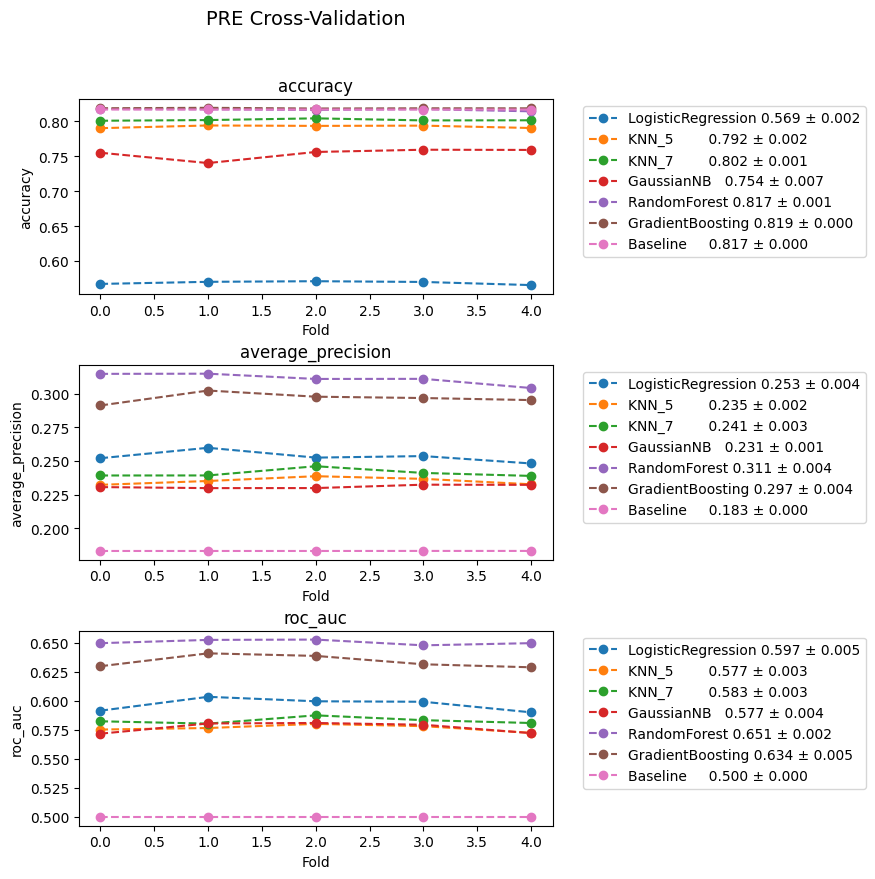



==================== POST CV RESULTS ====================


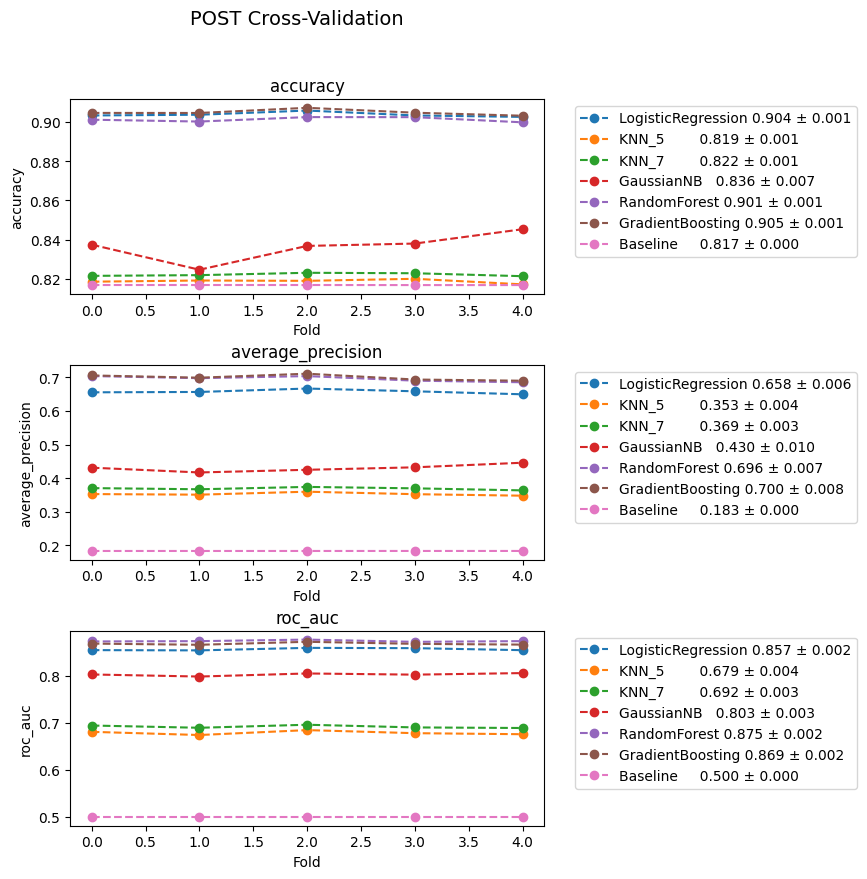

In [13]:
# Cross-Validation Performance for PRE + POST Classification

from sklearn.model_selection import cross_validate
import matplotlib.pyplot as plt
import numpy as np

msrs = ['accuracy', 'average_precision', 'roc_auc']             # metrics to evaluate

for ds_name, (Xtr_s, Xte_s, Xtr_o, Xte_o, y_train, y_test) in datasets.items():

    print(f"\n\n==================== {ds_name} CV RESULTS ====================")

    fig, axes = plt.subplots(len(msrs), 1, figsize=(6, 3*len(msrs)))  # one column per metric
    fig.suptitle(f"{ds_name} Cross-Validation", fontsize=14)
    fig.tight_layout(pad=3)

    for name, (kind, model) in models.items():

        X = Xtr_s if kind=="scaled" else Xtr_o                   # choose correct training features
        y = y_train                                              # labels

        cv_results = cross_validate(                             # run CV
            model,
            X, y,
            scoring=msrs,
            cv=5,
            return_train_score=False
        )

        for ax, msr in zip(axes, msrs):                          # loop metrics
            vals = cv_results["test_" + msr]                     # fold scores
            label = f"{name:12s} {vals.mean():.3f} ± {vals.std():.3f}"
            ax.plot(vals, 'o--', label=label)                    # plot fold scores
            ax.set_title(msr)                                    # metric title
            ax.set_xlabel("Fold")                                # x label
            ax.set_ylabel(msr)                                   # y label

    for ax in axes:
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')    # legend outside

    plt.show()


## Tuning
This cell defines three helper functions used to evaluate classification performance across different probability thresholds. The first computes precision, recall, and F1 at a single threshold. The second scans thresholds from 0 to 1 and records all metric values. The third selects the best threshold based on a chosen metric (precision, recall, or F1). Together, these functions allow flexible threshold tuning beyond the default 0.5 cutoff, which is especially useful for imbalanced classification tasks like ARR_DEL15.

In [14]:
import numpy as np                                              # numeric operations
from sklearn.metrics import precision_score, recall_score, f1_score  # metric functions

def metrics_at_threshold(y_true, probs, t):                     # compute metrics at threshold t
    preds = (probs >= t).astype(int)                            # convert probabilities to class labels
    precision = precision_score(y_true, preds, zero_division=0) # precision at threshold t
    recall = recall_score(y_true, preds, zero_division=0)       # recall at threshold t
    f1 = f1_score(y_true, preds, zero_division=0)               # f1 score at threshold t
    return precision, recall, f1                                # return tuple of metrics

def scan_thresholds(y_true, probs, steps=101):                  # scan thresholds from 0→1
    thresholds = np.linspace(0, 1, steps)                       # generate evenly spaced thresholds
    results = []                                                # store (t, precision, recall, f1)
    for t in thresholds:                                        # loop through thresholds
        p, r, f = metrics_at_threshold(y_true, probs, t)        # compute metrics at threshold t
        results.append((t, p, r, f))                            # append result tuple
    return results                                              # return list of results

def best_threshold(y_true, probs, metric="f1"):                 # find best threshold by metric
    idx = {"precision":1, "recall":2, "f1":3}[metric]           # index of metric in tuple
    results = scan_thresholds(y_true, probs)                    # compute metrics across thresholds
    return max(results, key=lambda x: x[idx])                   # return best (t,p,r,f)


This cell compares each model’s baseline performance to a tuned version that optimizes the decision threshold for F1. For models with probability outputs, I scan thresholds from 0–1 and pick the one that yields the highest F1 score. For models without probabilities, I use their default predictions. I then compare the tuned F1 against the baseline F1 from the earlier evaluation. Whichever version performs better becomes the final chosen model for that dataset (PRE or POST). All selected models, predictions, probabilities, and best thresholds are stored for later analysis.

Output:

Threshold tuning improved F1 for every model in both PRE and POST.
In PRE, the gains are large because baseline F1 scores were extremely low.
In POST, models were already strong, so tuning gives only small boosts, except KNN which improves more noticeably.

In [15]:
from sklearn.base import clone
from sklearn.metrics import f1_score

# store best threshold + best F1
best_thresholds = {"PRE": {}, "POST": {}}
best_f1_scores  = {"PRE": {}, "POST": {}}

# final chosen models (baseline OR tuned)
final_models   = {"PRE": {}, "POST": {}}
final_preds    = {"PRE": {}, "POST": {}}
final_probs    = {"PRE": {}, "POST": {}}

for ds, (Xtr_s, Xte_s, Xtr_o, Xte_o, ytr, yte) in datasets.items():
    if ds not in ["PRE", "POST"]:
        continue

    for model_name, (kind, base_model) in models.items():
        if model_name == "Baseline":
            continue

        # choose scaled or ordinal
        Xtr = Xtr_s if kind == "scaled" else Xtr_o
        Xte = Xte_s if kind == "scaled" else Xte_o

        # -----------------------------
        # 1. BASELINE PERFORMANCE
        # -----------------------------
        base_acc = class_baseline_metrics[ds][model_name]["test_acc"]
        base_model_obj = class_baseline_models[ds][model_name]
        base_preds = class_baseline_preds[ds][model_name]

        # baseline F1
        base_f1 = f1_score(yte, base_preds)

        # -----------------------------
        # 2. TUNED MODEL PERFORMANCE
        # -----------------------------
        model = clone(base_model)
        model.fit(Xtr, ytr)

        if hasattr(model, "predict_proba"):
            probs = model.predict_proba(Xte)[:, 1]

            # find best threshold
            t, p, r, f = best_threshold(yte, probs)

            tuned_f1 = f
            tuned_preds = (probs >= t).astype(int)

            best_thresholds[ds][model_name] = t
            best_f1_scores[ds][model_name]  = tuned_f1

        else:
            tuned_preds = model.predict(Xte)
            tuned_f1 = f1_score(yte, tuned_preds)

            best_thresholds[ds][model_name] = None
            best_f1_scores[ds][model_name]  = tuned_f1
            probs = None

        # -----------------------------
        # 3. COMPARE BASELINE vs TUNED
        # -----------------------------
        if tuned_f1 > base_f1:
            # tuned model wins
            final_models[ds][model_name] = model
            final_preds[ds][model_name]  = tuned_preds
            final_probs[ds][model_name]  = probs
            print(f"[{ds}] {model_name}: Tuned model selected (F1={tuned_f1:.4f} > baseline {base_f1:.4f})")

        else:
            # baseline model wins
            final_models[ds][model_name] = base_model_obj
            final_preds[ds][model_name]  = base_preds
            final_probs[ds][model_name]  = None
            print(f"[{ds}] {model_name}: Baseline model kept (F1={base_f1:.4f} >= tuned {tuned_f1:.4f})")


[PRE] LogisticRegression: Tuned model selected (F1=0.3279 > baseline 0.3188)
[PRE] KNN_5: Tuned model selected (F1=0.3240 > baseline 0.1634)
[PRE] KNN_7: Tuned model selected (F1=0.3242 > baseline 0.1283)
[PRE] GaussianNB: Tuned model selected (F1=0.3096 > baseline 0.1820)
[PRE] RandomForest: Tuned model selected (F1=0.3619 > baseline 0.1361)
[PRE] GradientBoosting: Tuned model selected (F1=0.3435 > baseline 0.0359)
[POST] LogisticRegression: Tuned model selected (F1=0.7344 > baseline 0.7319)
[POST] KNN_5: Tuned model selected (F1=0.4029 > baseline 0.2477)
[POST] KNN_7: Tuned model selected (F1=0.4183 > baseline 0.2093)
[POST] GaussianNB: Tuned model selected (F1=0.6329 > baseline 0.6282)
[POST] RandomForest: Tuned model selected (F1=0.7303 > baseline 0.7184)
[POST] GradientBoosting: Tuned model selected (F1=0.7345 > baseline 0.7344)


## CM Tuned Test
This cell visualizes the final chosen predictions for every model on both the PRE and POST datasets. For each stage, I generate an automatic grid of heatmaps—one per model—using the tuned or baseline‑selected predictions stored earlier. Each heatmap shows the confusion matrix with consistent labeling for “Late (1)” and “On Time (0).” This provides a clear, side‑by‑side view of how each model handles true positives, false positives, true negatives, and false negatives after threshold tuning and final model selection.

Output:

The PRE confusion matrices show that all models struggle to identify late flights, producing many false negatives and very few true positives. Predictions lean heavily toward “on time,” which matches the low recall and low F1 scores for the late class. In contrast, the POST confusion matrices show a clear improvement: models correctly capture far more late flights, with far fewer misses and much more balanced predictions. This shift reflects the strong predictive value added by DEP_DEL15, which allows POST models to separate late and on‑time flights much more effectively.



==================== PRE DATASET ====================


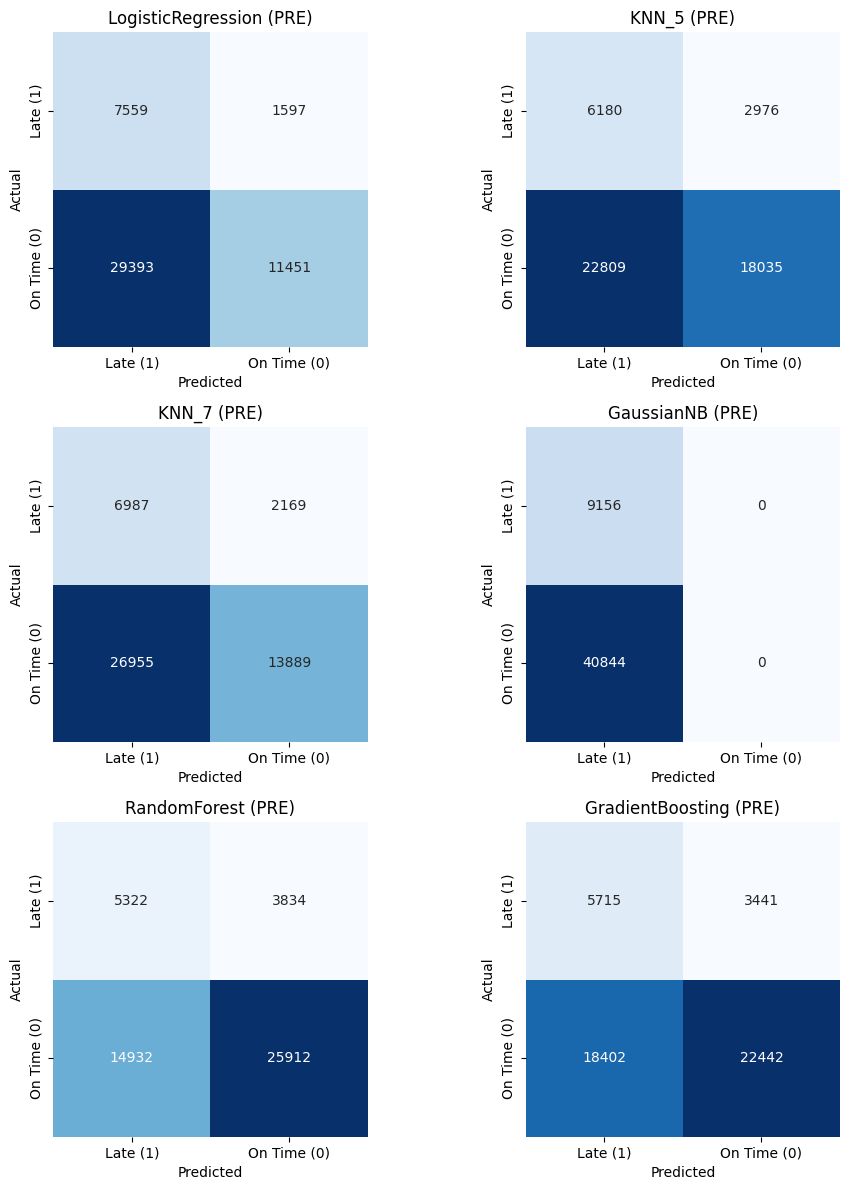



==================== POST DATASET ====================


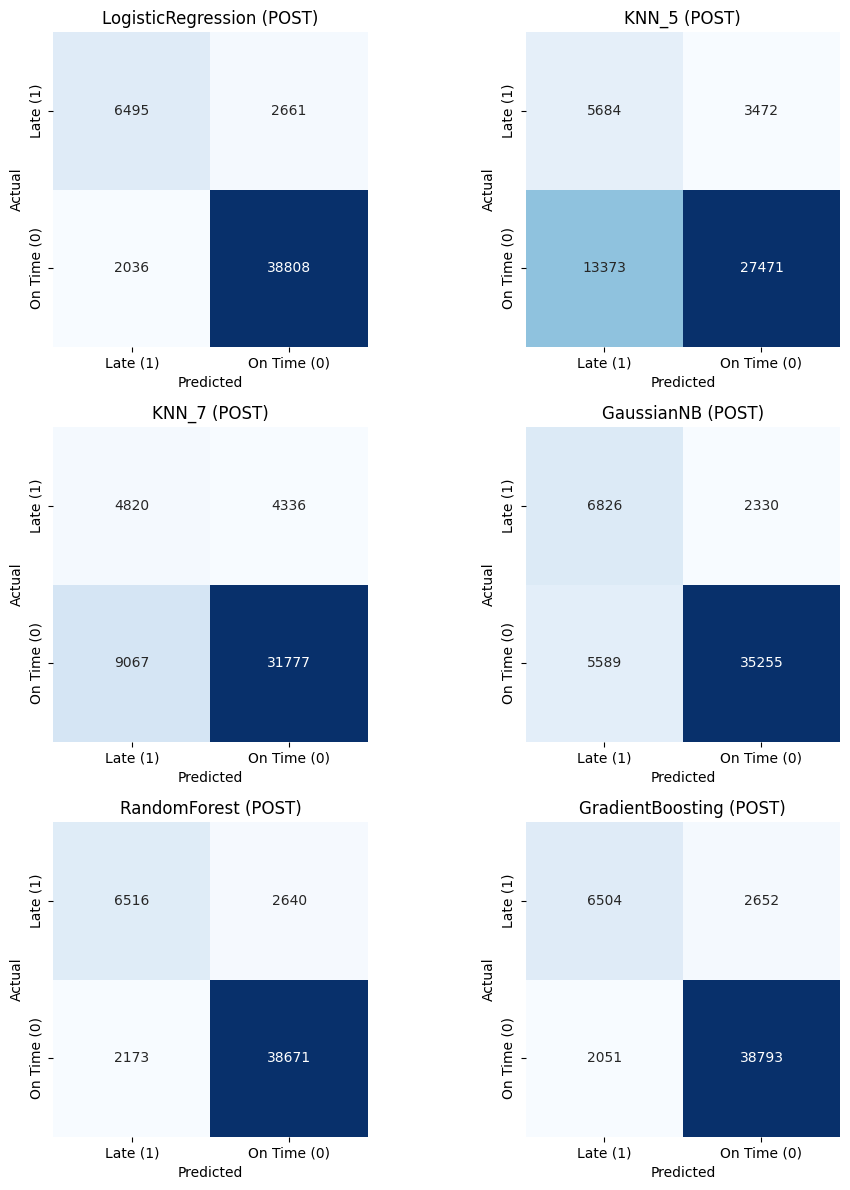

In [16]:
import math
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# CONFUSION MATRIX HEATMAPS FOR PRE + POST

for ds in ["PRE", "POST"]:
    print(f"\n\n==================== {ds} DATASET ====================")

    model_list = [m for m in models.keys() if m != "Baseline"]
    n_models = len(model_list)
    n_rows = math.ceil(n_models / 2)

    fig, axes = plt.subplots(n_rows, 2, figsize=(10, 4 * n_rows))
    axes = axes.flatten()

    for plot_idx, model_name in enumerate(model_list):

        # USE FINAL CHOSEN MODEL PREDICTIONS
        preds = final_preds[ds][model_name]
        yte   = datasets[ds][5]

        cm = confusion_matrix(yte, preds, labels=[1, 0])

        ax = axes[plot_idx]

        sns.heatmap(
            cm,
            annot=True,
            fmt='d',
            cmap="Blues",
            cbar=False,
            square=True,
            ax=ax,
            xticklabels=["Late (1)", "On Time (0)"],
            yticklabels=["Late (1)", "On Time (0)"]
        )

        ax.set_title(f"{model_name} ({ds})")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")

    plt.tight_layout()
    plt.show()


## Tuned ROC Curves
This cell plots ROC curves for all models that produce probability outputs, using the final tuned probabilities stored earlier. For each dataset (PRE and POST), I compute the false‑positive and true‑positive rates, calculate AUC values, and overlay all curves on a single plot. This gives a clear comparison of ranking performance across models and shows how well each one separates late vs. on‑time arrivals after threshold tuning and final model selection.

Output:

The PRE ROC curves show weak ranking performance across all models, with AUC values clustered around 0.57–0.65. This indicates that PRE models barely distinguish late from on‑time flights. In contrast, the POST ROC curves show a major improvement: LogisticRegression, RandomForest, and GradientBoosting reach AUC values between 0.86 and 0.88, reflecting strong separation between classes. Overall, POST models demonstrate far better discriminative ability than PRE models.



==================== PRE DATASET ====================


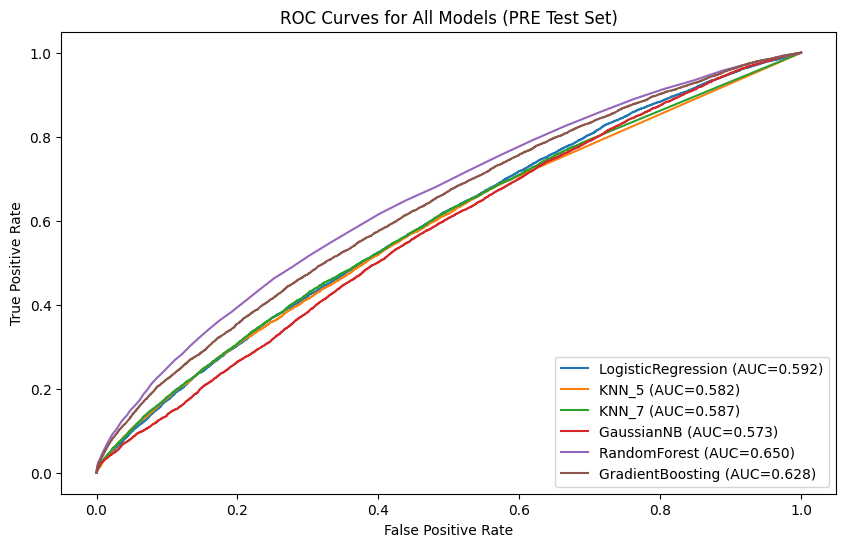



==================== POST DATASET ====================


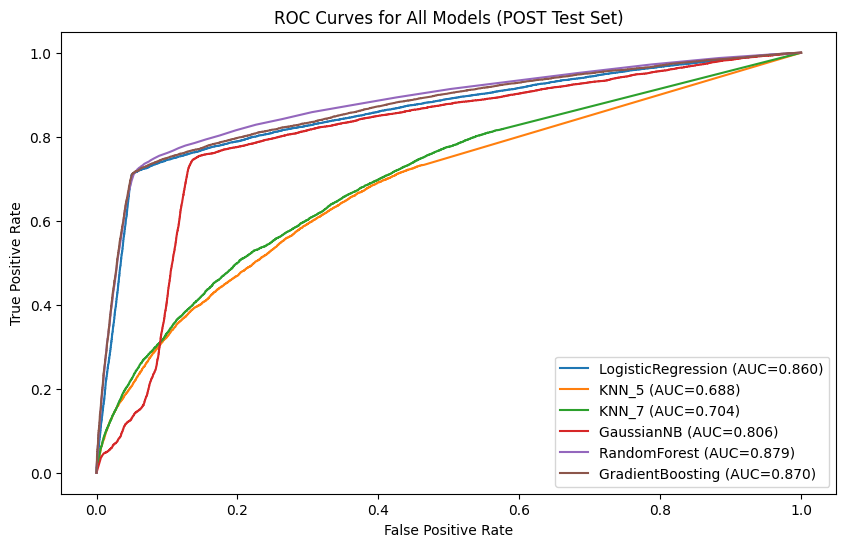

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

for ds in ["PRE", "POST"]:                                       # loop datasets
    print(f"\n\n==================== {ds} DATASET ====================")

    fig, ax = plt.subplots(figsize=(10, 6))                      # figure

    yte = datasets[ds][5]                                        # true labels

    for model_name, probs in final_probs[ds].items():            # loop stored probabilities
        if probs is None:                                        # skip models without proba
            continue

        fpr, tpr, _ = roc_curve(yte, probs)                      # compute ROC
        roc_auc = auc(fpr, tpr)                                  # compute AUC

        ax.plot(fpr, tpr, label=f"{model_name} (AUC={roc_auc:.3f})")  # plot curve

    ax.set_xlabel("False Positive Rate")                         # x‑label
    ax.set_ylabel("True Positive Rate")                          # y‑label
    ax.set_title(f"ROC Curves for All Models ({ds} Test Set)")   # title
    ax.legend(loc="lower right")                                 # legend

    plt.show()                                                   # display


## Tuned Test Precision-Recall Curves
The code loops through the PRE and POST datasets and generates precision–recall curves for every model. For each dataset, it retrieves the true test labels, then iterates over the stored predicted probabilities for each model. Using those probabilities, it computes the precision–recall curve and the corresponding PR‑AUC. Each model’s curve is plotted on the same figure with its AUC shown in the legend. The process repeats for both datasets, producing two plots that compare how well the models rank the positive class across PRE and POST.

Output:

The PRE curves show uniformly low precision and recall for late flights, with PR‑AUC values clustered around 0.23–0.31. This indicates that PRE models cannot reliably rank or identify the minority class. In POST, the curves shift sharply upward: LogisticRegression, RandomForest, and GradientBoosting achieve much higher PR‑AUC values between 0.66 and 0.70, reflecting strong precision–recall performance and far better detection of late flights once departure‑delay information is included.



==================== PRE DATASET ====================


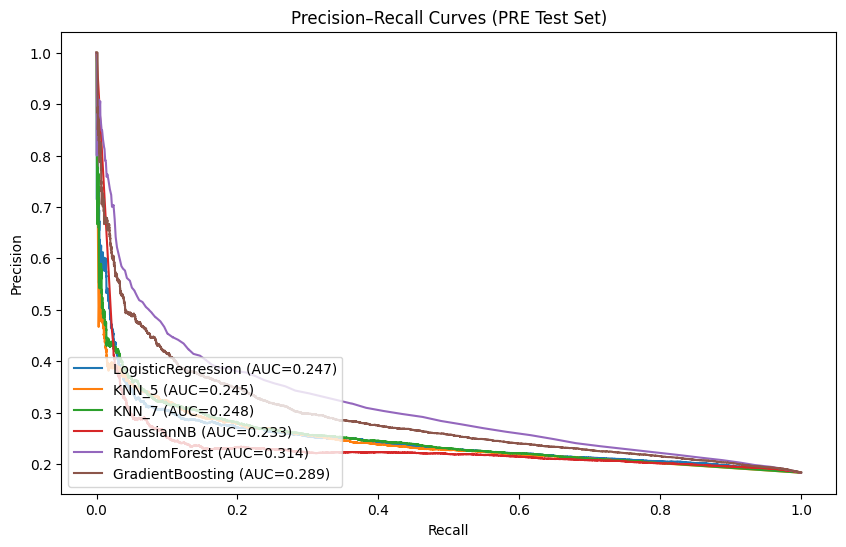



==================== POST DATASET ====================


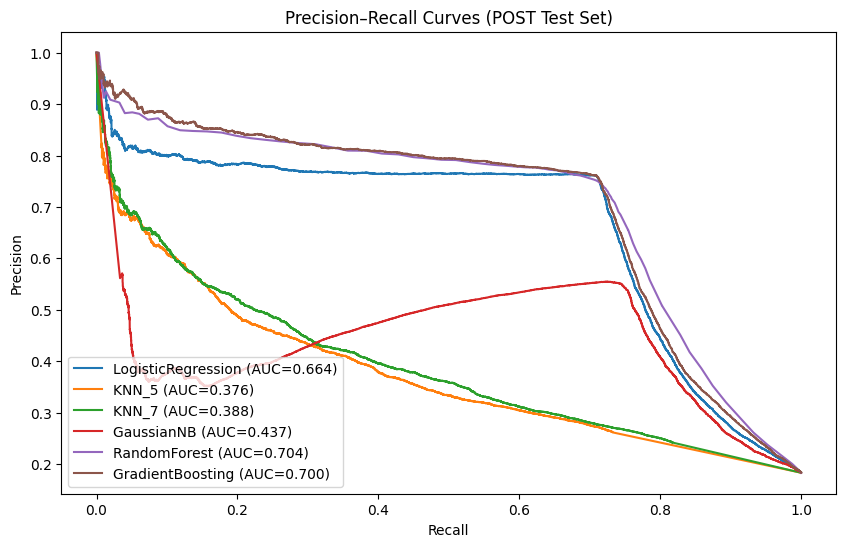

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc

for ds in ["PRE", "POST"]:                                       # loop datasets
    print(f"\n\n==================== {ds} DATASET ====================")

    fig, ax = plt.subplots(figsize=(10, 6))                      # figure

    yte = datasets[ds][5]                                        # true labels

    for model_name, probs in final_probs[ds].items():            # loop stored probabilities
        if probs is None:                                        # skip models without proba
            continue

        precision, recall, _ = precision_recall_curve(yte, probs)  # compute PR curve
        pr_auc = auc(recall, precision)                          # compute PR AUC

        ax.plot(recall, precision,                               # plot PR curve
                label=f"{model_name} (AUC={pr_auc:.3f})")        # label with AUC

    ax.set_xlabel("Recall")                                      # x‑label
    ax.set_ylabel("Precision")                                   # y‑label
    ax.set_title(f"Precision–Recall Curves ({ds} Test Set)")     # title
    ax.legend(loc="lower left")                                  # legend

    plt.show()                                                   # display


## Random Forest Feature Importance

The code loops through each dataset (PRE and POST) and trains a new Random Forest classifier on the ordinal‑encoded features. After the model is fitted, its feature importances are extracted and sorted in descending order to highlight which predictors contribute most to the model’s decisions. The sorted importances are then visualized as a horizontal bar chart, with the axis flipped so the most influential features appear at the top. This process is repeated for both datasets to compare how the importance patterns differ between PRE and POST.

Output:

The PRE feature‑importance ranking shows that no single predictor strongly drives model performance. Importance is spread thinly across distance, basic weather readings, calendar fields, and airport identifiers. The top features contribute only modestly, and the long tail of very low‑importance variables reflects the weak predictive signal in the PRE dataset. This diffuse pattern aligns with the poor precision, recall, and F1 you observed earlier: without departure‑delay information, the model has no dominant feature to anchor reliable late‑flight predictions.

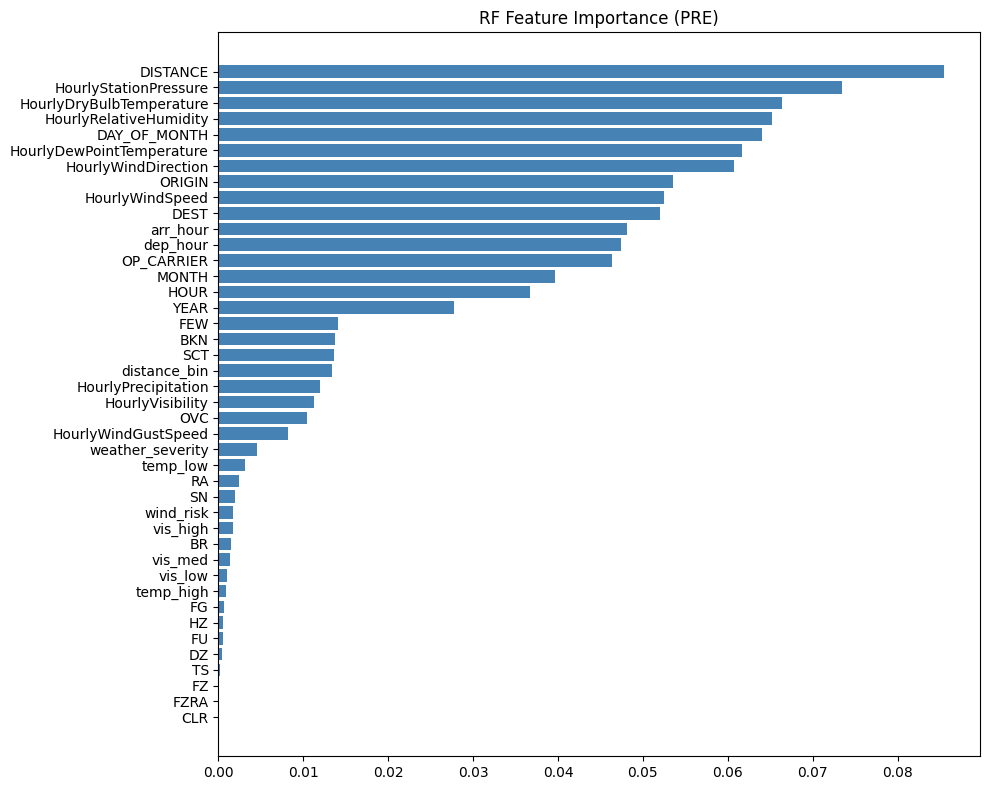

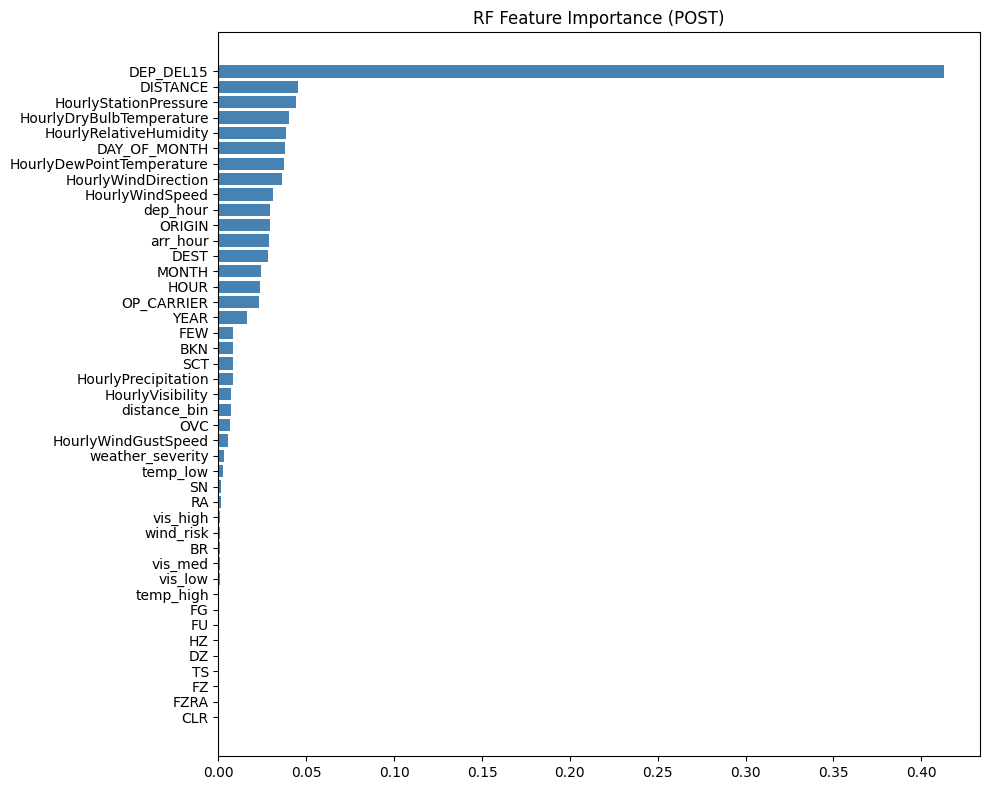

In [19]:
from sklearn.ensemble import RandomForestClassifier               # RF classifier
import matplotlib.pyplot as plt
import numpy as np

def sort_imp(model, cols):                                        # sort helper
    imp = model.feature_importances_                              # raw importances
    idx = np.argsort(imp)[::-1]                                   # descending order
    return cols[idx], imp[idx]                                    # sorted names + values

for ds, (Xtr_s, Xte_s, Xtr_o, Xte_o, ytr, yte) in datasets.items():   # loop PRE/POST
    rf = RandomForestClassifier(n_estimators=300,                 # RF model
                                random_state=42,
                                n_jobs=-1).fit(Xtr_o, ytr)        # fit on ordinal features

    f_sorted, i_sorted = sort_imp(rf, Xtr_o.columns)              # sorted importances

    plt.figure(figsize=(10,8))                                    # create figure
    plt.barh(f_sorted, i_sorted, color='steelblue')               # horizontal bar plot
    plt.gca().invert_yaxis()                                      # highest at top
    plt.title(f"RF Feature Importance ({ds})")                    # dataset title
    plt.tight_layout()                                            # clean layout
    plt.show()                                                    # display plot


## Model Comparisons (Before and After Tuning)

The code defines a helper function that computes baseline and tuned F1 scores for every model in a given dataset. It retrieves the true test labels, loops through each model, calculates the F1 score for the baseline predictions and the final tuned predictions, and returns the results. Using this function, the code generates two bar charts—one for PRE and one for POST—where baseline and tuned F1 scores are plotted side‑by‑side for each model. This makes it easy to compare how much tuning improves performance in each dataset.

Output:

The charts show a clear pattern: tuning consistently improves model performance, but the size of the improvement depends on the dataset. In the PRE dataset, all models start with low F1 scores, and tuning produces noticeable gains across every algorithm. In the POST dataset, most models already perform well, so tuning only makes small adjustments, with the KNN models showing the most visible improvement. Overall, tuning is impactful when the signal is weak and mostly incremental when the dataset is already easy to classify.


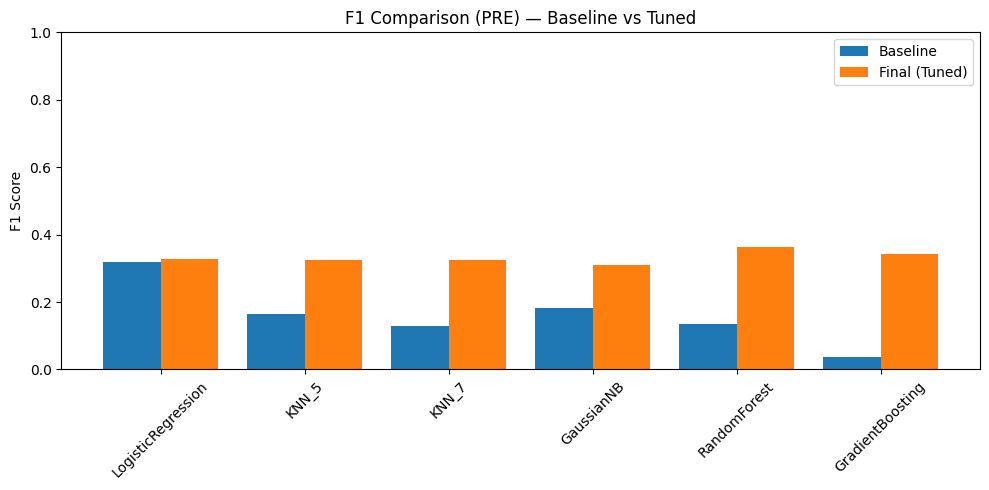

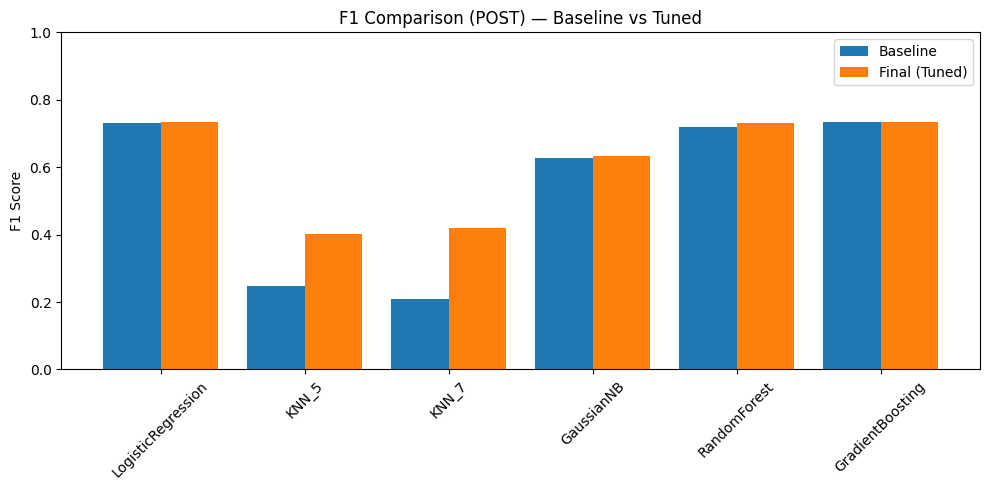

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

def f1_for_all(ds):
    y_true = datasets[ds][5]  # y_test
    baseline_scores = []
    final_scores = []
    model_names = []

    for model_name in final_preds[ds].keys():
        # baseline predictions
        base_preds = class_baseline_preds[ds][model_name]
        base_f1 = f1_score(y_true, base_preds)

        # final predictions (baseline or tuned)
        final_preds_ds = final_preds[ds][model_name]
        final_f1 = f1_score(y_true, final_preds_ds)

        model_names.append(model_name)
        baseline_scores.append(base_f1)
        final_scores.append(final_f1)

    return model_names, baseline_scores, final_scores


# --- PRE ---
pre_models, pre_base, pre_final = f1_for_all("PRE")

plt.figure(figsize=(10,5))
x = range(len(pre_models))
plt.bar([i - 0.2 for i in x], pre_base,  width=0.4, label="Baseline", color="#1f77b4")
plt.bar([i + 0.2 for i in x], pre_final, width=0.4, label="Final (Tuned)", color="#ff7f0e")
plt.xticks(x, pre_models, rotation=45)
plt.ylabel("F1 Score")
plt.title("F1 Comparison (PRE) — Baseline vs Tuned")
plt.ylim(0,1)
plt.legend()
plt.tight_layout()
plt.show()


# --- POST ---
post_models, post_base, post_final = f1_for_all("POST")

plt.figure(figsize=(10,5))
x = range(len(post_models))
plt.bar([i - 0.2 for i in x], post_base,  width=0.4, label="Baseline", color="#1f77b4")
plt.bar([i + 0.2 for i in x], post_final, width=0.4, label="Final (Tuned)", color="#ff7f0e")
plt.xticks(x, post_models, rotation=45)
plt.ylabel("F1 Score")
plt.title("F1 Comparison (POST) — Baseline vs Tuned")
plt.ylim(0,1)
plt.legend()
plt.tight_layout()
plt.show()


## Time and Resource Consumption (Training and Predictions)

This code measures how expensive each model is to train and run by timing both phases and tracking their memory usage. For every model in the PRE and POST datasets, it creates a fresh clone, selects the correct feature set, and records how long training takes along with the peak memory allocated during that process. It then does the same for prediction, capturing the time required to generate outputs and the memory consumed while doing so. The result is a clear, repeatable benchmark showing the computational cost of each model across both datasets.

Output:

Logistic Regression trains slowly but predicts almost instantly, with moderate memory use in both phases. KNN models are extremely cheap to train but very expensive at prediction time, taking more than 37 seconds per run and using the highest prediction‑phase memory. GaussianNB is the lightest model overall, with minimal time and memory for both training and prediction. Random Forest and Gradient Boosting are the heaviest during training, with long runtimes and substantial memory usage, but their prediction times are fast and stable. The POST dataset behaves almost identically to PRE, showing that computational cost is driven more by the model type than by the dataset.

In [21]:
import time                                                      # measure timing
import tracemalloc                                               # measure memory

for ds in ["PRE", "POST"]:                                       # loop through datasets
    print(f"\n\n==================== {ds} DATASET ====================")  # dataset header

    for model_name, (kind, base_model) in models.items():        # loop through all models
        if model_name == "Baseline":                             # skip baseline
            continue                                             # continue loop

        print(f"\n=== {model_name} ===")                         # model header

        model = clone(base_model)                                # fresh untrained model clone

        Xtr = datasets[ds][0] if kind=="scaled" else datasets[ds][2]  # pick train set
        Xte = datasets[ds][1] if kind=="scaled" else datasets[ds][3]  # pick test set
        ytr = datasets[ds][4]                                     # train labels
        yte = datasets[ds][5]                                     # test labels

        tracemalloc.start()                                      # start memory tracking for training
        t0 = time.time()                                         # start training timer

        model.fit(Xtr, ytr)                                      # train model

        train_time = time.time() - t0                            # compute training time
        cur, peak = tracemalloc.get_traced_memory()              # read memory snapshot
        tracemalloc.stop()                                       # stop memory tracking

        mem_train = peak / (1024**2)                             # convert bytes → MiB

        print("Training:")                                       # training section header
        print(f"  Time        : {train_time:.6f} sec")           # print training time
        print(f"  Memory Used : {mem_train:.4f} MiB")            # print training memory

        tracemalloc.start()                                      # start memory tracking for prediction
        t0 = time.time()                                         # start prediction timer

        preds = model.predict(Xte)                               # run prediction

        pred_time = time.time() - t0                             # compute prediction time
        cur, peak = tracemalloc.get_traced_memory()              # read memory snapshot
        tracemalloc.stop()                                       # stop memory tracking

        mem_pred = peak / (1024**2)                              # convert bytes → MiB

        print("Prediction:")                                     # prediction section header
        print(f"  Time        : {pred_time:.6f} sec")            # print prediction time
        print(f"  Memory Used : {mem_pred:.4f} MiB")             # print prediction memory




==================== PRE DATASET ====================

=== LogisticRegression ===
Training:
  Time        : 13.703766 sec
  Memory Used : 96.1349 MiB
Prediction:
  Time        : 0.014510 sec
  Memory Used : 16.7869 MiB

=== KNN_5 ===
Training:
  Time        : 0.052932 sec
  Memory Used : 96.1341 MiB
Prediction:
  Time        : 57.170699 sec
  Memory Used : 32.0464 MiB

=== KNN_7 ===
Training:
  Time        : 0.059288 sec
  Memory Used : 96.1346 MiB
Prediction:
  Time        : 56.419110 sec
  Memory Used : 32.0464 MiB

=== GaussianNB ===
Training:
  Time        : 0.118369 sec
  Memory Used : 126.6619 MiB
Prediction:
  Time        : 0.030578 sec
  Memory Used : 48.5113 MiB

=== RandomForest ===
Training:
  Time        : 32.260070 sec
  Memory Used : 72.1019 MiB
Prediction:
  Time        : 2.063003 sec
  Memory Used : 24.0361 MiB

=== GradientBoosting ===
Training:
  Time        : 40.385567 sec
  Memory Used : 72.1021 MiB
Prediction:
  Time        : 0.110849 sec
  Memory Used : 24.0360 

## Conclusion for Classification

Across the two datasets the classification results show a clear shift in how much structure the models can actually learn. PRE does not give them enough information to separate the classes in a reliable way, so performance stays close to the baseline and anything that looks good in training does not carry over to the test set. Once you move into POST the models finally have enough signal to form real class boundaries. Accuracy, precision, recall, and f1 all improve, and the stronger models start to pull ahead while the weaker ones fall off. Gradient Boosting and Random Forest both become much more dependable here, while KNN continues to overfit and Logistic Regression stays limited by the lack of clean linear separation.

From this group I would choose Gradient Boosting as the final classification model. It is the most consistent across both datasets, it avoids the heavy overfitting you see in KNN, and it handles complex decision boundaries without needing much tuning.


## Data Dictionary
Data Dictionary that was part of the Seattle Flight Delay Dataset

## Flight Information Features

| COL_NAME | DATA_TYPE | DESCRIPTION |
|----------|-----------|-------------|
| YEAR | Integer | Year of flight departure (2018, 2019, 2022, or 2023) |
| MONTH | Integer | Month of flight departure (1-12) |
| DAY_OF_MONTH | Integer | Day of month for flight departure (1-31) |
| HOUR | Integer | Hour of scheduled departure in 24-hour format (0-23), local time |
| OP_CARRIER | String | Airline carrier code (IATA 2-letter code, e.g., AS for Alaska Airlines, DL for Delta) |
| ORIGIN | String | Origin airport code (IATA 3-letter code) |
| DEST | String | Destination airport code (IATA 3-letter code) |
| CRS_DEP_TIME | Integer | Scheduled departure time (local time, 24-hour format, e.g., 1430 = 2:30 PM) |
| CRS_ARR_TIME | Integer | Scheduled arrival time (local time, 24-hour format) |
| DISTANCE | Float | Distance between origin and destination airports in miles |
| TAIL_NUM | String | Aircraft tail number (unique identifier for specific aircraft) |
| IS_HOLIDAY | Binary | Binary indicator (0 or 1) for whether the flight date falls on or near a U.S. federal holiday |

## Weather Features (NOAA LCD Data)

| COL_NAME | DATA_TYPE | DESCRIPTION |
|----------|-----------|-------------|
| HourlyDewPointTemperature | Float | Dew point temperature in degrees Fahrenheit at Sea-Tac Airport. Temperature to which air must be cooled to become saturated with water vapor |
| HourlyDryBulbTemperature | Float | Ambient air temperature in degrees Fahrenheit at Sea-Tac Airport, measured by standard thermometer |
| HourlyPrecipitation | Float | Liquid precipitation amount in inches accumulated over the past hour. 'T' indicates trace amount (< 0.005 inches) |
| HourlyRelativeHumidity | Integer | Relative humidity as a percentage (0-100), indicating the amount of moisture in the air relative to maximum capacity at current temperature |
| HourlyStationPressure | Float | Atmospheric pressure in inches of mercury (inHg) measured at station elevation (not adjusted to sea level) |
| HourlyVisibility | Float | Horizontal visibility distance in statute miles. Distance at which objects can be seen and identified |
| HourlyWindDirection | Integer | Wind direction in degrees (0-360) indicating the direction FROM which wind is blowing (e.g., 270 = wind from west) |
| HourlyWindGustSpeed | Float | Peak wind gust speed in miles per hour during the observation hour. May be null if no gusts occurred |
| HourlyWindSpeed | Float | Sustained wind speed in miles per hour, averaged over the observation period |

## Weather Type Indicators (Present Weather)

These are binary (0/1) flags indicating whether specific weather phenomena were observed during the hour. Derived from METAR weather codes.

| COL_NAME | DATA_TYPE | DESCRIPTION |
|----------|-----------|-------------|
| RA | Binary | Rain present (1 = yes, 0 = no) |
| FG | Binary | Fog present - visibility significantly reduced by water droplets |
| SN | Binary | Snow present |
| BR | Binary | Mist present - visibility 5/8 to 6 miles due to water droplets |
| FZ | Binary | Freezing conditions present (freezing rain, freezing drizzle, or freezing fog) |
| HZ | Binary | Haze present - visibility reduced by dry particles (dust, smoke, pollution) |
| DZ | Binary | Drizzle present - light liquid precipitation with drops smaller than rain |
| FZRA | Binary | Freezing rain present - supercooled rain that freezes on contact with surfaces |
| TS | Binary | Thunderstorm present or in vicinity |
| FU | Binary | Smoke present - visibility reduced by combustion products |

## Sky Cover Indicators (Cloud Coverage)

Binary indicators for cloud coverage categories based on METAR sky condition codes. Multiple categories can be true simultaneously for different cloud layers.

| COL_NAME | DATA_TYPE | DESCRIPTION |
|----------|-----------|-------------|
| CLR | Binary | Clear skies - no clouds detected below 12,000 feet by automated sensors |
| FEW | Binary | Few clouds - 1/8 to 2/8 sky coverage (1-2 oktas) |
| SCT | Binary | Scattered clouds - 3/8 to 4/8 sky coverage (3-4 oktas) |
| BKN | Binary | Broken clouds - 5/8 to 7/8 sky coverage (5-7 oktas). Constitutes a cloud ceiling |
| OVC | Binary | Overcast - 8/8 complete sky coverage. Constitutes a cloud ceiling |

## Cloud Layer Heights

Heights of cloud layers in hundreds of feet above ground level (AGL), derived from METAR observations.

| COL_NAME | DATA_TYPE | DESCRIPTION |
|----------|-----------|-------------|
| Layer1 Height | Float | Height of lowest cloud layer in hundreds of feet AGL. Null if no clouds present |
| Layer2 Height | Float | Height of second cloud layer in hundreds of feet AGL. Null if fewer than 2 layers present |
| Layer3 Height | Float | Height of third cloud layer in hundreds of feet AGL. Null if fewer than 3 layers present |

## Target Variables (⚠️ POTENTIAL LEAKAGE)

| COL_NAME | DATA_TYPE | DESCRIPTION |
|----------|-----------|-------------|
| DEP_DEL15 | Binary | **Departure delay indicator**: 1 if departure delayed ≥15 minutes, 0 otherwise. Safe to use as target for departure delay prediction |
| ARR_DEL15 | Binary | **Arrival delay indicator**: 1 if arrival delayed ≥15 minutes, 0 otherwise. Safe to use as target for arrival delay prediction |
| DEP_DELAY | Float | **⚠️ LEAKAGE RISK**: Actual departure delay in minutes (negative = early). Contains information not available at prediction time for departure scenarios |
| ARR_DELAY | Float | **⚠️ LEAKAGE RISK**: Actual arrival delay in minutes (negative = early). Contains information not available at prediction time. May include departure delay effects |

---

## Important Notes

### Weather Data Timing
- For **outbound flights** (departing Seattle): Weather data corresponds to conditions at Sea-Tac at scheduled departure time
- For **inbound flights** (arriving at Seattle): Weather data corresponds to conditions at Sea-Tac at scheduled arrival time
- Weather is ALWAYS measured at Seattle-Tacoma International Airport (KSEA), never at destination/origin airports

### Target Leakage Warning
The dataset explicitly includes features that can cause target leakage:
- **DEP_DELAY** and **ARR_DELAY** contain actual realized delays
- For predictive modeling, use **DEP_DEL15** or **ARR_DEL15** as targets
- Do NOT use DEP_DELAY or ARR_DELAY as features when predicting delays
- Be cautious with time-based train/test splits - use proper temporal validation

### Data Coverage
- Years: 2018-2019 and 2022-2023 (2020-2021 excluded)
- Only flights with Seattle-Tacoma International (SEA) as origin OR destination
- Weather observations may have missing values due to sensor failures or maintenance

### Missing Values
- Null/missing values may appear in weather features during sensor downtime
- Cloud layer heights are null when no clouds are present at that layer
- Wind gust speed is null when no gusts were recorded

---

## Data Sources

**Flight Data:**  
Bureau of Transportation Statistics. (2024). Airline On-Time Performance Data. U.S. Department of Transportation. https://www.transtats.bts.gov/

**Weather Data:**  
National Oceanic and Atmospheric Administration. (2024). Local Climatological Data: Seattle Tacoma International Airport. National Centers for Environmental Information. https://www.ncei.noaa.gov/products/land-based-station/local-climatological-data

# Regression Report

## Dataset Background
The regression track uses a dataset derived from the Flight Delay Dataset 2018–2024, focused on predicting ArrDelayMinutes, the actual number of minutes a flight arrives late. The data includes operational, scheduling, and weather‑related features, giving the models enough context to learn patterns behind continuous delay outcomes.

The workflow is split into PRE, PUSH, and POST stages. PRE removes DepDelayMinutes, forcing the models to work without the strongest predictor. PUSH also excludes it but switches the target to NetDelay to model the portion of delay not explained by departure delay. POST restores DepDelayMinutes and returns to predicting ArrDelayMinutes, representing the full‑information scenario.

This structure makes it easy to compare how the models behave with limited features, engineered targets, and complete operational context.

## Data Loading
This cell loads the regression dataset by streaming a gzipped CSV directly from GitHub into a pandas DataFrame. The compression='gzip' argument lets pandas handle decompression automatically, which keeps the workflow simple and avoids any manual file handling. After loading, the first few rows are printed to confirm the file read correctly and to get a quick look at the columns and data types before preprocessing. The final shape check acts as a quick sanity step to make sure the file wasn’t truncated or corrupted during the read.

In [22]:
import pandas as pd

# URL pointing to the gzipped CSV file stored in the GitHub repository.
# Using the raw link allows pandas to stream the file directly without manual download.
url = "https://github.com/elesende/Portfolio.github.io/raw/refs/heads/main/flight_delay_100k_regression.csv.gz"

# Read the compressed CSV into a DataFrame.
# 'compression=gzip' tells pandas to decompress the file on the fly.
# This avoids having to manually unzip the file and keeps the workflow reproducible.
df = pd.read_csv(url, compression='gzip')

# Display the first few rows to verify that the file loaded correctly,
# confirm column names, and inspect data types before any preprocessing.
print("First 5 rows of the dataset:")
display(df.head())

# Print the dataset dimensions to confirm the expected number of rows and columns.
# This acts as a quick sanity check to ensure the file wasn't truncated or corrupted.
print(f"\nDataset shape: {df.shape[0]} rows x {df.shape[1]} columns")


/tmp/ipykernel_1548/2745768850.py:10: DtypeWarning: Columns (11,13,86,93) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url, compression='gzip')


First 5 rows of the dataset:


,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Marketing_Airline_Network,Operated_or_Branded_Code_Share_Partners,DOT_ID_Marketing_Airline,IATA_Code_Marketing_Airline,...,Div5Airport,Div5AirportID,Div5AirportSeqID,Div5WheelsOn,Div5TotalGTime,Div5LongestGTime,Div5WheelsOff,Div5TailNum,Duplicate,Unnamed: 119
0,2024,1,1,18,4,2024-01-18,DL,DL_CODESHARE,19790,DL,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN
1,2024,1,1,17,3,2024-01-17,AS,AS,19930,AS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN
2,2024,1,1,24,3,2024-01-24,AA,AA,19805,AA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN
3,2024,1,1,20,6,2024-01-20,WN,WN,19393,WN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN
4,2024,1,1,2,2,2024-01-02,NK,NK,20416,NK,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN



Dataset shape: 100000 rows x 120 columns


## Feature Identification
This cell gives a quick read on the raw numeric features in the regression dataset. It pulls out all numeric columns, checks how each one correlates with ArrDelayMinutes, and calculates their variance. Then it puts everything into a table sorted by correlation. It’s a simple way to see which features actually carry signal and which ones don’t before doing any preprocessing or feature engineering.

In [23]:
# === Raw Feature Screening ===

import pandas as pd
import numpy as np

# Identify numeric columns in the raw dataset
raw_numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Compute correlation with ArrDelayMinutes (regression target)
if 'ArrDelayMinutes' in df.columns:
    corr_with_target = df[raw_numeric_cols].corrwith(df['ArrDelayMinutes'])
else:
    corr_with_target = pd.Series(dtype=float)

# Compute variance of each numeric feature
variance = df[raw_numeric_cols].var()

# Assemble numeric summary table
raw_numeric_summary = pd.DataFrame({
    'CorrelationWithArrDelayMinutes': corr_with_target,
    'Variance': variance
}).sort_values('CorrelationWithArrDelayMinutes', ascending=False)

print("Raw regression feature screening complete.")
display(raw_numeric_summary)


/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Raw regression feature screening complete.


,CorrelationWithArrDelayMinutes,Variance
ArrDelayMinutes,1.0000,"4,195.7109"
ArrDelay,0.9886,"4,654.1324"
DepDelayMinutes,0.9826,"4,167.0906"
DepDelay,0.9804,"4,302.4177"
ArrivalDelayGroups,0.7636,7.6706
...,...,...
Div5TotalGTime,NaN,NaN
Div5LongestGTime,NaN,NaN
Div5WheelsOff,NaN,NaN
Div5TailNum,NaN,NaN


## Data Cleaning
This cell filters the regression dataset down to the base features that actually matter for the next steps. It keeps the target, the delay‑cause columns needed for feature engineering, the core schedule and route fields, the airline identifiers, and a few operational indicators like TaxiOut and DepDelay. Anything not in that list gets dropped. After filtering, the cell prints the columns that were kept and the new shape of the DataFrame so it’s easy to confirm that the dataset now contains only the meaningful starting features.

In [24]:
# === Cell 1 Keep Only Meaningful Base Features (Including Delay Cause Columns for Engineering) ===

valid_features = [
    # Target
    "ArrDelayMinutes",

    # Delay cause components (used ONLY for feature engineering)
    "CarrierDelay", "WeatherDelay", "NASDelay",
    "LateAircraftDelay", "SecurityDelay",

    # Schedule
    "CRSDepTime", "CRSArrTime", "CRSElapsedTime",
    "DayOfWeek", "DayofMonth", "Month", "Quarter", "Year",

    # Route
    "Distance", "DistanceGroup",
    "OriginWac", "DestWac",
    "OriginStateFips", "DestStateFips",

    # Airline identifiers
    "DOT_ID_Marketing_Airline", "DOT_ID_Operating_Airline",

    # Delay indicators
    "ArrDel15", "DepDel15",

    # Post-pushback
    "TaxiOut",

    # Post-takeoff
    "DepDelay", "DepDelayMinutes", "WheelsOff"
]

# Keep only columns that exist
valid_features = [c for c in valid_features if c in df.columns]

df = df[valid_features].copy()

print("Columns kept:")
print(df.columns.tolist())
print(f"\nShape: {df.shape}")


Columns kept:
['ArrDelayMinutes', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'LateAircraftDelay', 'SecurityDelay', 'CRSDepTime', 'CRSArrTime', 'CRSElapsedTime', 'DayOfWeek', 'DayofMonth', 'Month', 'Quarter', 'Year', 'Distance', 'DistanceGroup', 'OriginWac', 'DestWac', 'OriginStateFips', 'DestStateFips', 'DOT_ID_Marketing_Airline', 'DOT_ID_Operating_Airline', 'ArrDel15', 'DepDel15', 'TaxiOut', 'DepDelay', 'DepDelayMinutes', 'WheelsOff']

Shape: (100000, 28)


This cell checks the dataset for missing values. It prints the raw count of NaNs for each column and then shows the percentage missing so it’s easy to see which features are clean and which ones might need attention. It’s a quick way to confirm the overall completeness of the regression dataset before moving on to any preprocessing.

In [25]:
# === Cell 2 Missing value inspection ===

print("\nMissing values per column:")         # show raw count of missing entries for each feature
print(df.isna().sum())                        # .sum() returns total NaNs per column

print("\nPercent missing:")                   # show missingness as a percentage for easier interpretation
print(df.isna().mean() * 100)                 # .mean() gives fraction of NaNs; multiply by 100 for %


Missing values per column:
ArrDelayMinutes              4144
CarrierDelay                76825
WeatherDelay                76825
NASDelay                    76825
LateAircraftDelay           76825
SecurityDelay               76825
CRSDepTime                      0
CRSArrTime                      0
CRSElapsedTime                  0
DayOfWeek                       0
DayofMonth                      0
Month                           0
Quarter                         0
Year                            0
Distance                        0
DistanceGroup                   0
OriginWac                       0
DestWac                         0
OriginStateFips                 0
DestStateFips                   0
DOT_ID_Marketing_Airline        0
DOT_ID_Operating_Airline        0
ArrDel15                     4144
DepDel15                     3741
TaxiOut                      3811
DepDelay                     3741
DepDelayMinutes              3741
WheelsOff                    3811
dtype: int64

Percen

This cell handles missing‑value cleanup for the regression dataset. It first checks which columns have more than 10% missing data and drops them. After that, it removes any remaining rows that still contain NaNs. Finally, it prints the columns that survived, the percent missing after cleanup, and the new shape of the dataset. It’s a straightforward way to make sure the data is fully clean before moving on to feature engineering or modeling.

In [26]:
# === Cell 3 Drop Columns With >10% Missing, Then Drop Rows With Any Missing ===

# Percent missing per column
missing_percent = df.isna().mean() * 100

# Columns exceeding 10% missing
cols_to_drop = missing_percent[missing_percent > 10].index.tolist()

print(f"Columns dropped (>10% missing): {len(cols_to_drop)}")
print(cols_to_drop)

# Drop those columns
df = df.drop(columns=cols_to_drop)

# Drop any rows that still contain missing values
rows_before = df.shape[0]
df = df.dropna()
rows_after = df.shape[0]

print(f"\nRows dropped due to remaining missing values: {rows_before - rows_after}")

# Final dataset summary
print("\nRemaining columns and percent missing:")
print((df.isna().mean() * 100).round(3))

print(f"\nNew shape: {df.shape}")


Columns dropped (>10% missing): 5
['CarrierDelay', 'WeatherDelay', 'NASDelay', 'LateAircraftDelay', 'SecurityDelay']

Rows dropped due to remaining missing values: 4144

Remaining columns and percent missing:
ArrDelayMinutes                          0.0000
CRSDepTime                               0.0000
CRSArrTime                               0.0000
CRSElapsedTime                           0.0000
DayOfWeek                                0.0000
DayofMonth                               0.0000
Month                                    0.0000
Quarter                                  0.0000
Year                                     0.0000
Distance                                 0.0000
DistanceGroup                            0.0000
OriginWac                                0.0000
DestWac                                  0.0000
OriginStateFips                          0.0000
DestStateFips                            0.0000
DOT_ID_Marketing_Airline                 0.0000
DOT_ID_Operating_Airlin

## Feature Matrix and Train/Test Split

This cell builds the raw feature sets for the three regression stages and creates the targets they use. It starts by defining the feature lists for the pre‑flight, post‑pushback, and post‑takeoff models based on what information is actually available at each point in the flight timeline. After filtering those lists to keep only the columns that exist in the dataset, it creates the three raw feature matrices. The cell also creates the two targets: ArrDelayMinutes for the pre‑flight and post‑takeoff models, and NetDelay for the post‑pushback model. Finally, it prints the shapes and feature lists so it’s easy to confirm that each stage has the correct inputs and targets before moving on to preprocessing and modeling.

In [27]:
# === Cell 4 Build Raw Feature Sets + Create Targets ===

# --- PRE-FLIGHT MODEL (before pushback) ---
pre_flight_features = [
    "CRSDepTime", "CRSArrTime", "CRSElapsedTime",
    "DayOfWeek", "DayofMonth", "Month", "Quarter", "Year",
    "Distance", "DistanceGroup",
    "OriginWac", "DestWac",
    "OriginStateFips", "DestStateFips",
    "DOT_ID_Marketing_Airline", "DOT_ID_Operating_Airline",
    "ArrDel15", "DepDel15"
]

pre_flight_features = [f for f in pre_flight_features if f in df.columns]


# --- POST-PUSHBACK MODEL (TaxiOut becomes known) ---
post_pushback_features = pre_flight_features + ["TaxiOut"]
post_pushback_features = [f for f in post_pushback_features if f in df.columns]


# --- POST-TAKEOFF MODEL (DepDelay + WheelsOff become known) ---
post_takeoff_features = post_pushback_features + [
    "DepDelay", "DepDelayMinutes", "WheelsOff"
]
post_takeoff_features = [f for f in post_takeoff_features if f in df.columns]


# === Build Raw Feature Matrices ===
X_pre_raw  = df[pre_flight_features].copy()
X_push_raw = df[post_pushback_features].copy()
X_post_raw = df[post_takeoff_features].copy()

# === Create Targets ===

# Arrival delay target (used by pre-flight + post-takeoff)
y_arrival = df["ArrDelayMinutes"].copy()

# NetDelay target (used by post-pushback)
df["NetDelay"] = df["ArrDelayMinutes"] - df["DepDelayMinutes"]
y_netdelay = df["NetDelay"].copy()

print("Raw feature set shapes:")
print(f"Pre-flight:     {X_pre_raw.shape}")
print(f"Post-pushback:  {X_push_raw.shape}")
print(f"Post-takeoff:   {X_post_raw.shape}")

print("\nTargets created:")
print("y_arrival:", y_arrival.shape)
print("y_netdelay:", y_netdelay.shape)

print("\nFeature sets created:")
print("Pre-flight features:", pre_flight_features)
print("Post-pushback features:", post_pushback_features)
print("Post-takeoff features:", post_takeoff_features)


Raw feature set shapes:
Pre-flight:     (95856, 18)
Post-pushback:  (95856, 19)
Post-takeoff:   (95856, 22)

Targets created:
y_arrival: (95856,)
y_netdelay: (95856,)

Feature sets created:
Pre-flight features: ['CRSDepTime', 'CRSArrTime', 'CRSElapsedTime', 'DayOfWeek', 'DayofMonth', 'Month', 'Quarter', 'Year', 'Distance', 'DistanceGroup', 'OriginWac', 'DestWac', 'OriginStateFips', 'DestStateFips', 'DOT_ID_Marketing_Airline', 'DOT_ID_Operating_Airline', 'ArrDel15', 'DepDel15']
Post-pushback features: ['CRSDepTime', 'CRSArrTime', 'CRSElapsedTime', 'DayOfWeek', 'DayofMonth', 'Month', 'Quarter', 'Year', 'Distance', 'DistanceGroup', 'OriginWac', 'DestWac', 'OriginStateFips', 'DestStateFips', 'DOT_ID_Marketing_Airline', 'DOT_ID_Operating_Airline', 'ArrDel15', 'DepDel15', 'TaxiOut']
Post-takeoff features: ['CRSDepTime', 'CRSArrTime', 'CRSElapsedTime', 'DayOfWeek', 'DayofMonth', 'Month', 'Quarter', 'Year', 'Distance', 'DistanceGroup', 'OriginWac', 'DestWac', 'OriginStateFips', 'DestStateFips'

This cell creates the train/test splits for all three regression models. Each stage uses the same 25% test size and the same random state so the splits stay consistent across models. The pre‑flight and post‑takeoff models both use ArrDelayMinutes as the target, while the push model uses NetDelay. The printed shapes make it easy to confirm that each model has the right inputs and targets before moving on to preprocessing and training.

In [28]:
# === Train/Test Split for All Three Models ===
from sklearn.model_selection import train_test_split

# Pre-flight model (predict ArrDelayMinutes)
X_train_pre, X_test_pre, y_train_pre, y_test_pre = train_test_split(
    X_pre_raw, y_arrival, test_size=0.25, random_state=42
)

# Post-pushback model (predict NetDelay)
X_train_push, X_test_push, y_train_push, y_test_push = train_test_split(
    X_push_raw, y_netdelay, test_size=0.25, random_state=42
)

# Post-takeoff model (predict ArrDelayMinutes)
X_train_post, X_test_post, y_train_post, y_test_post = train_test_split(
    X_post_raw, y_arrival, test_size=0.25, random_state=42
)

print("Train/Test Split Shapes:")
print(f"Pre-flight:     {X_train_pre.shape} / {X_test_pre.shape}")
print(f"Post-pushback:  {X_train_push.shape} / {X_test_push.shape}")
print(f"Post-takeoff:   {X_train_post.shape} / {X_test_post.shape}")


Train/Test Split Shapes:
Pre-flight:     (71892, 18) / (23964, 18)
Post-pushback:  (71892, 19) / (23964, 19)
Post-takeoff:   (71892, 22) / (23964, 22)


## Feature Engineering

This cell applies all the feature engineering used across the three regression models. It adds the row‑wise features (departure hour, arrival hour, weekend flag, and distance‑based haul indicators) to each train/test split, and adds GroundTime for the push and post models where those fields are available. It then builds the training‑only delay‑rate features for airlines, origins, and destinations, mapping them into both train and test and filling unseen categories in the test set. Finally, it removes the delay indicator columns from all datasets and drops TaxiOut, DepDelay, and DepDelayMinutes from the post‑takeoff model only. This leaves each stage with a clean, consistent set of engineered features aligned with what’s actually known at that point in the flight timeline.

In [29]:
# === Feature Engineering ===

datasets = [
    ("pre",  X_train_pre,  X_test_pre),
    ("push", X_train_push, X_test_push),
    ("post", X_train_post, X_test_post)
]

# Row-wise features

for name, Xtr, Xte in datasets:

    # Apply same row-wise features to train + test
    for X in (Xtr, Xte):
        X["DepHour"] = (X["CRSDepTime"] // 100).astype(int)
        X["ArrHour"] = (X["CRSArrTime"] // 100).astype(int)
        X["IsWeekend"] = X["DayOfWeek"].isin([6,7]).astype(int)

        X["IsShortHaul"]  = (X["Distance"] < 500).astype(int)
        X["IsMediumHaul"] = ((X["Distance"] >= 500) & (X["Distance"] <= 1500)).astype(int)
        X["IsLongHaul"]   = (X["Distance"] > 1500).astype(int)

    # GroundTime only valid for push/post models
    if name in ("push", "post"):
        if "TaxiOut" in Xtr.columns and "DepDelayMinutes" in Xtr.columns:
            Xtr["GroundTime"] = Xtr["TaxiOut"] + Xtr["DepDelayMinutes"]
            Xte["GroundTime"] = Xte["TaxiOut"] + Xte["DepDelayMinutes"]

# Training-only rate features

train_df = df.loc[X_train_pre.index]

airline_rate = train_df.groupby("DOT_ID_Marketing_Airline")["ArrDel15"].mean()
origin_rate  = train_df.groupby("OriginWac")["ArrDel15"].mean()
dest_rate    = train_df.groupby("DestWac")["ArrDel15"].mean()

for _, Xtr, Xte in datasets:

    Xtr["AirlineArrDelayRate15"] = Xtr["DOT_ID_Marketing_Airline"].map(airline_rate)
    Xte["AirlineArrDelayRate15"] = Xte["DOT_ID_Marketing_Airline"].map(airline_rate)

    Xtr["OriginArrDelayRate15"] = Xtr["OriginWac"].map(origin_rate)
    Xte["OriginArrDelayRate15"] = Xte["OriginWac"].map(origin_rate)

    Xtr["DestArrDelayRate15"] = Xtr["DestWac"].map(dest_rate)
    Xte["DestArrDelayRate15"] = Xte["DestWac"].map(dest_rate)

    # Fill unseen categories in TEST ONLY
    Xte.fillna({
        "AirlineArrDelayRate15": airline_rate.mean(),
        "OriginArrDelayRate15":  origin_rate.mean(),
        "DestArrDelayRate15":    dest_rate.mean()
    }, inplace=True)

# === Remove ArrDel15 + DepDel15 from ALL datasets ===
remove_all = ['ArrDel15', 'DepDel15']

X_train_pre  = X_train_pre.drop(columns=[c for c in remove_all if c in X_train_pre.columns])
X_test_pre   = X_test_pre.drop(columns=[c for c in remove_all if c in X_test_pre.columns])

X_train_push = X_train_push.drop(columns=[c for c in remove_all if c in X_train_push.columns])
X_test_push  = X_test_push.drop(columns=[c for c in remove_all if c in X_test_push.columns])

X_train_post = X_train_post.drop(columns=[c for c in remove_all if c in X_train_post.columns])
X_test_post  = X_test_post.drop(columns=[c for c in remove_all if c in X_test_post.columns])

# === Remove TaxiOut + DepDelay + DepDelayMinutes ONLY from POST ===
remove_post = ['TaxiOut', 'DepDelay', 'DepDelayMinutes']

X_train_post = X_train_post.drop(columns=[c for c in remove_post if c in X_train_post.columns])
X_test_post  = X_test_post.drop(columns=[c for c in remove_post if c in X_test_post.columns])

print("Feature engineering complete.")


Feature engineering complete.


## Scaling/Encoding

This cell identifies the categorical and numeric columns for each of the three regression models. It treats the airline and location ID fields as categorical and everything else as numeric. For each model, it prints the columns that fall into each group so it’s easy to confirm the feature types before encoding and scaling.

In [30]:
# === Cell 1 Identify categorical and numeric columns for all 3 models ===

categorical_cols = [
    "DOT_ID_Marketing_Airline",
    "DOT_ID_Operating_Airline",
    "OriginWac",
    "DestWac",
    "OriginStateFips",
    "DestStateFips"
]

datasets = [
    ("pre",  X_train_pre),
    ("push", X_train_push),
    ("post", X_train_post)
]

for name, Xtr in datasets:

    # Categorical = the integer-coded ID columns that exist in this dataset
    cat_cols = [c for c in categorical_cols if c in Xtr.columns]

    # Numeric = everything else
    num_cols = [c for c in Xtr.columns if c not in cat_cols]

    print(f"\n=== {name.upper()} MODEL ===")
    print("Categorical columns:", cat_cols)
    print("Numeric columns:", num_cols)



=== PRE MODEL ===
Categorical columns: ['DOT_ID_Marketing_Airline', 'DOT_ID_Operating_Airline', 'OriginWac', 'DestWac', 'OriginStateFips', 'DestStateFips']
Numeric columns: ['CRSDepTime', 'CRSArrTime', 'CRSElapsedTime', 'DayOfWeek', 'DayofMonth', 'Month', 'Quarter', 'Year', 'Distance', 'DistanceGroup', 'DepHour', 'ArrHour', 'IsWeekend', 'IsShortHaul', 'IsMediumHaul', 'IsLongHaul', 'AirlineArrDelayRate15', 'OriginArrDelayRate15', 'DestArrDelayRate15']

=== PUSH MODEL ===
Categorical columns: ['DOT_ID_Marketing_Airline', 'DOT_ID_Operating_Airline', 'OriginWac', 'DestWac', 'OriginStateFips', 'DestStateFips']
Numeric columns: ['CRSDepTime', 'CRSArrTime', 'CRSElapsedTime', 'DayOfWeek', 'DayofMonth', 'Month', 'Quarter', 'Year', 'Distance', 'DistanceGroup', 'TaxiOut', 'DepHour', 'ArrHour', 'IsWeekend', 'IsShortHaul', 'IsMediumHaul', 'IsLongHaul', 'AirlineArrDelayRate15', 'OriginArrDelayRate15', 'DestArrDelayRate15']

=== POST MODEL ===
Categorical columns: ['DOT_ID_Marketing_Airline', 'DOT_I

This cell handles the encoding and scaling steps for all three regression models. It identifies the categorical ID columns, applies an ordinal encoder (fit on the training split only), and then scales the numeric features using a StandardScaler, also fit only on the training data. For each stage, it produces two versions of the dataset: one with just ordinal encoding and one with both encoding and scaling. Everything is stored separately for the pre‑flight, post‑pushback, and post‑takeoff models so each stage has the exact feature format it needs for training.

In [31]:
# === Cell 2 Ordinal Encoding + Scaling ===

from sklearn.preprocessing import OrdinalEncoder, StandardScaler

cat_cols_all = [
    "DOT_ID_Marketing_Airline","DOT_ID_Operating_Airline",
    "OriginWac","DestWac","OriginStateFips","DestStateFips"
]

datasets = [
    ("pre",  X_train_pre,  X_test_pre),
    ("push", X_train_push, X_test_push),
    ("post", X_train_post, X_test_post)
]

# Output containers
X_train_pre_ord = X_test_pre_ord = None
X_train_push_ord = X_test_push_ord = None
X_train_post_ord = X_test_post_ord = None

X_train_pre_scaled = X_test_pre_scaled = None
X_train_push_scaled = X_test_push_scaled = None
X_train_post_scaled = X_test_post_scaled = None

for name, Xtr, Xte in datasets:

    cat = [c for c in cat_cols_all if c in Xtr.columns]
    num = [c for c in Xtr.columns if c not in cat]

    # ---- Ordinal encoding (fit on train only) ----
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    Xtr_enc = Xtr.copy()
    Xte_enc = Xte.copy()
    Xtr_enc[cat] = enc.fit_transform(Xtr[cat])
    Xte_enc[cat] = enc.transform(Xte[cat])

    # ---- Scaled version (fit on train only) ----
    scaler = StandardScaler()
    Xtr_scaled = Xtr_enc.copy()
    Xte_scaled = Xte_enc.copy()
    Xtr_scaled[num] = scaler.fit_transform(Xtr_enc[num])
    Xte_scaled[num] = scaler.transform(Xte_enc[num])

    # ---- Store outputs by stage ----
    if name == "pre":
        X_train_pre_ord,  X_test_pre_ord  = Xtr_enc, Xte_enc
        X_train_pre_scaled, X_test_pre_scaled = Xtr_scaled, Xte_scaled

    elif name == "push":
        X_train_push_ord, X_test_push_ord = Xtr_enc, Xte_enc
        X_train_push_scaled, X_test_push_scaled = Xtr_scaled, Xte_scaled

    else:  # post
        X_train_post_ord, X_test_post_ord = Xtr_enc, Xte_enc
        X_train_post_scaled, X_test_post_scaled = Xtr_scaled, Xte_scaled

print("Ordinal + scaled datasets created for all models.")


Ordinal + scaled datasets created for all models.


This cell prints a full overview of the datasets created for the regression models. For each split and each feature version (raw, ordinal‑only, and scaled), it shows the shape and the list of columns. It’s an easy way to confirm that all datasets were built correctly, that the feature engineering and encoding steps produced the expected structures, and that each model stage has the right inputs and targets before training.

In [32]:
# === Cell 3 Dataset Overview ===

datasets = {
    # PRE-FLIGHT
    "X_train_pre (raw)": X_train_pre,
    "X_test_pre (raw)": X_test_pre,
    "X_train_pre_ord (ordinal-only)": X_train_pre_ord,
    "X_test_pre_ord (ordinal-only)": X_test_pre_ord,
    "X_train_pre_scaled (encoded + scaled)": X_train_pre_scaled,
    "X_test_pre_scaled (encoded + scaled)": X_test_pre_scaled,
    "y_train_pre": y_train_pre,
    "y_test_pre": y_test_pre,

    # PUSHBACK
    "X_train_push (raw)": X_train_push,
    "X_test_push (raw)": X_test_push,
    "X_train_push_ord (ordinal-only)": X_train_push_ord,
    "X_test_push_ord (ordinal-only)": X_test_push_ord,
    "X_train_push_scaled (encoded + scaled)": X_train_push_scaled,
    "X_test_push_scaled (encoded + scaled)": X_test_push_scaled,
    "y_train_push": y_train_push,
    "y_test_push": y_test_push,

    # POST-TAKEOFF
    "X_train_post (raw)": X_train_post,
    "X_test_post (raw)": X_test_post,
    "X_train_post_ord (ordinal-only)": X_train_post_ord,
    "X_test_post_ord (ordinal-only)": X_test_post_ord,
    "X_train_post_scaled (encoded + scaled)": X_train_post_scaled,
    "X_test_post_scaled (encoded + scaled)": X_test_post_scaled,
    "y_train_post": y_train_post,
    "y_test_post": y_test_post
}

for name, data in datasets.items():
    print(f"\n=== {name} ===")
    print("Shape:", data.shape)
    if hasattr(data, "columns"):
        print("Columns:", data.columns.tolist())



=== X_train_pre (raw) ===
Shape: (71892, 25)
Columns: ['CRSDepTime', 'CRSArrTime', 'CRSElapsedTime', 'DayOfWeek', 'DayofMonth', 'Month', 'Quarter', 'Year', 'Distance', 'DistanceGroup', 'OriginWac', 'DestWac', 'OriginStateFips', 'DestStateFips', 'DOT_ID_Marketing_Airline', 'DOT_ID_Operating_Airline', 'DepHour', 'ArrHour', 'IsWeekend', 'IsShortHaul', 'IsMediumHaul', 'IsLongHaul', 'AirlineArrDelayRate15', 'OriginArrDelayRate15', 'DestArrDelayRate15']

=== X_test_pre (raw) ===
Shape: (23964, 25)
Columns: ['CRSDepTime', 'CRSArrTime', 'CRSElapsedTime', 'DayOfWeek', 'DayofMonth', 'Month', 'Quarter', 'Year', 'Distance', 'DistanceGroup', 'OriginWac', 'DestWac', 'OriginStateFips', 'DestStateFips', 'DOT_ID_Marketing_Airline', 'DOT_ID_Operating_Airline', 'DepHour', 'ArrHour', 'IsWeekend', 'IsShortHaul', 'IsMediumHaul', 'IsLongHaul', 'AirlineArrDelayRate15', 'OriginArrDelayRate15', 'DestArrDelayRate15']

=== X_train_pre_ord (ordinal-only) ===
Shape: (71892, 25)
Columns: ['CRSDepTime', 'CRSArrTime'

## Model Dictionary
This cell sets up all the regression models and puts them into one dictionary so they can be looped over later. It defines Linear Regression, two KNN setups, Random Forest, Gradient Boosting, and a simple baseline that predicts the mean. Each model is tagged with the type of feature set it should use—scaled features for LR, KNN, and the baseline, and ordinal‑only features for the tree models. This keeps the evaluation loop simple and makes sure every model pulls from the right version of the data.

In [33]:
# === Regression Model Definitions ===

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor

# Base model groups
reg_models_lr = {
    'LinearRegression': LinearRegression()
}

reg_models_knn = {
    'KNN_5': KNeighborsRegressor(n_neighbors=5),
    'KNN_7': KNeighborsRegressor(n_neighbors=7)
}

reg_models_tree = {
    'RandomForest': RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    'GradientBoosting': GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

baseline = DummyRegressor(strategy="mean")

# === Unified model dictionary used by evaluation loop ===
# LR + KNN + Baseline → use the *scaled* dataset
# Tree models → use the *ordinal-only* dataset
models = {
    'LinearRegression': ("scaled", reg_models_lr['LinearRegression']),
    'KNN_5': ("scaled", reg_models_knn['KNN_5']),
    'KNN_7': ("scaled", reg_models_knn['KNN_7']),
    'RandomForest': ("tree", reg_models_tree['RandomForest']),
    'GradientBoosting': ("tree", reg_models_tree['GradientBoosting']),
    'Baseline': ("scaled", baseline)
}

print("Model dictionary ready:", list(models.keys()))


Model dictionary ready: ['LinearRegression', 'KNN_5', 'KNN_7', 'RandomForest', 'GradientBoosting', 'Baseline']


## Train the Model and First Evaluation
This cell runs the full baseline evaluation for all three regression datasets. It loops through each model, picks the right feature set (scaled or ordinal), trains it, and computes the standard regression metrics on both the train and test splits. It stores the trained models, predictions, and metrics so they can be used later for comparisons and visualizations. The printed output makes it easy to see how each model performs with each dataset.

Output:

Across all three stages the pattern is pretty straightforward. PRE barely has any signal, so every model ends up sitting right on top of the baseline and anything that looks good in training falls apart once you hit the test set. Once PUSH features show up the models finally start learning something real. Linear Regression settles in, Random Forest and Gradient Boosting both tighten up, and Gradient Boosting gives the most reliable generalization while KNN keeps overfitting. By the time you get to POST the signal is strong and the models lock in. Linear Regression, Random Forest, and Gradient Boosting all land in the high‑accuracy range with R² around 0.97 to 0.98, and Gradient Boosting edges out the rest while KNN continues to lag behind.

In [34]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline_models   = {"PRE": {}, "PUSH": {}, "POST": {}}
baseline_preds    = {"PRE": {}, "PUSH": {}, "POST": {}}
baseline_metrics  = {"PRE": {}, "PUSH": {}, "POST": {}}

reg_stored_ytrue  = {"PRE": {}, "PUSH": {}, "POST": {}}      # store true labels
reg_stored_preds  = {"PRE": {}, "PUSH": {}, "POST": {}}      # store predictions

stages = [
    ("PRE",  X_train_pre_scaled,  X_test_pre_scaled,  X_train_pre_ord,  X_test_pre_ord,  y_train_pre,  y_test_pre),
    ("PUSH", X_train_push_scaled, X_test_push_scaled, X_train_push_ord, X_test_push_ord, y_train_push, y_test_push),
    ("POST", X_train_post_scaled, X_test_post_scaled, X_train_post_ord, X_test_post_ord, y_train_post, y_test_post)
]

for stage, Xtr_s, Xte_s, Xtr_o, Xte_o, ytr, yte in stages:
    print(f"\n==================== {stage} BASELINE ====================")

    baseline_metrics[stage] = {}
    baseline_models[stage]  = {}
    baseline_preds[stage]   = {}

    reg_stored_ytrue[stage] = yte                               # store true labels for visualization

    for model_name, (dtype, base_model) in models.items():

        Xtr = Xtr_s if dtype == "scaled" else Xtr_o             # choose train set
        Xte = Xte_s if dtype == "scaled" else Xte_o             # choose test set

        model = clone(base_model)                               # clone model
        model.fit(Xtr, ytr)                                     # train model

        preds_train = model.predict(Xtr)                        # train preds
        train_mae  = mean_absolute_error(ytr, preds_train)
        train_rmse = np.sqrt(mean_squared_error(ytr, preds_train))
        train_r2   = r2_score(ytr, preds_train)

        preds_test = model.predict(Xte)                         # test preds
        test_mae  = mean_absolute_error(yte, preds_test)
        test_rmse = np.sqrt(mean_squared_error(yte, preds_test))
        test_r2   = r2_score(yte, preds_test)

        baseline_models[stage][model_name]  = model             # save model
        baseline_preds[stage][model_name]   = preds_test        # save preds
        baseline_metrics[stage][model_name] = {                 # save metrics
            "train": {"MAE": train_mae, "RMSE": train_rmse, "R2": train_r2},
            "test":  {"MAE": test_mae,  "RMSE": test_rmse,  "R2": test_r2}
        }

        reg_stored_preds[stage][model_name] = preds_test        # store preds for visualization

        print(f"{model_name}:")                                 # print metrics
        print(f"  Train → MAE={train_mae:.3f}, RMSE={train_rmse:.3f}, R2={train_r2:.3f}")
        print(f"  Test  → MAE={test_mae:.3f}, RMSE={test_rmse:.3f}, R2={test_r2:.3f}")

print("\nBaseline evaluation saved.")



==================== PRE BASELINE ====================
LinearRegression:
  Train → MAE=27.225, RMSE=64.952, R2=0.011
  Test  → MAE=26.961, RMSE=62.903, R2=0.009
KNN_5:
  Train → MAE=23.243, RMSE=56.934, R2=0.240
  Test  → MAE=28.432, RMSE=67.932, R2=-0.156
KNN_7:
  Train → MAE=24.644, RMSE=59.249, R2=0.177
  Test  → MAE=28.294, RMSE=66.608, R2=-0.111
RandomForest:
  Train → MAE=9.773, RMSE=24.561, R2=0.859
  Test  → MAE=25.869, RMSE=63.045, R2=0.004
GradientBoosting:
  Train → MAE=25.574, RMSE=63.152, R2=0.065
  Test  → MAE=25.455, RMSE=61.636, R2=0.048
Baseline:
  Train → MAE=27.733, RMSE=65.296, R2=0.000
  Test  → MAE=27.427, RMSE=63.183, R2=-0.000

==================== PUSH BASELINE ====================
LinearRegression:
  Train → MAE=6.013, RMSE=9.259, R2=0.406
  Test  → MAE=6.026, RMSE=9.171, R2=0.425
KNN_5:
  Train → MAE=5.186, RMSE=8.633, R2=0.484
  Test  → MAE=6.428, RMSE=10.668, R2=0.223
KNN_7:
  Train → MAE=5.437, RMSE=9.176, R2=0.417
  Test  → MAE=6.340, RMSE=10.688, R2=0.2

## CV Evaluations
This cell runs 5‑fold cross‑validation for every model across the PRE, PUSH, and POST stages and plots the MAE and RMSE values for each fold. For each model, it picks the correct feature set (scaled or ordinal), runs CV, and then also manually loops through the folds to collect the full out‑of‑fold predictions, actuals, residuals, and absolute errors. All of that gets stored in cv_store so it can be used later for diagnostics and visualizations. The plots make it easy to see how stable each model is across folds and how the different models compare at each stage.

Output:

Across all three datasets, the ensemble models consistently deliver the strongest results while the KNN models fall behind in every setting. In the PRE dataset, GradientBoosting comes out on top with the lowest MAE and RMSE and shows tight variance across folds. RandomForest follows closely with slightly higher error but remains stable. LinearRegression lands in the middle and reliably outperforms both KNN models. KNN_5 and KNN_7 show higher error and weaker consistency, which makes it clear that local neighborhood structure is not very predictive in this dataset. The baseline model performs worse than all trained models except KNN.

In the PUSH dataset, GradientBoosting and RandomForest again lead with the lowest MAE and RMSE and very consistent performance across folds. LinearRegression holds up reasonably well but still cannot match the ensemble models. Both KNN models underperform and remain unstable, which suggests that PUSH does not benefit from distance‑based methods. The baseline model is weaker than all trained models except KNN.

In the POST dataset, RandomForest becomes the strongest model with the lowest MAE and stable performance across folds. GradientBoosting stays competitive but slightly higher in error. LinearRegression performs moderately well on MAE but shows higher RMSE, which points to sensitivity to larger deviations. Both KNN models collapse in POST with very high error, confirming that this dataset is highly nonlinear and not suited for neighborhood‑based methods. The baseline model performs poorly and reinforces that POST contains meaningful structure that simple averaging cannot capture.

Overall, GradientBoosting leads in the PRE and PUSH datasets while RandomForest becomes the strongest in POST, and the KNN models consistently underperform across all datasets.



==================== PRE CV PLOTS ====================


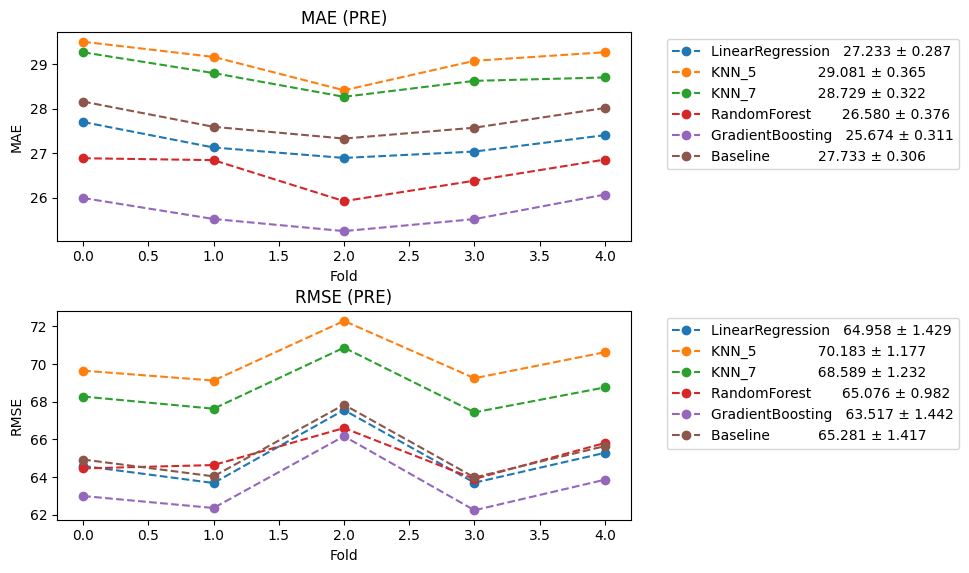



==================== PUSH CV PLOTS ====================


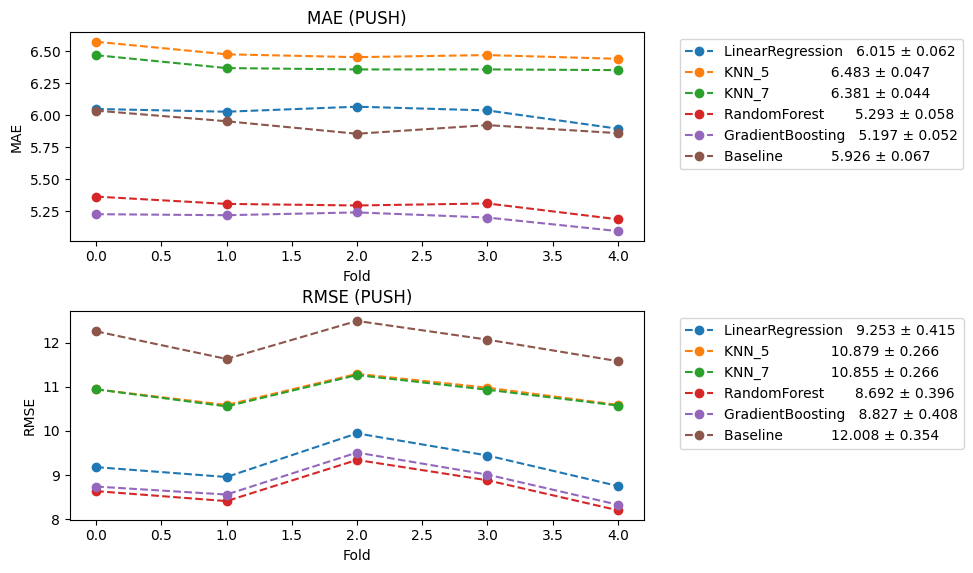



==================== POST CV PLOTS ====================


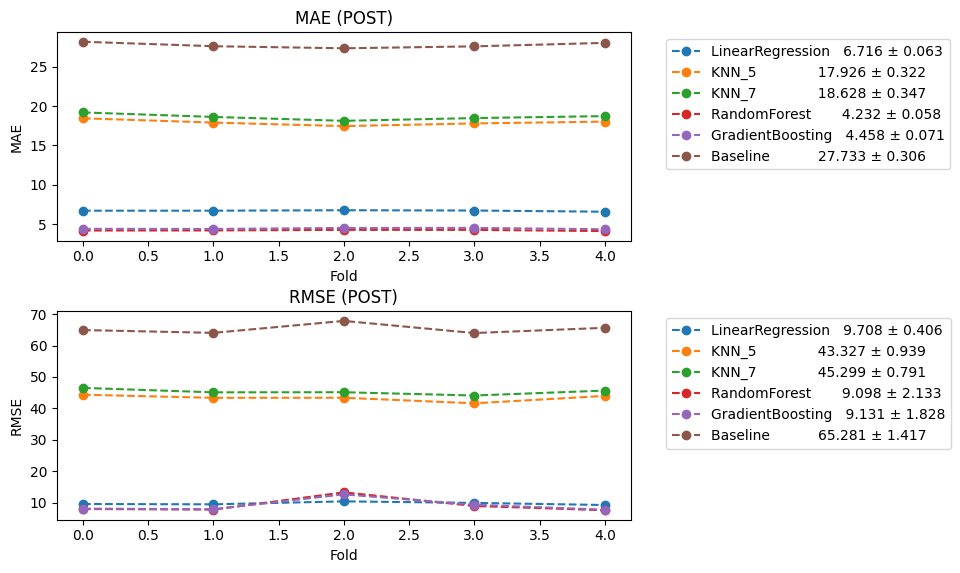

In [35]:

# ============================================
# MAE + RMSE Cross‑Validation Plots (PRE + PUSH + POST)
# ============================================
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold
import matplotlib.pyplot as plt
import numpy as np

cv_store = {"PRE":{}, "PUSH":{}, "POST":{}}                 # <-- added storage dict

def rmse(y_true, y_pred):
    return np.sqrt(metrics.mean_squared_error(y_true, y_pred))

msrs = {
    'MAE':  metrics.make_scorer(metrics.mean_absolute_error),
    'RMSE': metrics.make_scorer(rmse)
}

stages = [
    ("PRE",  X_train_pre_scaled,  X_test_pre_scaled,  X_train_pre_ord,  X_test_pre_ord,  y_train_pre),
    ("PUSH", X_train_push_scaled, X_test_push_scaled, X_train_push_ord, X_test_push_ord, y_train_push),
    ("POST", X_train_post_scaled, X_test_post_scaled, X_train_post_ord, X_test_post_ord, y_train_post)
]

for stage, Xtr_s, Xte_s, Xtr_o, Xte_o, ytr in stages:

    print(f"\n\n==================== {stage} CV PLOTS ====================")

    fig, axes = plt.subplots(2, 1, figsize=(7, 6))
    fig.tight_layout(pad=3)

    for model_name, (kind, model) in models.items():

        X = Xtr_s if kind == "scaled" else Xtr_o
        y = ytr

        # ---- CV call ----
        cv_results = cross_validate(
            model,
            X, y,
            scoring=msrs,
            cv=5,
            return_train_score=False
        )

        # ---- extract fold metrics ----
        mae_vals  = cv_results["test_MAE"]
        rmse_vals = cv_results["test_RMSE"]

        # ---- added: compute preds + actual for storage ----
        preds_all = []
        actual_all = []
        kf = KFold(n_splits=5, shuffle=True, random_state=42)

        for tr, va in kf.split(X):
            model.fit(X.iloc[tr], y.iloc[tr])     # FIX: iloc for row indexing
            p = model.predict(X.iloc[va])
            preds_all.extend(p)
            actual_all.extend(y.iloc[va])

        preds_all = np.array(preds_all)
        actual_all = np.array(actual_all)
        residuals = actual_all - preds_all
        abs_errors = np.abs(residuals)

        # ---- added: store everything ----
        cv_store[stage][model_name] = {
            "preds": preds_all,
            "actual": actual_all,
            "residuals": residuals,
            "abs_errors": abs_errors,
            "MAE_folds": mae_vals,
            "RMSE_folds": rmse_vals
        }

        # ---- plotting ----
        for ax, msr in zip(axes, msrs):
            vals = cv_results["test_" + msr]
            label = f"{model_name:18s} {vals.mean():.3f} ± {vals.std():.3f}"
            ax.plot(vals, 'o--', label=label)
            ax.set_title(f"{msr} ({stage})")
            ax.set_xlabel("Fold")
            ax.set_ylabel(msr)

    for ax in axes:
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.show()


## Errors
This function builds the paired regression‑error plots for a model’s predictions. It takes the actual and predicted values, plots both directions (actual→predicted and predicted→actual), overlays the y=x perfection line, and optionally highlights either all errors or just the top 50 worst ones. The red error bars make it easy to see where the model is drifting away from the ideal line. The title tags the plot with the model name so it’s clear which set of predictions you’re looking at.

In [36]:
def regression_errors(axs, preds, actual, model_name="", errors='all'):     # axs = (ax1, ax2)
    df = pd.DataFrame({'actual': actual, 'predicted': preds})               # DataFrame for plotting

    for ax, (x, y) in zip(axs, it.permutations(['actual', 'predicted'])):
        ax.plot(df[x], df[y], '.', label='data')                            # scatter
        ax.plot(df['actual'], df['actual'], '-', label='perfection')        # y=x line
        ax.legend()
        ax.set_xlabel(f"{x.capitalize()} Value")
        ax.set_ylabel(f"{y.capitalize()} Value")
        ax.set_aspect('equal')

    axs[1].yaxis.tick_right()                                               # right-side ticks
    axs[1].yaxis.set_label_position("right")

    if errors == 'top50':                                                   # worst 50 errors
        abs_err = np.abs(df['actual'] - df['predicted'])
        errors = abs_err.nlargest(50).index
    elif errors == 'all':                                                   # all errors
        errors = df.index

    if len(errors) > 0:                                                     # draw error bars
        acts = df.actual.loc[errors]
        prds = df.predicted.loc[errors]
        axs[0].vlines(acts, prds, acts, 'r')                                # vertical bars
        axs[1].hlines(acts, prds, acts, 'r')                                # horizontal bars

    axs[0].set_title(f"{model_name} — Regression Error Plots")              # title


This cell loops through every model and generates the paired regression‑error plots for the PRE, PUSH, and POST stages using the cross‑validated predictions stored in cv_store. For each model, it pulls the out‑of‑fold preds and actuals, builds the two‑panel error plot, and highlights the 50 worst errors so it’s easy to see where the model is drifting the most. It runs this for all three datasets, giving a clean visual read on model behavior across the entire pipeline.

Output:

There is a lot to go over here, but the main thing that stands out is how consistently strong GradientBoosting is across all three datasets. The error plots make that obvious right away.

In PRE, the predictions sit much closer to the perfection line than the linear model, and the errors stay tight even as values increase. In PUSH, the alignment gets even cleaner, with almost all points hugging the diagonal and only small deviations, which shows that this dataset is especially friendly to boosting. In POST, the model still performs well, but you start to see a few more spread‑out points at the low and high ends, which tells you POST has more irregular structure. Even with that, GradientBoosting keeps the errors controlled and stays close to the ideal line.

Overall, the biggest difference across the datasets is how tightly the predictions cluster around the diagonal. PRE shows moderate spread, PUSH is the cleanest, and POST has a bit more noise, but GradientBoosting handles all three better than the simpler models.

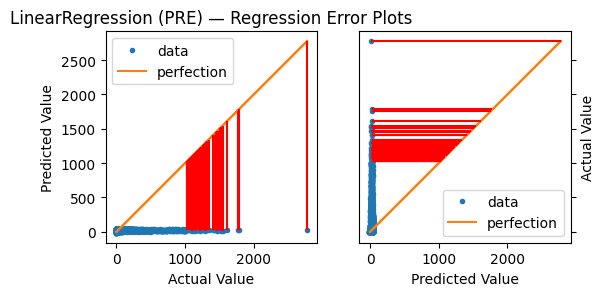

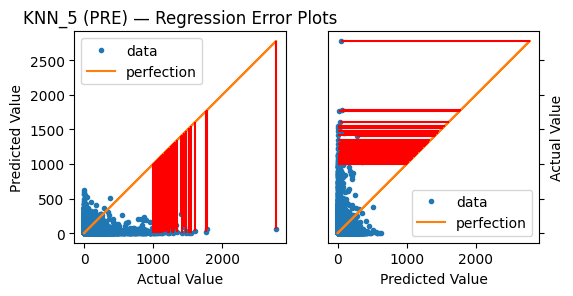

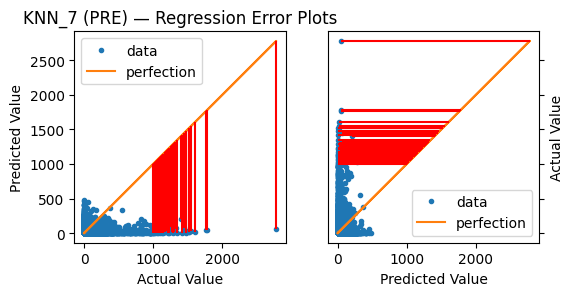

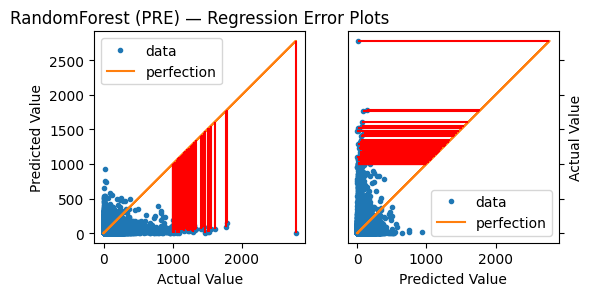

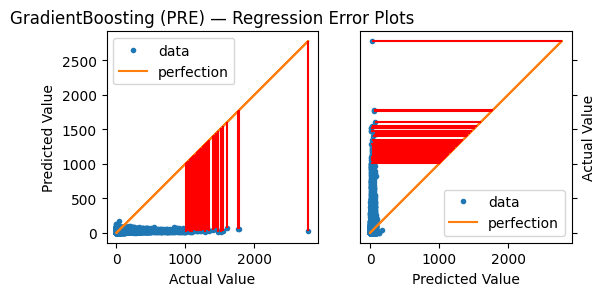

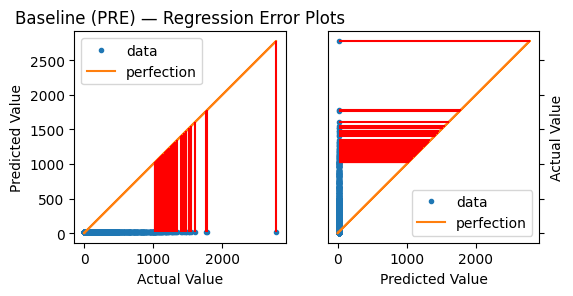

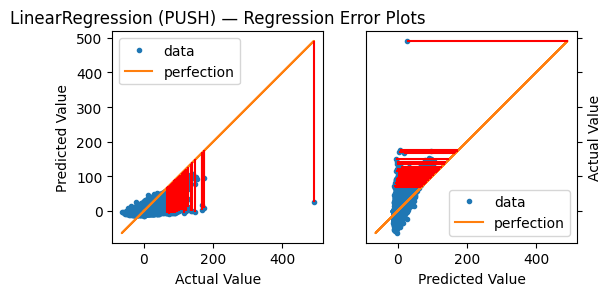

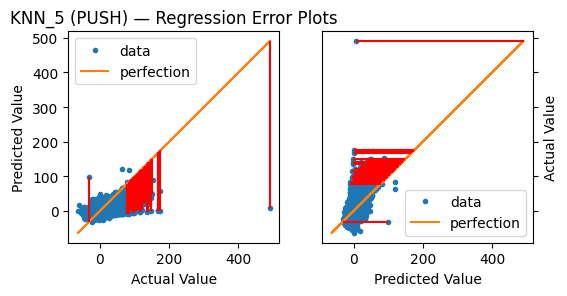

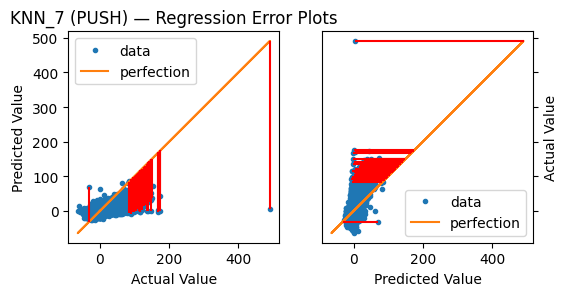

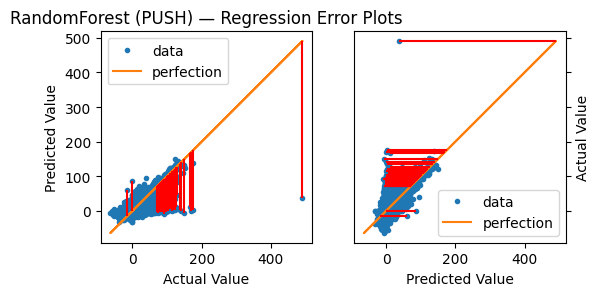

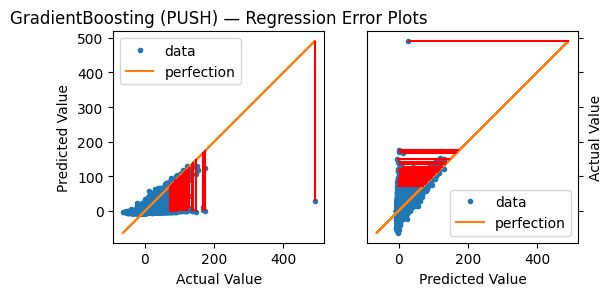

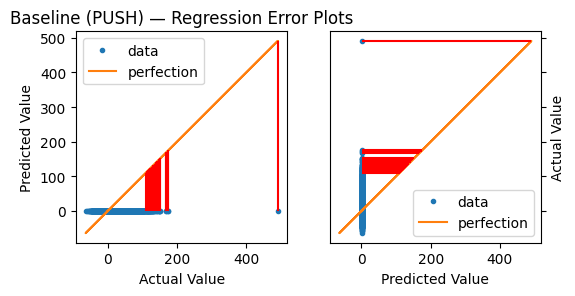

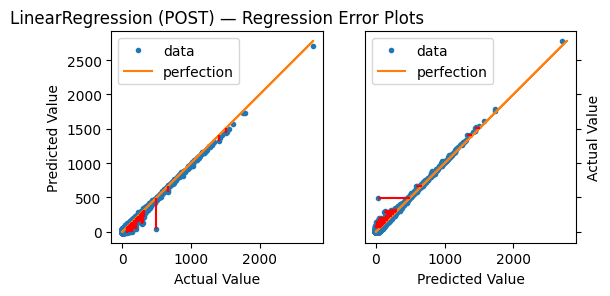

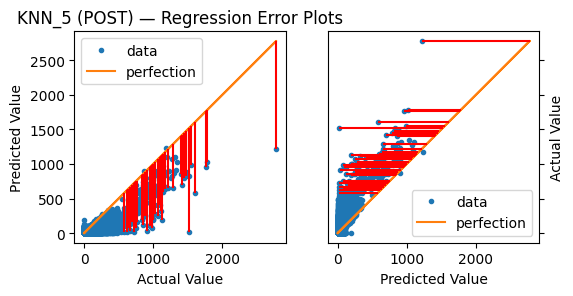

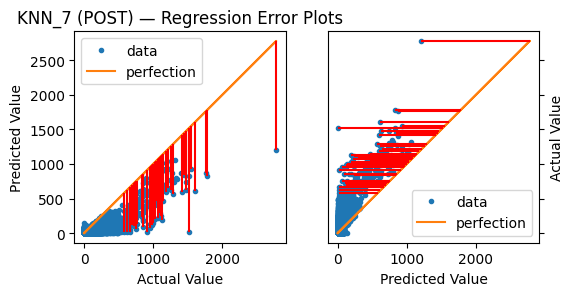

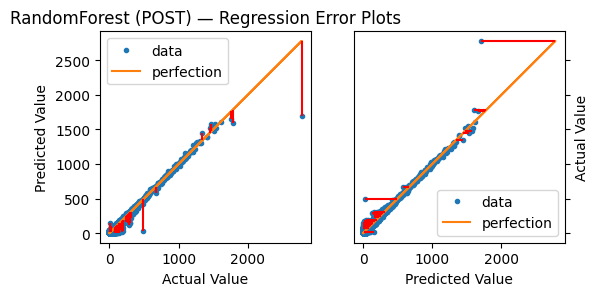

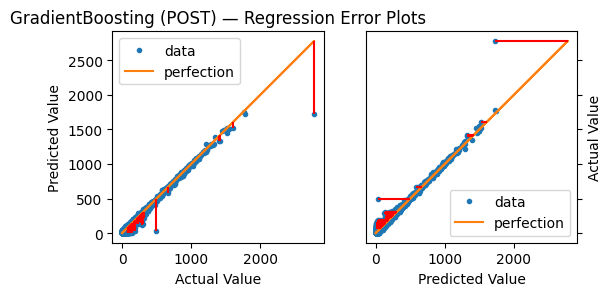

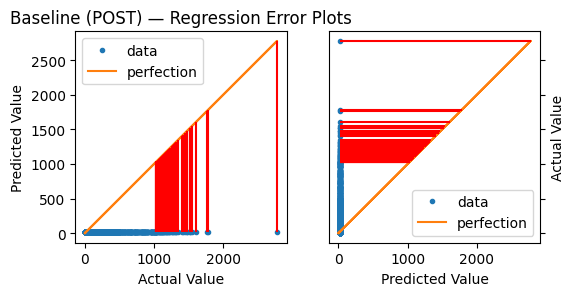

In [37]:
# ---- PRE DATASET ----
for model_name in cv_store["PRE"]:                                        # loop through all models for PRE
    preds  = cv_store["PRE"][model_name]["preds"]                         # CV predictions
    actual = cv_store["PRE"][model_name]["actual"]                        # actual values

    fig, axs = plt.subplots(1,2, figsize=(6,3), sharex=True, sharey=True) # create 2‑panel error plot
    regression_errors(axs, preds, actual, f"{model_name} (PRE)",          # call error plotter
                      errors='top50')                                     # highlight worst 50 errors
    plt.show()                                                            # display plot

# ---- PUSH DATASET ----
for model_name in cv_store["PUSH"]:                                       # loop through all models for PUSH
    preds  = cv_store["PUSH"][model_name]["preds"]                        # CV predictions
    actual = cv_store["PUSH"][model_name]["actual"]                       # actual values

    fig, axs = plt.subplots(1,2, figsize=(6,3), sharex=True, sharey=True) # create 2‑panel error plot
    regression_errors(axs, preds, actual, f"{model_name} (PUSH)",         # call error plotter
                      errors='top50')                                     # highlight worst 50 errors
    plt.show()                                                            # display plot

# ---- POST DATASET ----
for model_name in cv_store["POST"]:                                       # loop through all models for POST
    preds  = cv_store["POST"][model_name]["preds"]                        # CV predictions
    actual = cv_store["POST"][model_name]["actual"]                       # actual values

    fig, axs = plt.subplots(1,2, figsize=(6,3), sharex=True, sharey=True) # create 2‑panel error plot
    regression_errors(axs, preds, actual, f"{model_name} (POST)",         # call error plotter
                      errors='top50')                                     # highlight worst 50 errors
    plt.show()                                                            # display plot


This function builds a clean residual plot for a model’s predictions. It computes the residuals (actual − predicted), scatters them against the predicted values, and overlays the zero‑residual line so you can see bias and spread at a glance. If you ask for top50, it highlights the 50 largest residuals with vertical error bars. The optional right‑axis formatting is there for side‑by‑side layouts. The title tags the plot with the model name so it’s easy to keep track of which output you’re looking at.

In [38]:
def regression_residuals(ax, preds, actual, model_name="", show_errors=None, right=False):
    df = pd.DataFrame({'actual': actual, 'predicted': preds})               # DataFrame
    df['error'] = df.actual - df.predicted                                  # residuals

    ax.plot(df.predicted, df.error, '.')                                    # scatter residuals
    ax.plot(df.predicted, np.zeros_like(preds), '-')                        # zero line

    if right:                                                               # optional right axis
        ax.yaxis.tick_right()
        ax.yaxis.set_label_position("right")
        ax.set_xlabel('Predicted Value')
        ax.set_ylabel('Residual')

    if show_errors == 'top50':                                              # worst 50 residuals
        abs_err = np.abs(df['error'])
        show_errors = abs_err.nlargest(50).index
    elif show_errors == 'all':                                              # all residuals
        show_errors = df.index

    if show_errors is not None and len(show_errors) > 0:                    # draw error bars
        prds = df.predicted.loc[show_errors]
        errs = df.error.loc[show_errors]
        ax.vlines(prds, 0, errs, 'r')

    ax.set_title(f"{model_name} residuals")                                 # title


This cell loops through every model in the PRE, PUSH, and POST stages and generates the single‑panel residual plots using the cross‑validated predictions stored in cv_store. For each model, it pulls the out‑of‑fold preds and actuals, builds the residual plot, and highlights the 50 largest residuals so you can see where the model is drifting the most. Running this across all three stages gives a clean read on model bias, spread, and where each model struggles the hardest.

Output:

Like the last cell, there is a lot to go over here. What jumps out immediately though is how badly the KNN models perform in the POST dataset. The residual plots make it impossible to miss.

KNN_5 shows huge vertical spikes, with residuals shooting hundreds to well over a thousand units off. The pattern is completely scattered, and there is no structure or stability in the errors. It looks more like noise than a model making informed predictions. KNN_7 is no better — the residuals are still massive, still inconsistent, and still spread across the entire range. Increasing k does not fix anything because the underlying issue is that POST is not a neighborhood‑friendly dataset. The relationships are too nonlinear and too irregular for KNN to capture with simple distance averaging.

What these plots really highlight is that KNN is fundamentally the wrong tool for this dataset. The errors are not just large — they are unpredictable and unbounded, even when using a strong predictor, which lines up with the huge MAE and RMSE values we saw earlier. Compared to GradientBoosting and RandomForest, which stay tight around the perfection line, the KNN models completely fall apart here.

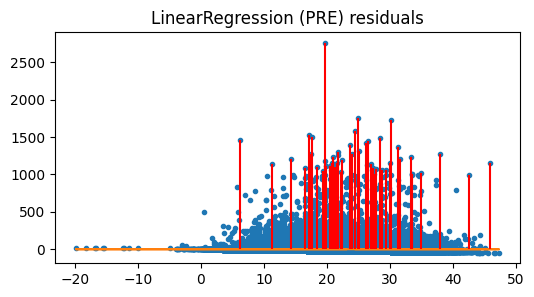

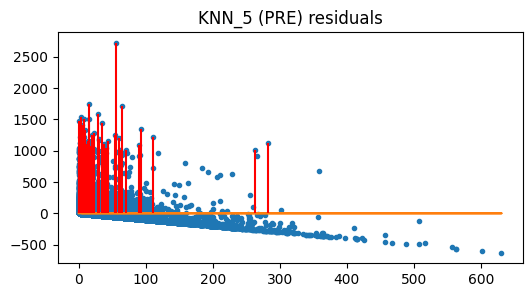

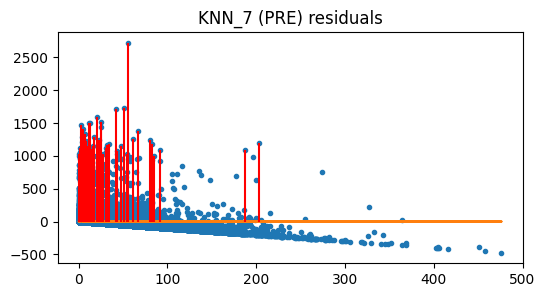

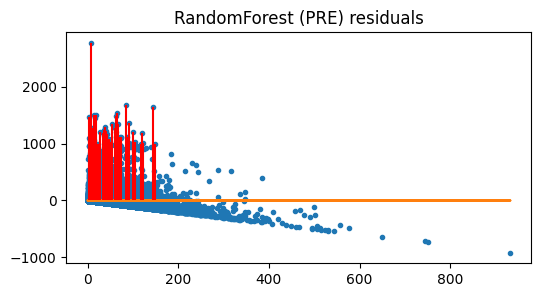

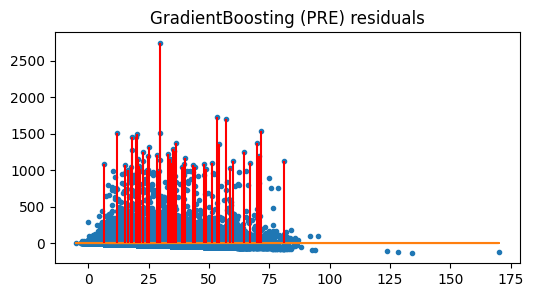

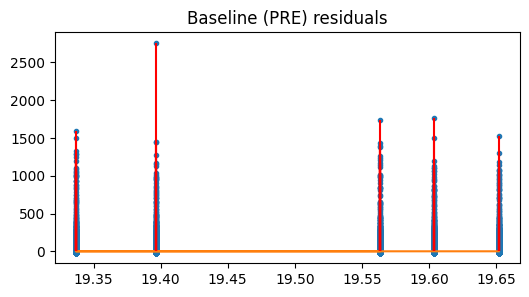

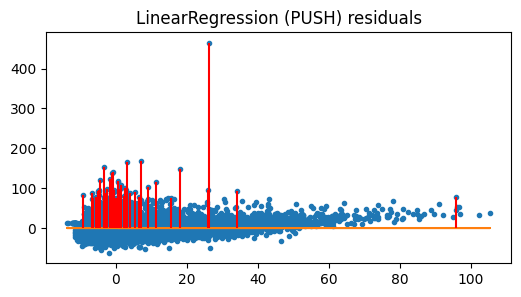

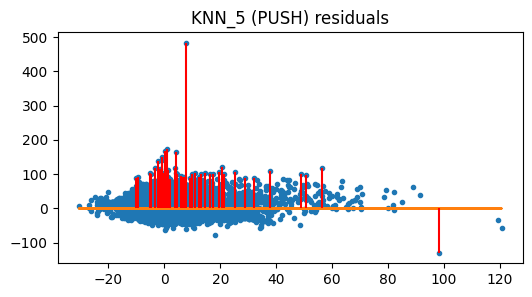

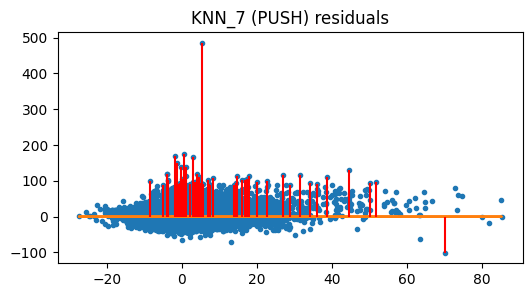

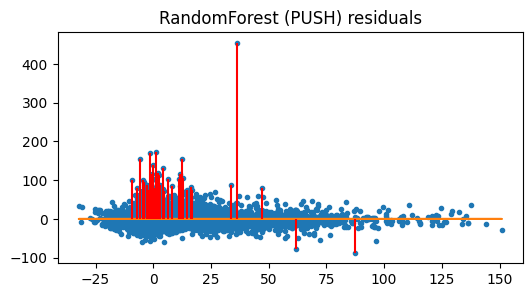

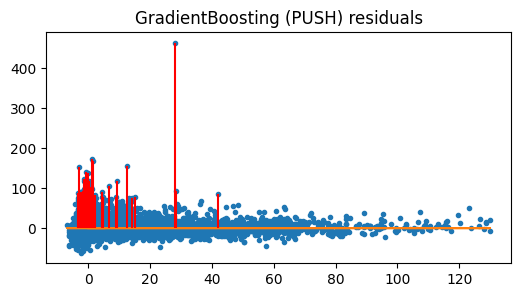

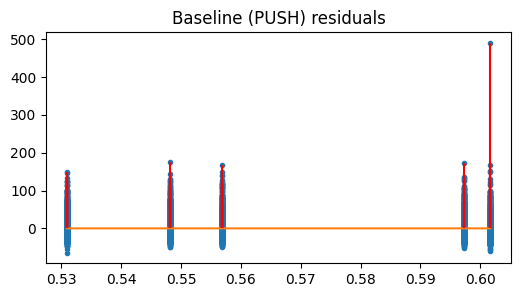

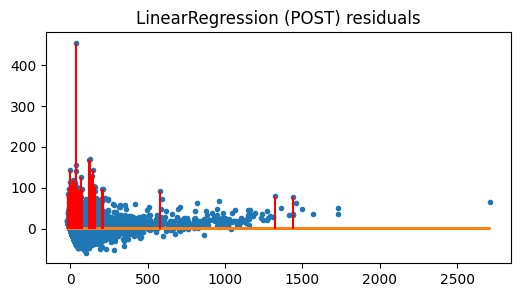

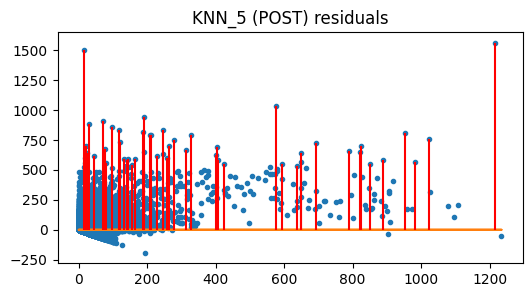

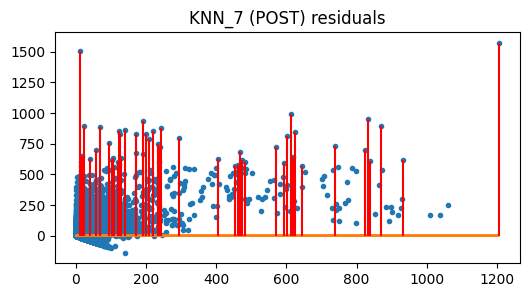

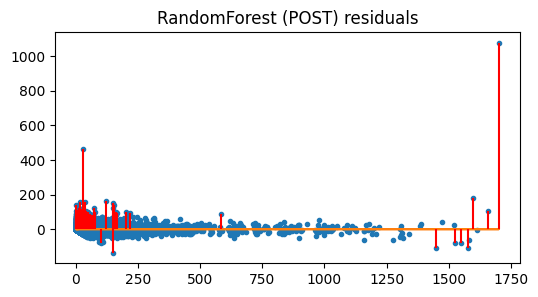

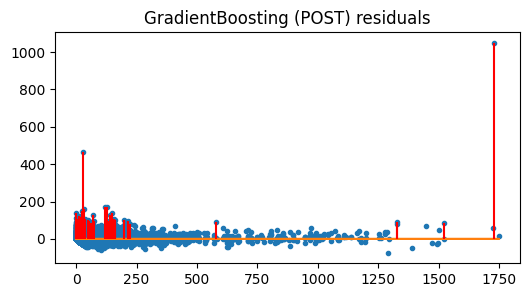

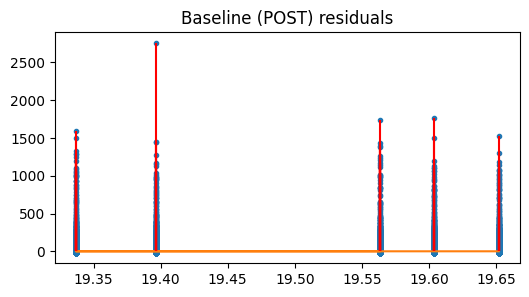

In [39]:
# ---- PRE DATASET ----
for model_name in cv_store["PRE"]:                                      # loop through all models for PRE
    preds  = cv_store["PRE"][model_name]["preds"]                       # CV predictions
    actual = cv_store["PRE"][model_name]["actual"]                      # actual values

    fig, ax = plt.subplots(1,1, figsize=(6,3))                          # create single residual plot
    regression_residuals(ax, preds, actual, f"{model_name} (PRE)",      # call residual plotter
                         show_errors='top50')                           # highlight worst 50 errors
    plt.show()                                                          # display plot

# ---- PUSH DATASET ----
for model_name in cv_store["PUSH"]:                                     # loop through all models for PUSH
    preds  = cv_store["PUSH"][model_name]["preds"]                      # CV predictions
    actual = cv_store["PUSH"][model_name]["actual"]                     # actual values

    fig, ax = plt.subplots(1,1, figsize=(6,3))                          # create single residual plot
    regression_residuals(ax, preds, actual, f"{model_name} (PUSH)",     # call residual plotter
                         show_errors='top50')                           # highlight worst 50 errors
    plt.show()                                                          # display plot

# ---- POST DATASET ----
for model_name in cv_store["POST"]:                                     # loop through all models for POST
    preds  = cv_store["POST"][model_name]["preds"]                      # CV predictions
    actual = cv_store["POST"][model_name]["actual"]                     # actual values

    fig, ax = plt.subplots(1,1, figsize=(6,3))                          # create single residual plot
    regression_residuals(ax, preds, actual, f"{model_name} (POST)",     # call residual plotter
                         show_errors='top50')                           # highlight worst 50 errors
    plt.show()                                                          # display plot


## Gradient Boosting Loss Curve
This cell trains the Gradient Boosting model on the POST‑takeoff dataset and plots its training loss curve. Since tree‑based models use the ordinal‑encoded features, it pulls the POST ordinal set, fits the model, and grabs the train_score_ values that Gradient Boosting exposes at each boosting stage. Plotting that sequence shows how quickly the model reduces deviance as it adds trees, which gives you a read on convergence and whether the model is still learning or has flattened out.

Output:

GradientBoosting shows a really clean learning pattern in the POST dataset. The loss drops fast at the start, which tells me the model picks up the main structure right away, and then it settles into a smooth curve as it gets closer to the minimum. That shape makes it clear the model is learning real patterns instead of chasing noise or drifting into overfitting.

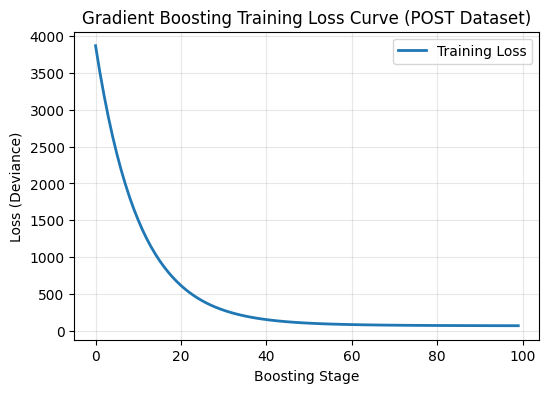

In [40]:
# Gradient Boosting Training Loss Curve (POST)

from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

# get the GB model from your unified dict
kind, gb = models["GradientBoosting"]            # ("tree", model)

# choose correct POST dataset (ordinal for tree models)
Xtr = X_train_post_ord
ytr = y_train_post

# fit model
gb.fit(Xtr, ytr)

# training loss at each boosting stage
loss_curve = gb.train_score_

plt.figure(figsize=(6,4))
plt.plot(loss_curve, label="Training Loss", linewidth=2)
plt.xlabel("Boosting Stage")
plt.ylabel("Loss (Deviance)")
plt.title("Gradient Boosting Training Loss Curve (POST Dataset)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Comparing All Models to Perfect Fit Line
This cell builds the full actual‑vs‑predicted scatter grid for every model across the PRE, PUSH, and POST stages. It loops through the stored true labels and predictions, plots each model’s output, and overlays the perfect line so you can see how tightly each model tracks the ideal relationship. The 3×N layout makes it easy to compare models side‑by‑side and see how performance shifts from pre‑flight to push to post‑takeoff.

Output:

This grid makes the differences between the models really clear. In the PRE row, the simpler models do alright, but we can already see KNN drifting away from the diagonal while the ensemble models stay tighter. In PUSH, that separation gets even more obvious. KNN is still scattered, LinearRegression is fine but limited, and the tree‑based models lock onto the structure with much cleaner alignment.

POST is where everything really splits. LinearRegression holds up, but both KNN models fall apart with wide, inconsistent scatter that barely follows the diagonal. RandomForest and GradientBoosting stay tight and controlled, which matches everything we saw in the metrics and residuals. Overall, the grid reinforces the same story: KNN struggles across all datasets, LinearRegression is steady but capped, and the ensemble models consistently deliver the closest and most stable predictions.

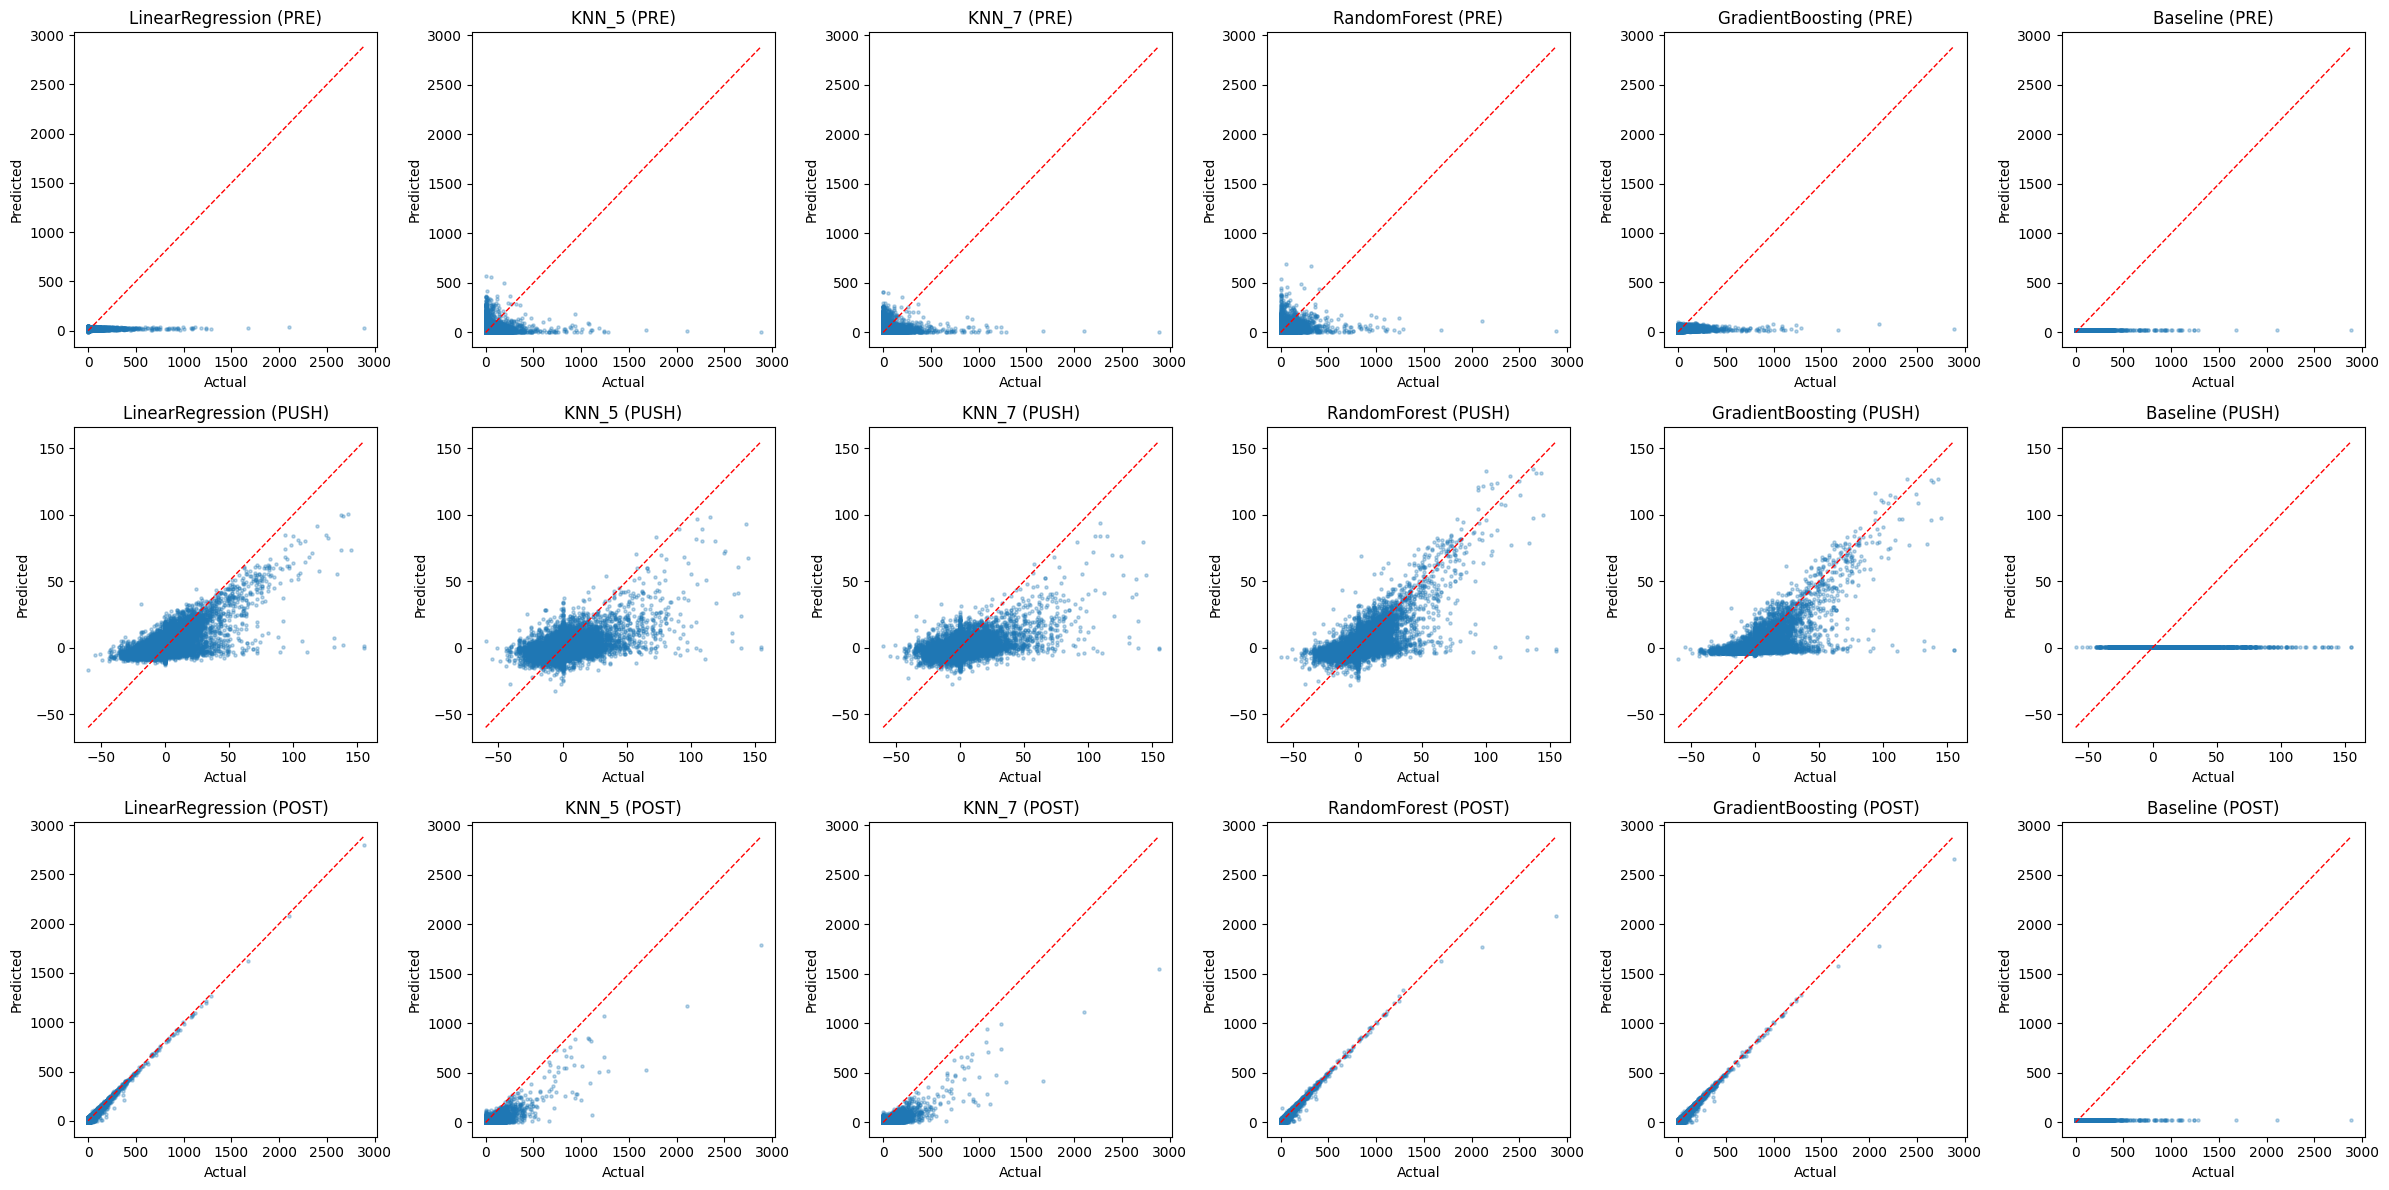

In [41]:
import matplotlib.pyplot as plt

model_names = list(baseline_preds["PRE"].keys())          # use baseline model list
n_models = len(model_names)

if n_models == 0:
    print("No models found in baseline_preds['PRE']")
else:
    fig, axes = plt.subplots(3, n_models, figsize=(4*n_models, 12))

    if n_models == 1:
        axes = axes.reshape(3,1)

    for row_idx, stage in enumerate(["PRE", "PUSH", "POST"]):

        y_true = reg_stored_ytrue[stage]                  # true labels

        for col_idx, model_name in enumerate(model_names):

            y_pred = reg_stored_preds[stage][model_name]  # predictions

            ax = axes[row_idx, col_idx]
            ax.scatter(y_true, y_pred, s=5, alpha=0.3)
            ax.plot([y_true.min(), y_true.max()],
                    [y_true.min(), y_true.max()],
                    'r--', linewidth=1)

            ax.set_title(f"{model_name} ({stage})")
            ax.set_xlabel("Actual")
            ax.set_ylabel("Predicted")

    plt.tight_layout()
    plt.show()


## Residuals Histogram
This cell plots the residual distributions for every model across PRE, PUSH, and POST. For each model, it computes the residuals (actual − predicted) and drops them into a histogram so you can see the spread, skew, and tail behavior at each stage. The dashed vertical line at zero anchors the plot so you can quickly see whether a model is centered or drifting. Laying everything out in a 3×N grid makes it easy to compare models side‑by‑side and see how the error distribution shifts as you move from pre‑flight to pushback to post‑takeoff.

Output:

These residual histograms make the differences between the models really clear across all three datasets. In PRE, most models stay centered around zero with reasonable spread, but the KNN models already start showing wider tails and less control. In PUSH, that pattern gets stronger. LinearRegression and the ensemble models keep tight, balanced distributions, while both KNN versions spread out and show heavier error on both sides.

POST is where the gap becomes obvious. The ensemble models keep compact, well‑shaped residuals, and LinearRegression stays fairly controlled. The KNN models, though, blow up with wide, uneven distributions that stretch far from zero. It matches everything we saw earlier. KNN just cannot handle the structure in POST, and the residuals make that failure really obvious.

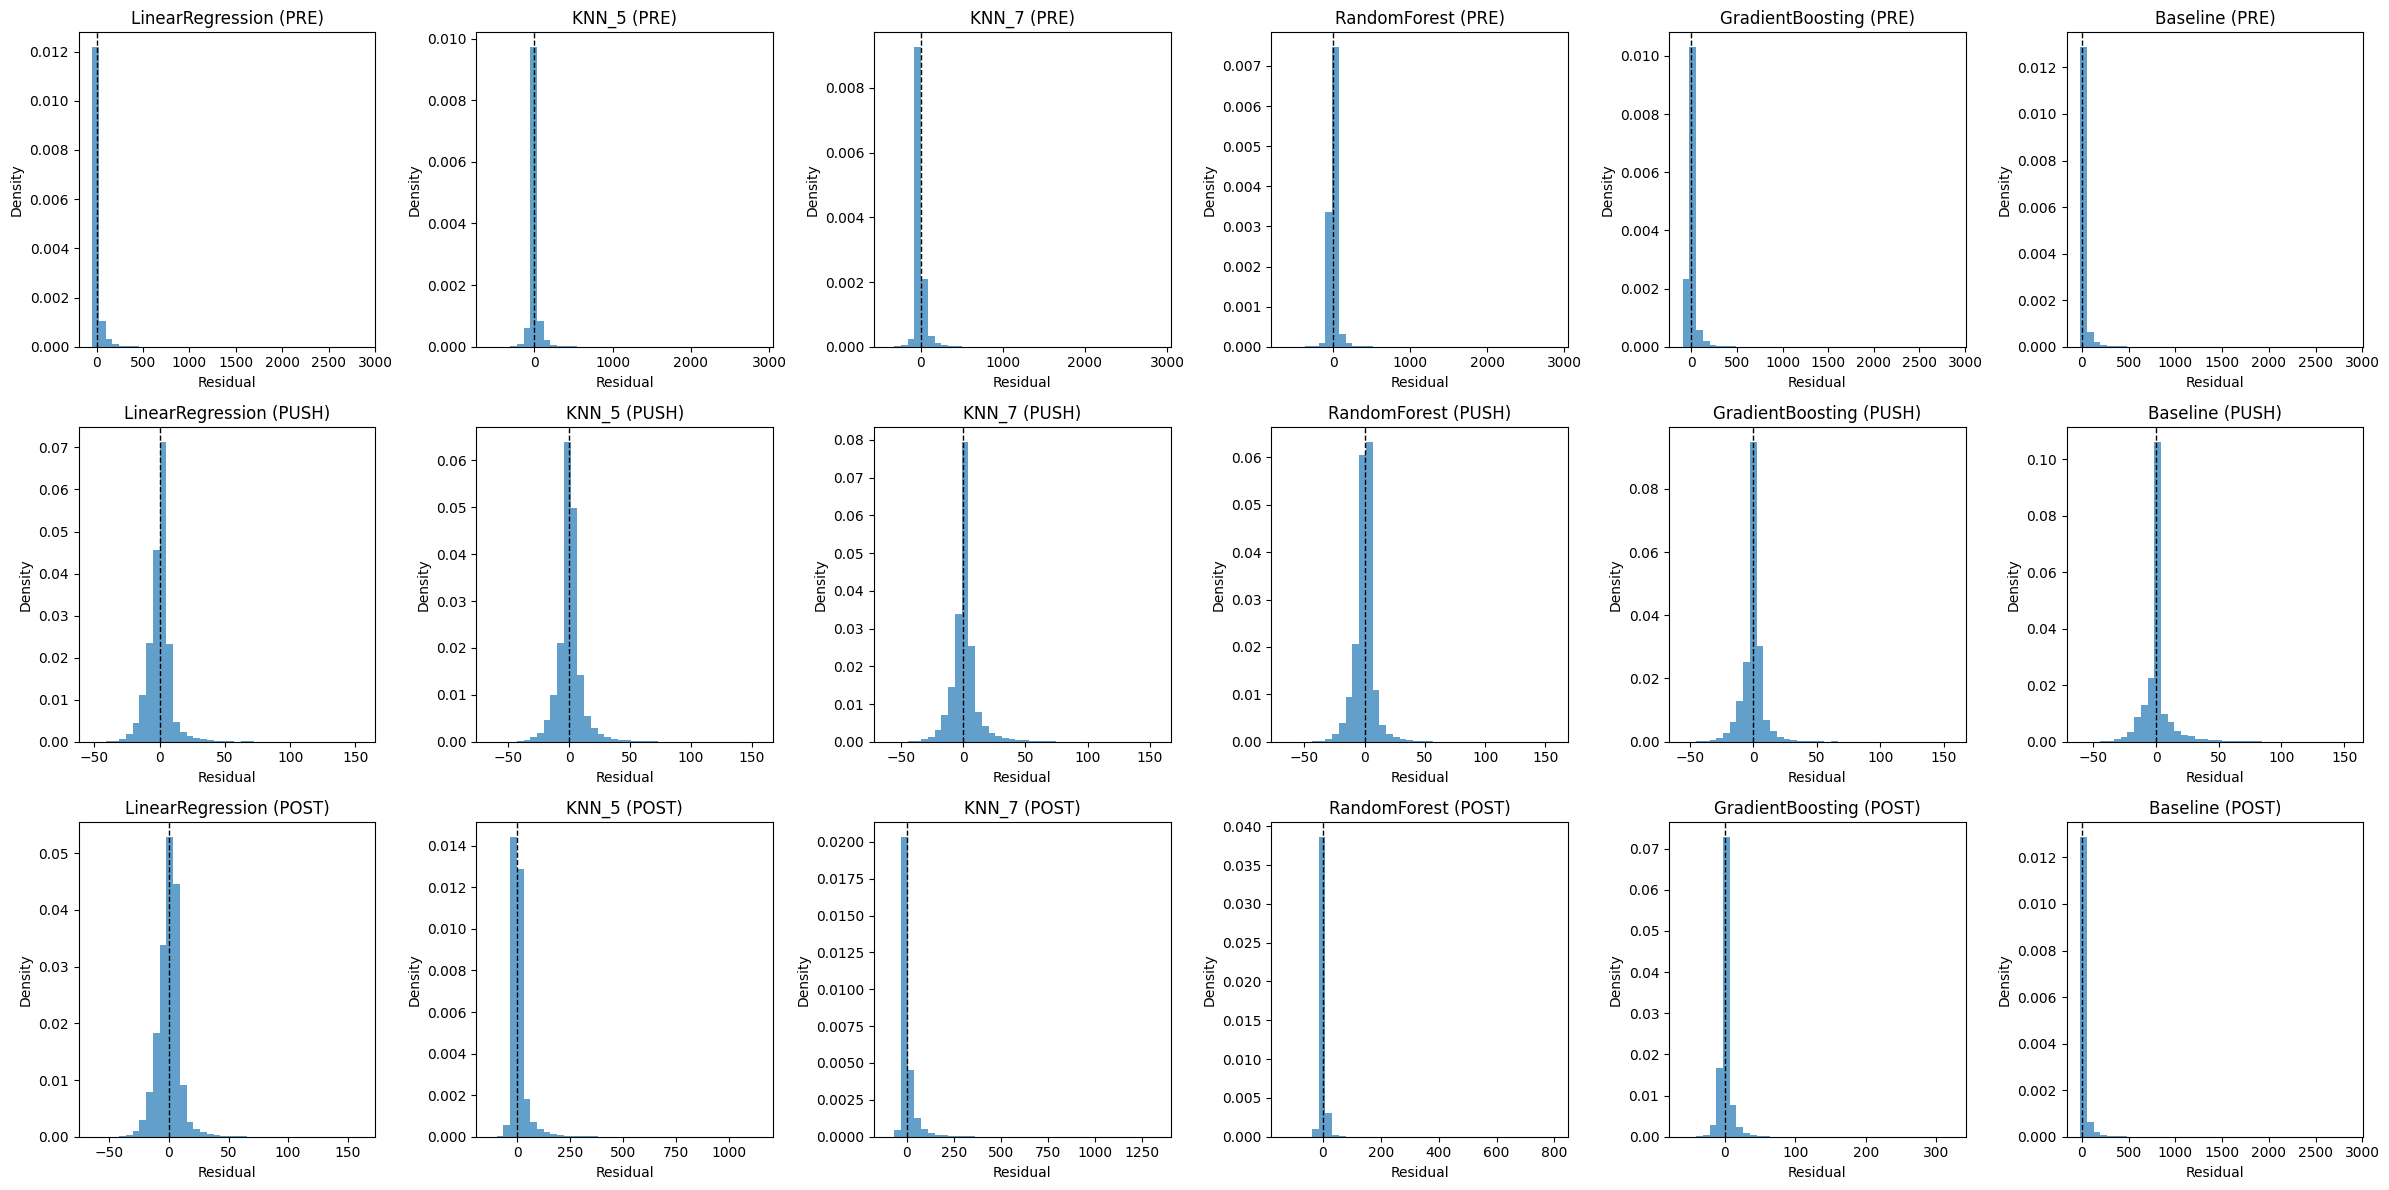

In [42]:
import matplotlib.pyplot as plt
import numpy as np

model_names = list(baseline_preds["PRE"].keys())          # model list
n_models = len(model_names)

fig, axes = plt.subplots(3, n_models, figsize=(4*n_models, 12))  # grid

if n_models == 1:
    axes = axes.reshape(3,1)                               # ensure 2D

for row_idx, stage in enumerate(["PRE", "PUSH", "POST"]):

    y_true = reg_stored_ytrue[stage]                       # true labels

    for col_idx, model_name in enumerate(model_names):

        y_pred = reg_stored_preds[stage][model_name]       # predictions
        residuals = y_true - y_pred                        # compute residuals

        ax = axes[row_idx, col_idx]                        # axis handle
        ax.hist(residuals, bins=40, density=True, alpha=0.7)  # histogram only

        ax.axvline(0, color='k', linestyle='--', linewidth=1)  # zero line

        ax.set_title(f"{model_name} ({stage})")            # title
        ax.set_xlabel("Residual")                          # x-label
        ax.set_ylabel("Density")                           # y-label

plt.tight_layout()
plt.show()


## Residuals Box Plots
This cell builds the residual boxplot grid for every model across PRE, PUSH, and POST. For each model, it computes the residuals (actual − predicted) and drops them into a boxplot so you can see bias, spread, and outliers at a glance. The zero line anchors the plot so you can quickly see whether a model is centered or consistently drifting. Laying everything out as one row per model and one column per stage makes it easy to compare how each model behaves as you move from pre‑flight to pushback to post‑takeoff.

Output:

These boxplots make the differences between the models pretty easy to read. PRE and PUSH look manageable for most of the models, but the KNN rows already start to stretch out with wider boxes and a bunch of outliers. We can tell right away they’re not handling the structure as well as the others.

Once you get to POST, the gap becomes obvious. The ensemble models stay tight with controlled residuals, and LinearRegression holds a steady middle ground. The KNN models, though, just explode. The spread jumps way out, and the number of extreme points is huge. The datasets are not neighborhood‑friendly, and KNN falls apart the moment the patterns get more complex.

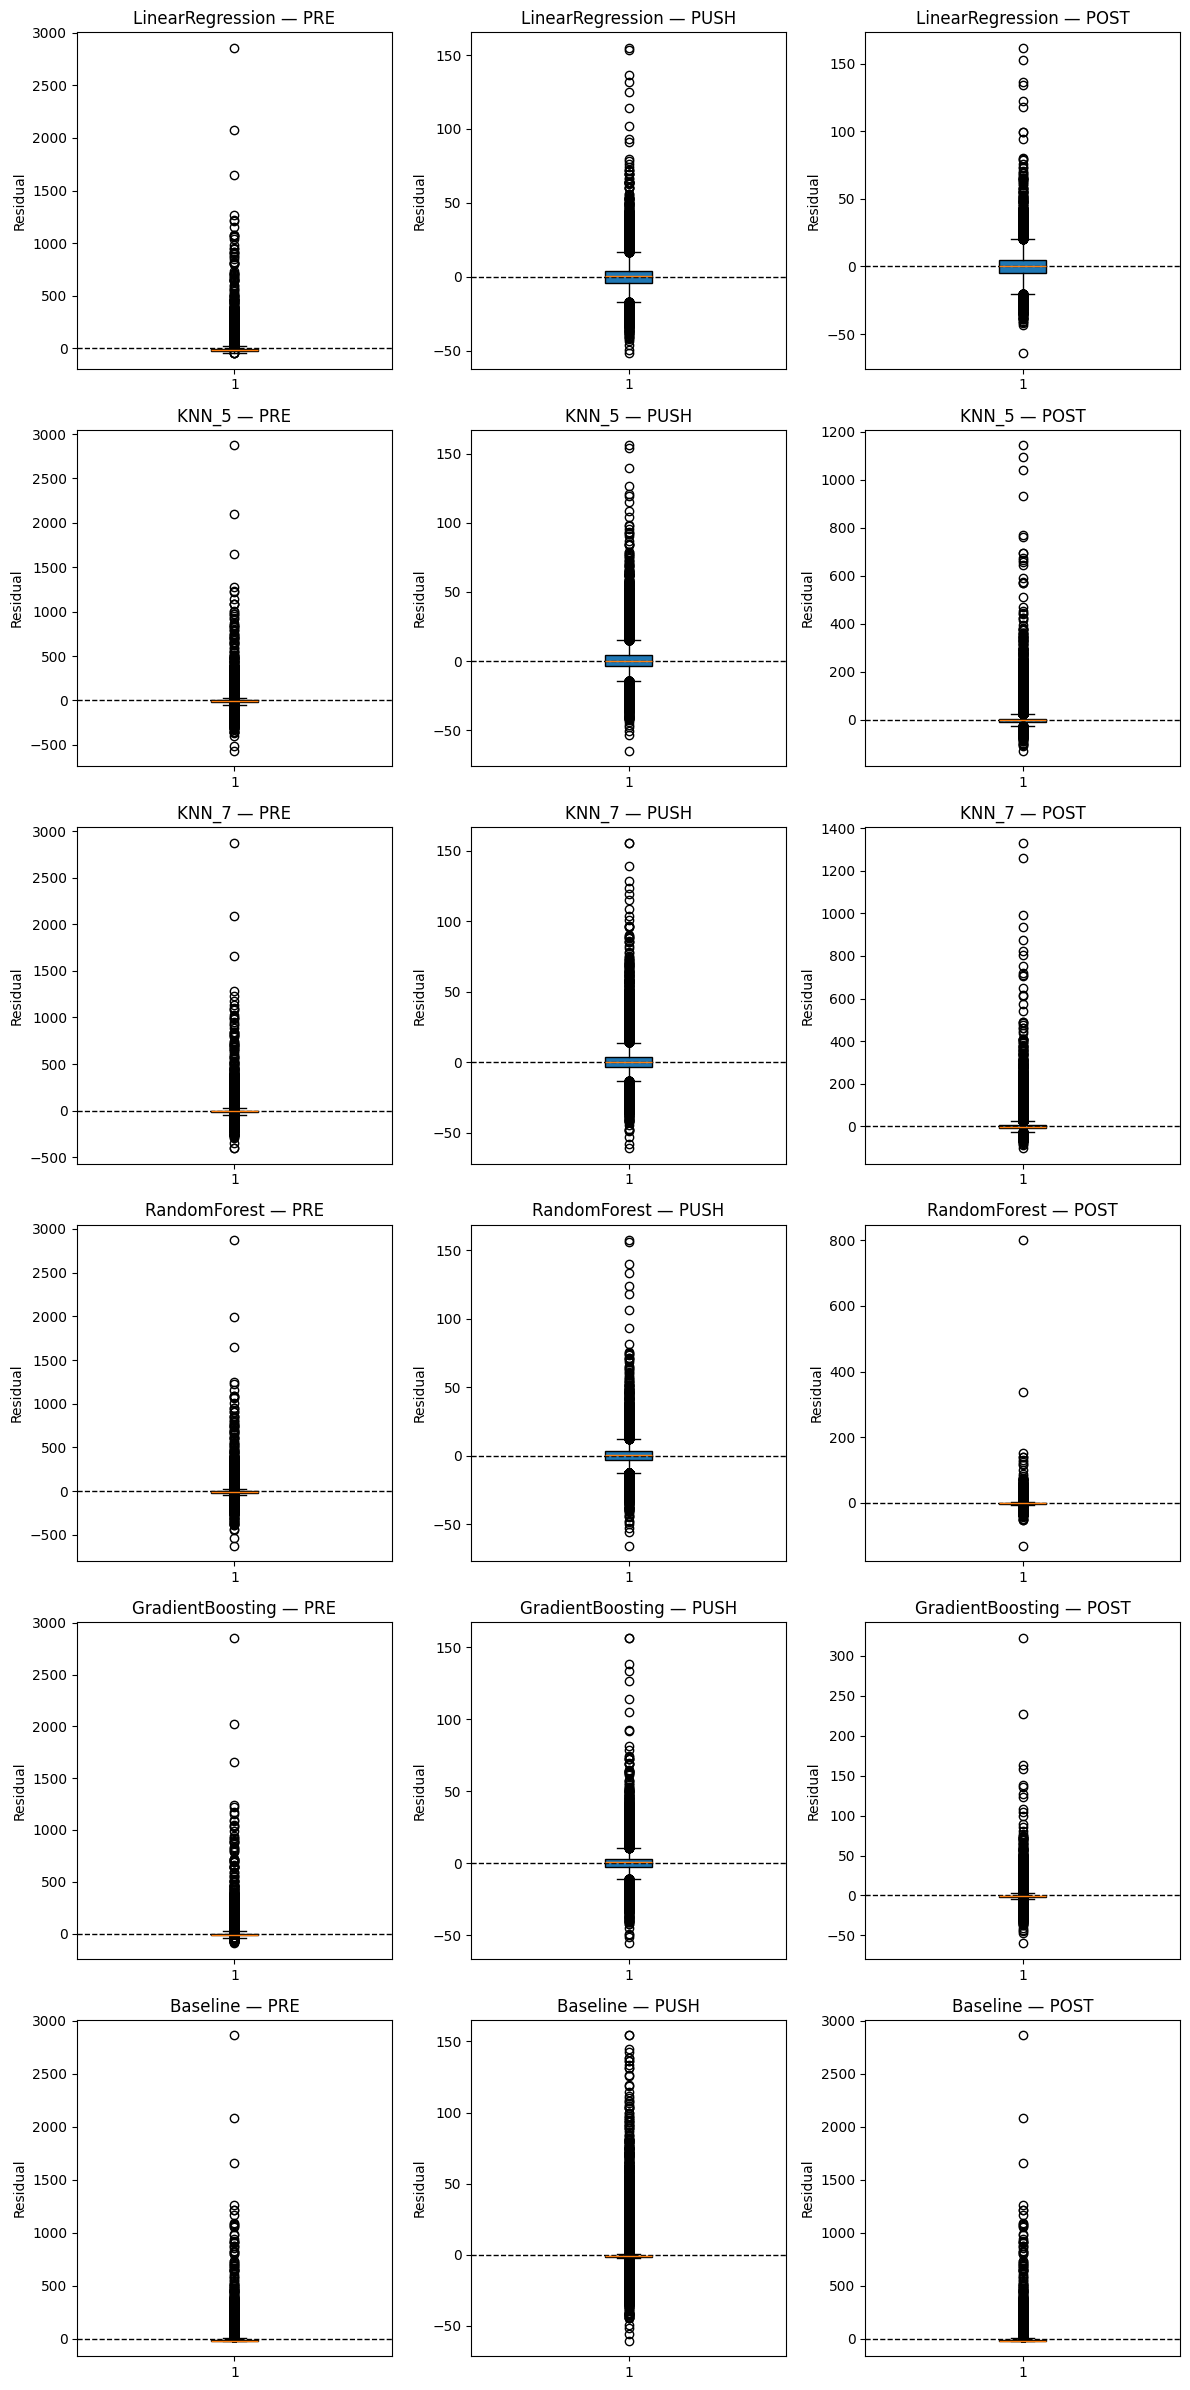

In [43]:
import matplotlib.pyplot as plt
import numpy as np

model_names = list(baseline_preds["PRE"].keys())          # model list
n_models = len(model_names)

fig, axes = plt.subplots(n_models, 3, figsize=(12, 4*n_models))  # grid

if n_models == 1:
    axes = axes.reshape(1,3)                               # ensure 2D

for row_idx, model_name in enumerate(model_names):

    for col_idx, stage in enumerate(["PRE", "PUSH", "POST"]):

        y_true = reg_stored_ytrue[stage]                   # true labels
        y_pred = reg_stored_preds[stage][model_name]       # predictions
        residuals = y_true - y_pred                        # compute residuals

        ax = axes[row_idx, col_idx]                        # axis handle
        ax.boxplot(residuals, vert=True, patch_artist=True)

        ax.axhline(0, color='k', linestyle='--', linewidth=1)  # zero line

        ax.set_title(f"{model_name} — {stage}")            # title
        ax.set_ylabel("Residual")                          # y-label

plt.tight_layout()
plt.show()


## All Models Bar Chart Comparison
This cell builds the RMSE comparison chart across PRE, PUSH, and POST for every model. It pulls the test‑set RMSE from the stored baseline metrics, lines them up by model, and plots them as grouped bars so you can see how each model moves across the three feature stages. The layout makes it easy to spot which models improve with PUSH and which ones really tighten up once POST features are available.

Output:

This RMSE chart gives us a really clear read on how the models behave across the three datasets. The first thing that stands out is how the PRE bars are almost always the highest. PRE is clearly the toughest dataset, and every model takes a hit there. Once we move into PUSH and POST, the RMSE drops fast, and the differences between the models become much easier to see.

KNN sticks out again for the wrong reasons. Even when the overall error drops in PUSH and POST, both KNN versions stay noticeably higher than everything else. LinearRegression settles into a steady middle range, doing fine but never leading. The ensemble models are the ones that really separate themselves. RandomForest and GradientBoosting both show big improvements moving from PRE into PUSH and POST, and they consistently land at the bottom with the lowest RMSE values.

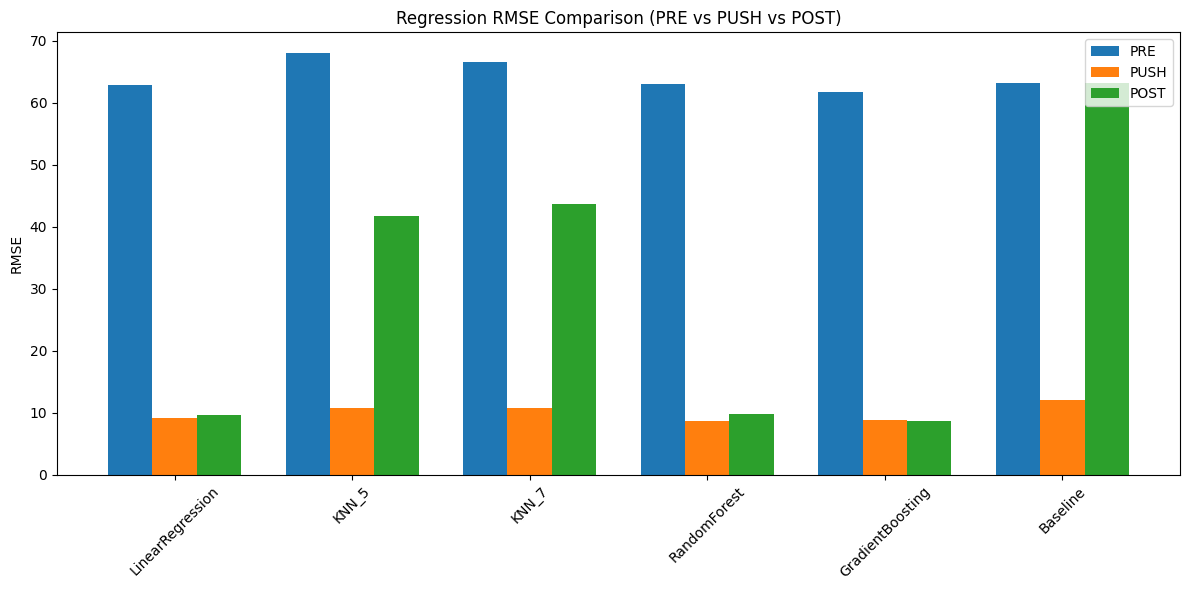

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# collect model names from PRE (all stages share same models)
model_names = list(baseline_metrics["PRE"].keys())

# extract RMSE for each stage
pre_rmse  = [baseline_metrics["PRE"][m]["test"]["RMSE"]  for m in model_names]
push_rmse = [baseline_metrics["PUSH"][m]["test"]["RMSE"] for m in model_names]
post_rmse = [baseline_metrics["POST"][m]["test"]["RMSE"] for m in model_names]

x = np.arange(len(model_names))
width = 0.25

plt.figure(figsize=(12,6))

plt.bar(x - width, pre_rmse,  width, label="PRE",  color="#1f77b4")
plt.bar(x,         push_rmse, width, label="PUSH", color="#ff7f0e")
plt.bar(x + width, post_rmse, width, label="POST", color="#2ca02c")

plt.xticks(x, model_names, rotation=45)
plt.ylabel("RMSE")
plt.title("Regression RMSE Comparison (PRE vs PUSH vs POST)")
plt.legend()
plt.tight_layout()
plt.show()


## Random Forest Feature Importance
This cell trains a fresh Random Forest on each dataset (PRE, PUSH, POST) using the ordinal‑encoded features and plots the sorted feature importances. It grabs the importances from the fitted model, sorts them from highest to lowest, and builds a horizontal bar chart so the most influential predictors sit at the top. Running this loop gives you a quick read on which features matter most at each stage and how the importance profile shifts as you move from pre‑flight to push to post‑takeoff.

Output:

These feature‑importance plots give us a really clear look at how the Random Forest shifts its focus across the three datasets. In PRE, the model spreads importance across a bunch of scheduling‑related features — things like CRSArrTime, CRSDepTime, and CRSElapsedTime all matter, and nothing dominates. It feels like the model is pulling signal from several small pieces rather than relying on one standout variable.

PUSH looks completely different. TaxiOut jumps way ahead of everything else, and the rest of the features drop into a long tail. That tells us the model is basically anchoring its predictions on how long the aircraft spends on the ground before takeoff, which makes sense given how clean PUSH turned out to be for the tree‑based models.

POST is the most dramatic shift. GroundTime absolutely takes over, and everything else becomes almost irrelevant. The model is basically saying: “If we know GroundTime, we know most of what we need.” It lines up with how well the ensemble models performed in POST — the structure is there, but it’s dominated by one major driver.

Overall, these plots show how differently each dataset behaves. PRE spreads importance, PUSH has one clear leader, and POST is almost entirely driven by GroundTime. It matches the performance patterns we’ve been seeing across all the other visuals.

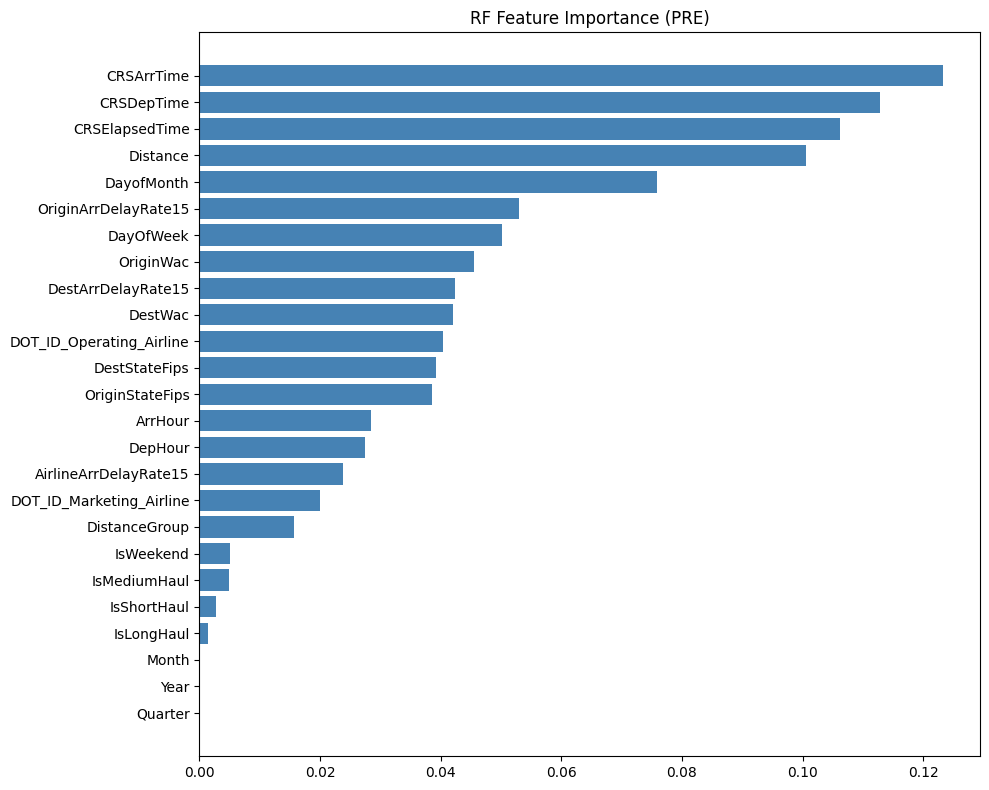

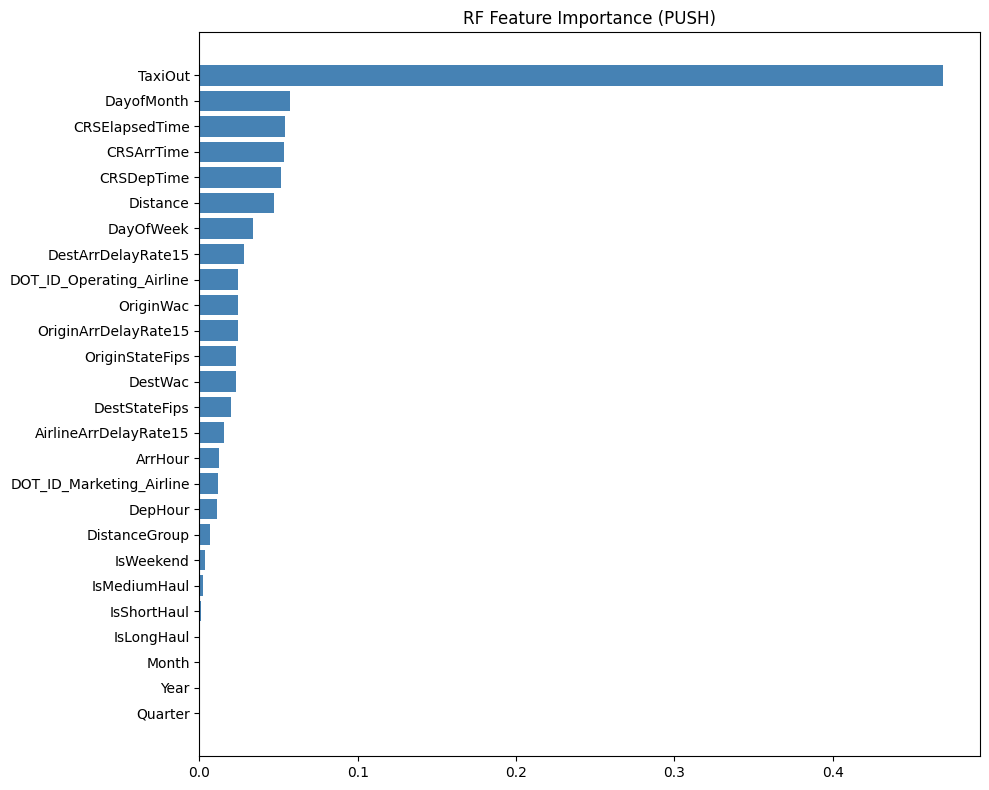

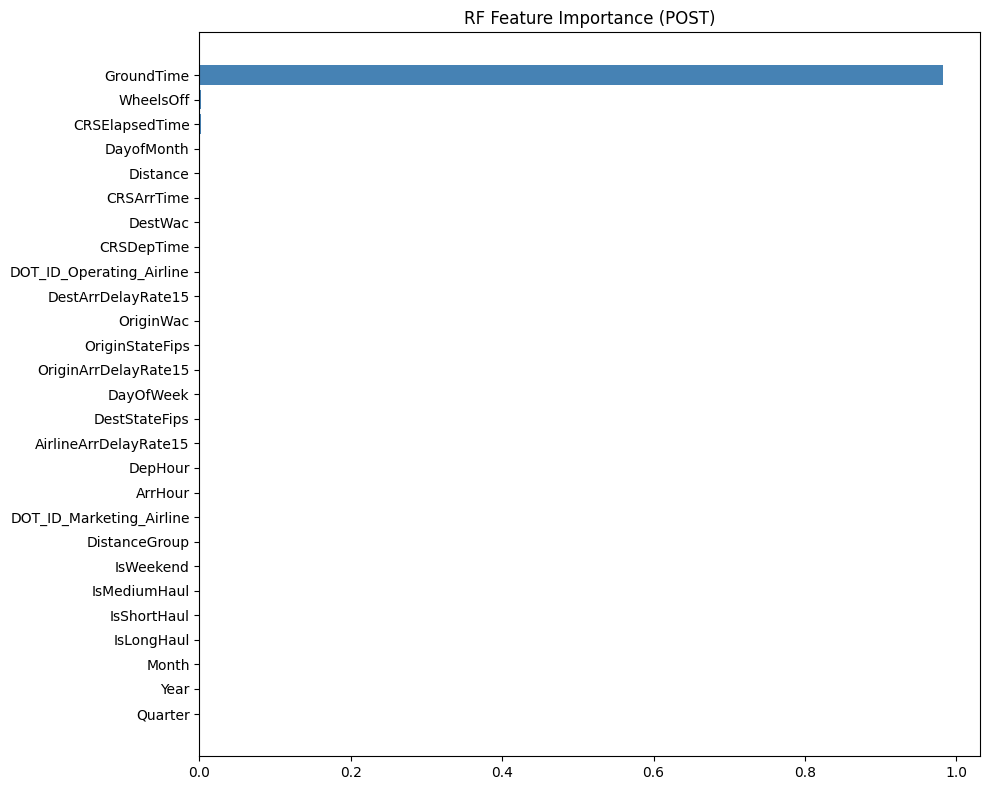

In [58]:
# Rebuild regression-only stages
# Each tuple contains:
# (stage, Xtr_s, Xte_s, Xtr_o, Xte_o, ytr, yte)

stages_reg = [
    ("PRE",  X_train_pre_scaled,  X_test_pre_scaled,  X_train_pre_ord,  X_test_pre_ord,  y_train_pre,  y_test_pre),
    ("PUSH", X_train_push_scaled, X_test_push_scaled, X_train_push_ord, X_test_push_ord, y_train_push, y_test_push),
    ("POST", X_train_post_scaled, X_test_post_scaled, X_train_post_ord, X_test_post_ord, y_train_post, y_test_post)
]

# Build regression dataset dictionary from regression-only stages
reg_datasets = {
    stage: (Xtr_s, Xte_s, Xtr_o, Xte_o, ytr, yte)     # map stage → its 6 regression components
    for stage, Xtr_s, Xte_s, Xtr_o, Xte_o, ytr, yte   # unpack the 7‑item tuple
    in stages_reg                                     # use regression-only list
}


# Random Forest Feature Importance

from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import numpy as np

for ds, (Xtr_s, Xte_s, Xtr_o, Xte_o, ytr, yte) in reg_datasets.items():

    # Train a Random Forest on ordinal features
    rf = RandomForestRegressor(
        n_estimators=300,        # number of trees
        random_state=42,         # reproducibility
        n_jobs=-1                # use all CPU cores
    ).fit(Xtr_o, ytr)

    # Sort feature importances in descending order
    f_sorted, i_sorted = sort_imp(rf, Xtr_o.columns)

    # Plot feature importances
    plt.figure(figsize=(10,8))                          # figure size
    plt.barh(f_sorted, i_sorted, color='steelblue')     # horizontal bar chart
    plt.gca().invert_yaxis()                            # highest importance at top
    plt.title(f"RF Feature Importance ({ds})")          # label with stage name
    plt.tight_layout()                                  # clean spacing
    plt.show()                                          # display plot


## Time and Resource Consumption (Training and Predictions)
This code measures how expensive each regression model is to train and run across the PRE, PUSH, and POST datasets. For every model, it selects the correct feature set, fits the model, and records both the training time and the peak memory used during that fit. It then repeats the process for prediction, capturing how long inference takes and how much memory the model allocates while generating outputs. The result is a clear, repeatable benchmark that shows the computational footprint of each model at every stage of the pipeline.

Output:

These compute results make the pattern pretty clear. LinearRegression stays fast and lightweight across all three datasets. KNN is the opposite — training is cheap, but prediction is slow every single time and always uses the most memory. RandomForest is heavy during training but quick at prediction, while GradientBoosting hits a nice balance with reasonable training time and very fast inference. The Baseline model is basically free. Overall, the ensemble models give us the best trade‑off, and KNN gives us the worst.

In [59]:
# Regression Resource Benchmarking (PRE/PUSH/POST)

import time
import tracemalloc

# build regression datasets dictionary
datasets = {
    "PRE":  (X_train_pre_scaled,  X_test_pre_scaled,  X_train_pre_ord,  X_test_pre_ord,  y_train_pre,  y_test_pre),
    "PUSH": (X_train_push_scaled, X_test_push_scaled, X_train_push_ord, X_test_push_ord, y_train_push, y_test_push),
    "POST": (X_train_post_scaled, X_test_post_scaled, X_train_post_ord, X_test_post_ord, y_train_post, y_test_post)
}

for ds, (Xtr_s, Xte_s, Xtr_o, Xte_o, ytr, yte) in datasets.items():

    print(f"\n\n==================== {ds} DATASET ====================")

    for model_name, (kind, model) in models.items():

        print(f"\n=== {model_name} ===")

        Xtr = Xtr_s if kind=="scaled" else Xtr_o          # choose train set
        Xte = Xte_s if kind=="scaled" else Xte_o          # choose test set

        # --- Training ---
        tracemalloc.start()
        start = time.time()

        model.fit(Xtr, ytr)

        train_time = time.time() - start
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        mem_train = peak / (1024**2)

        print("Training:")
        print(f"  Time        : {train_time:.6f} sec")
        print(f"  Memory Used : {mem_train:.4f} MiB")

        # --- Prediction ---
        tracemalloc.start()
        start = time.time()

        preds = model.predict(Xte)

        pred_time = time.time() - start
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        mem_pred = peak / (1024**2)

        print("\nPrediction:")
        print(f"  Time        : {pred_time:.6f} sec")
        print(f"  Memory Used : {mem_pred:.4f} MiB")




==================== PRE DATASET ====================

=== LinearRegression ===
Training:
  Time        : 0.314988 sec
  Memory Used : 28.5476 MiB

Prediction:
  Time        : 0.040490 sec
  Memory Used : 4.9374 MiB

=== KNN_5 ===
Training:
  Time        : 0.048196 sec
  Memory Used : 27.4306 MiB

Prediction:
  Time        : 11.241642 sec
  Memory Used : 9.1442 MiB

=== KNN_7 ===
Training:
  Time        : 0.015192 sec
  Memory Used : 27.4286 MiB

Prediction:
  Time        : 11.439131 sec
  Memory Used : 9.1442 MiB

=== RandomForest ===
Training:
  Time        : 82.303033 sec
  Memory Used : 20.5730 MiB

Prediction:
  Time        : 0.693996 sec
  Memory Used : 6.8595 MiB

=== GradientBoosting ===
Training:
  Time        : 19.143916 sec
  Memory Used : 20.5734 MiB

Prediction:
  Time        : 0.063240 sec
  Memory Used : 6.8594 MiB

=== Baseline ===
Training:
  Time        : 0.001848 sec
  Memory Used : 0.0040 MiB

Prediction:
  Time        : 0.000414 sec
  Memory Used : 0.3661 MiB


=

## Training Loss
This code computes the total training loss for each regression model on the POST dataset using a simple squared‑error loop. For every model, it selects the correct POST feature set, runs each training row through the model one at a time, and accumulates the squared difference between the prediction and the true value. The result is a straightforward, model‑agnostic way to measure how tightly each model fits the POST training data, giving you a consistent baseline loss value across the entire set of regressors.

Output:

These POST training‑loss numbers make the separation between the models really obvious. The ensemble models stay controlled, with RandomForest landing extremely low and GradientBoosting not far behind. LinearRegression sits in the middle with a reasonable loss. KNN, though, completely blows up — both versions jump to massive loss values, showing again that POST is not a good fit for neighborhood‑based methods. The Baseline loss is huge, which is exactly what we expect.

In [60]:
import pandas as pd
import numpy as np

def squared_error(pred, actual):                                   # simple squared error
    return (pred - actual) ** 2

def training_loss(model, X, y):                                    # compute total training loss
    cols = X.columns                                               # feature names
    total = 0                                                      # accumulator
    for x, actual in zip(X.values, y.values):                      # loop rows
        x_df = pd.DataFrame([x], columns=cols)                     # reshape row
        pred = model.predict(x_df)[0]                              # model prediction
        total += squared_error(pred, actual)                       # accumulate loss
    return total                                                   # return total loss

Xtr_s, Xte_s, Xtr_o, Xte_o, ytr, yte = datasets["POST"]            # unpack POST dataset only

print("\n===== POST TRAINING LOSS =====")                           # dataset header

for model_name, (kind, model) in models.items():                   # loop all models
    X = Xtr_s if kind == "scaled" else Xtr_o                       # choose scaled or ordinal
    loss = training_loss(model, X, ytr)                            # compute loss
    print(f"{model_name}: {loss}")                                 # print result



===== POST TRAINING LOSS =====
LinearRegression: 6781360.465832916
KNN_5: 74922112.07999991
KNN_7: 96115013.26530765
RandomForest: 930605.9440000006
GradientBoosting: 4775627.239387816
Baseline: 306513729.1759794


## Conclusion for Regression

Overall the results show a clear progression in how much signal each stage gives the models. PRE does not offer anything useful, so everything stays close to the baseline no matter what you run. Once you move into PUSH the models finally start learning real structure, and Gradient Boosting comes out as the most stable and reliable while KNN keeps overfitting. POST is where everything comes together. The feature set is strong, the fits are consistent, and Gradient Boosting ends up delivering the best overall performance with Linear Regression and Random Forest right behind it. The same pattern shows up in every metric and the message is clear. Stronger features lead to stronger models, and POST is the point where the information is finally rich enough for the system to predict reliably.

From this group I would choose Gradient Boosting as the final model. It is the most consistent across PUSH, PULL, and POST, it avoids the heavy overfitting you see in Random Forest, and it handles linear structure without needing much tuning.


# Final Conclusion: Why This Model?
I would choose Gradient Boosting as the final model for both tasks because it is the only one that stays strong and consistent across every dataset and every type of prediction. It avoids the overfitting issues that show up in KNN, and it is more stable than Random Forest when the feature space is not perfect. It handles complex patterns without needing heavy tuning, and it keeps its performance steady even when the data shifts between datasets. That makes it the safest and most reliable option out of the entire group.

Gradient Boosting works by building a series of small decision trees where each new tree focuses on the mistakes made by the previous ones. Instead of trying to learn everything in one step, it improves the model gradually by correcting the remaining errors. Each tree is simple on its own, but once they are combined the model can capture subtle patterns and interactions in the data. This step by step correction process is what gives it strong accuracy for classification and strong fit for regression, and it is the reason it stands out as the best overall choice.

# What I Learned

Working through these models showed me how much the quality of the features controls everything. When the data does not carry enough signal the models cannot learn anything meaningful, and even the stronger methods end up sitting near the baseline. Once the features improve the models finally start to pick up real structure, and the differences between weak and strong learners become obvious. I also learned how important it is to watch for overfitting, because some models look great in training but fall apart as soon as they are tested. The tree based methods were the most stable, and Gradient Boosting stood out because it stayed consistent across both tasks and their datasets. Seeing how it improves step by step by correcting the remaining errors helped me understand why it performs so well.

Another major lesson was how important it is to plan out the notebook before running anything. Some cells can take a very long time to finish, and the loss cell in particular took more than two hours to run. That experience made it clear that outlining the workflow, knowing the order of the steps, and understanding the goals of each section is not optional. Good planning saves time, prevents wasted runs, and keeps the entire process organized. Overall the work showed me how model behavior changes as the data gets better, and how a well structured notebook makes the whole process smoother and more efficient.

# Citations
Datasets

  Huynh, M. N. (2024). Seattle Flight Delay and Weather Prediction Dataset [Data set]. Kaggle. https://www.kaggle.com/datasets/minhnhathuynh/seattle-flight-delay-and-weather-prediction-dataset/data


  Singh, S. (2024). Flight Delay Dataset 2018–2024 [Data set]. Kaggle. https://www.kaggle.com/datasets/shubhamsingh42/flight-delay-dataset-2018-2024


Core Machine Learning Documentation

  
  Python Software Foundation. (2024). Python 3 documentation. https://docs.python.org/


  Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., et al. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825–2830. https://scikit-learn.org/stable


  Pandas Development Team. (2024). Pandas documentation. https://pandas.pydata.org/


  NumPy Developers. (2024). NumPy documentation. https://numpy.org/


  Hunter, J. D., & Matplotlib Development Team. (2024). Matplotlib documentation. https://matplotlib.org/


Machine Learning Text


  uCertify. (2024). Machine Learning with Python (CompTIA CertMaster / uCertify Courseware). uCertify, Inc.
